# Context and background
This notebook presents a dataset containing backscattered signals of 16 different Chipless RFID tags. Chipless RFID is a promising technology for identification and sensing purposes. During the two last decades, many researches have been dedicated to this technology, and it is still a very active area of research.

Measurements were collected at different distance ranges between the tag and the antenna (50-80 cm; 80-110cm; 110-140cm). Random inclinations were manuallly included while performing the measurements. The interval at which is measurement was taken is included for each sample.

Because of the simplicity of chipless RFID tags (they do not contain any electronics), their backscattered signals are very sensitive to any source of distorsions. Traditional digital signals processing (DSP) cannot achieve satisfying results in some extrem cases. For that reason, here **we combine DSP techniques with machine learning (ML) algorithms for classification**.

The measurements, containing both amplitude and phase information, were transformed with the Inverse Fourier Transform (IFT) and time-gating, followed by the Continuous Wavelet Transform (CWT). The resulting output is a representation of the signal in the time-frequency domain, in an image-like representation.

Datasets of the resulting signals of 16 chipless RFID tags backscattered signals are presented here.

In [ ]:
# Standard libraries
import numpy as np
import pickle     # to load and save pickle files.
import random
import re         # use to extract the binary codes from the labels

import matplotlib.pyplot as plt

The **chipless RFID tags** are coded to have notches in the range 1.5 to 5 GHz. The frequency bandwidth is divided in the following five subbands:
1.5 - 2.3 - 2.8 - 3.4 - 4.2 - 5.

The backscattered signal can contain a notch or not in each subband. The presences of a notch is coded as '1' and the absence is coded as '0', leading to a binary code (e.g., 00100 would indicate a notch only in the subband 2.8 - 3.4).

The tags also have different sizes because the resonators are repeated in a matrix way. For example, a tag named 'tag_01110_3x3' has three notches in the subbands 2.3 - 2.8, 2.8 - 3.4 and 3.4 - 4.2; and the resonators used to make the tags are repeated in a 3x3 matrix shape.



The next function is used for illustration purposes. Given an input (s), the function deduces the subbands that contains notches.

In [ ]:
def extract_notches_bounds(s):
    notches_bounds = np.array([1.52, 2.3, 2.8, 3.4, 4.2, 4.99])*10**9
    match = re.search(r'_(\d+)_', s)

    if match:
        code = match.group(1)

        # Convert to a NumPy array of booleans (1 -> True, 0 -> False)
        bool_array = np.array([bool(int(digit)) for digit in code])

        notches_indices = np.where(bool_array)[0]
        bounds_indices = set()
        for idx in notches_indices:
            bounds_indices.add(idx)
            bounds_indices.add(idx + 1)

        return notches_bounds[list(bounds_indices)]

## Datasets
There are 3 datasets:
- One made of measurements made in a very controlled environment (only for visualization purposes).
- Two others made of measurements recorded in real-world environments. These are used to train and test the ML algorithms.

The datasets are stored as dictionaries saved as pickle (.pkl) files. The keys of the dictionnaries are:
- 'images' (the CWT output and main input to the models)
- 'labels' (the tags' names) -> What we want to predict. As explained above, they come in the form of 5-bit labels ('00101' for example).
- 'intervals' (the distance between the tag and the antenna) -> Information that you may optionall use. The smallest the distance, the less interference, and hence the less noisy the signal.
- 'freq' (the frequency vector) -> Each initial measurement contains 1,601 samples that correspond to frequencies in the interval 1.5 - 5 GHz. For the purpose of this work they can be ommited.

The measurements made in the controlled environment are made at fixed distances.

### Clean (reference) measurements

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path_files='/content/drive/MyDrive/TECNUN 2026-27/DeepLearning_1cuatri/Deep_Learning_Final_proyect/'

In [ ]:
#Loading clean measurements (references)
with open(path_files + 'cwt_references_final.pkl', 'rb') as file:
    data_ref = pickle.load(file)

In [ ]:
data_ref.keys()

dict_keys(['images', 'labels', 'intervals', 'freq'])

In [ ]:
images_ref = data_ref['images']
labels_ref = data_ref['labels']
interv_ref = data_ref['intervals']
frequences = data_ref['freq'].ravel()

In [ ]:
# number of images, height and width of the images
n, h, w = images_ref.shape

In [ ]:
print(f'Number of reference images: {n}')
print(f'Height of the images: {h}')
print(f'Width of the images: {w}')

Number of reference images: 80
Height of the images: 1601
Width of the images: 57


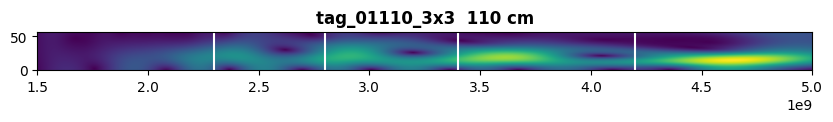

In [ ]:
#A very ideal case
fig, ax = plt.subplots(figsize=(10,0.5))

idx = 20
ax.imshow(images_ref[idx].T, origin='lower', aspect='auto', extent=[frequences[0], frequences[-1], 0, w])
ax.set_title(labels_ref[idx] + '  ' + interv_ref[idx][-3:] + ' cm', fontsize=12, fontweight='bold')

notches = extract_notches_bounds(labels_ref[idx])

#Highlighting the expected notch frequencies
for vline in notches:
        ax.axvline(vline, color='white')

In this very ideal cases (very clean measurement, without interferences and/or noise) we can see how the CWT output looks like (for illustration purposes, here the image is transposed).

The presented tag is 'tag_01110_3x3'. The vertical white lines delimite the subbands where the notches should appear (they have been added manually for illustration purposes). The notches are represented as areas of low energy (blue color) withing an area of high energy (yellow color). In the image they appear as eliptical blue forms.

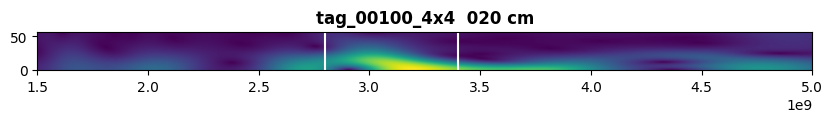

In [ ]:
#Other references
fig, ax = plt.subplots(figsize=(10,0.5))

idx = random.randrange(n)
ax.imshow(images_ref[idx].T, origin='lower', aspect='auto', extent=[frequences[0], frequences[-1], 0, w])
ax.set_title(labels_ref[idx] + '  ' + interv_ref[idx][-3:] + ' cm', fontsize=12, fontweight='bold')

notches = extract_notches_bounds(labels_ref[idx])

#Highlighting the expected notch frequencies
for vline in notches:
        ax.axvline(vline, color='white')

The measurements are not always so clear, even in controlled environments. The code above will depict a random measurement of the dataset. At each run a different measurement may be depicted.

### Training set
In this section we illustrate some of the measurements obtained from a realistic set-up. In this case identifying a tag based on the backscattered signal gets more complicated due to environmental noise and intereferences.

In [ ]:
with open(path_files + 'cwt_training_final.pkl', 'rb') as file:
    data_training = pickle.load(file)

In [ ]:
images_training = data_training['images']
labels_training = data_training['labels']
interv_training = data_training['intervals']

In [ ]:
images_training.shape

(4800, 1601, 57)

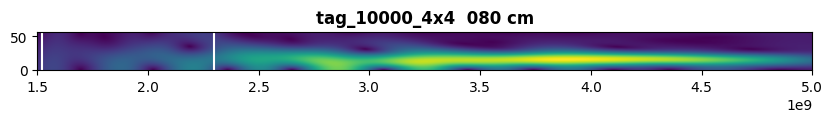

In [ ]:
# Measurement in a real-world environment
fig, ax = plt.subplots(figsize=(10,0.5))

idx = random.randrange(images_training.shape[0])
ax.imshow(images_training[idx].T, origin='lower', aspect='auto', extent=[frequences[0], frequences[-1], 0, w])
ax.set_title(labels_training[idx] + '  ' + interv_training[idx][-3:] + ' cm', fontsize=12, fontweight='bold')

notches = extract_notches_bounds(labels_training[idx])

#Highlighting the expected notch frequencies
for vline in notches:
        ax.axvline(vline, color='white')

The training dataset has been collected to train AI models so that they can accurately predict a chiples RFID tag based on the collected backscattered signal in a real-world condition.

### Test set
The following set is used only for testing. The goal is to generate correct labels for these measurements, BUT note that you do not have access to the labels.

In [ ]:
with open(path_files +'cwt_testing_final_unlabeled_with_intervals.pkl', 'rb') as file:
    data_testing = pickle.load(file)

In [ ]:
images_test = data_testing['images']
interv_test = data_testing['intervals']

In [ ]:
# This gives an error since labels for the test set are not available
# labels_test = data_testing['labels']

# Our work: overview

The cells above are the template provided with the assignment: they describe the chipless RFID tags, how the labels are built from the notches and the three datasets. **Everything from section 1 onwards is our work.** Section 1 loads the data again on its own, so the notebook can be run from that point.

**Problem.** Each of the 16 chipless RFID tags reflects the radar signal with a different combination of notches in five frequency sub-bands (1.5-5 GHz), which defines its 5-bit code. The model receives the Continuous Wavelet Transform (CWT) of a real-world measurement (1601 frequencies x 57 scales) taken at 50-140 cm from the antenna, and must identify the tag. We have 4,800 labelled training measurements (300 per tag) and must predict the labels of 2,400 unlabelled test measurements.

**Approach.** We treated the project as an experimental study. Every model is evaluated with the same stratified 5-fold cross-validation, and every decision is taken from those results, never from the test set.

| Section | Content | Main result |
|---|---|---|
| 1-2 | Setup and exploratory analysis | Balanced data; the distance adds noise but does not change the pattern of each tag |
| 3 | Data leakage check | No leakage: a stratified random split is a valid proxy for the test set |
| 4 | Preprocessing | Frequency downsampling x4 (400 x 57) and per-position normalisation; fixed 5 folds |
| 5 | Baselines (DSP templates, nearest neighbour, PCA + SVM / logistic regression) | Best baseline: 1-NN, 91.2% |
| 6 | Neural networks: MLP vs 1D CNN, class output vs 5-bit output | 96.0%; the 1D CNN is 3 times smaller than the MLP |
| 7 | 2D CNN and scale-shuffling ablation | Discarded: the information is positional along frequency |
| 8 | Multi-task network (class + bits) | Discarded: the bits add no new information |
| 9 | Data augmentation, interval as input, regularisation, Optuna | Label smoothing is the only clear gain: 96.6% |
| 10 | Transformer, transfer learning (ImageNet), pseudo-labelling | No single model beats the CNN; EfficientNet ties with it |
| 11 | Final model: ensemble of 4 networks, test prediction | **97.4%** in cross-validation; `test_predictions.txt` |
| 12 | Analysis: errors, calibration, Grad-CAM, t-SNE | Errors concentrated in the 1x1 tags at long distance |
| 13 | Final conclusions | |

**Frameworks.** TensorFlow / Keras for the neural networks, scikit-learn for the baselines and the cross-validation, Optuna for the hyper-parameter search.

# 1. Setup and data loading

This section prepares the working environment and loads the three datasets provided with the project:

| Dataset | File | Samples | Use |
|---|---|---|---|
| References | `cwt_references_final.pkl` | 80 | Clean measurements (5 per tag), only for visualisation and as class templates |
| Training | `cwt_training_final.pkl` | 4800 | Labelled real-world measurements used to train and validate the models |
| Test | `cwt_testing_final_unlabeled_with_intervals.pkl` | 2400 | Unlabelled real-world measurements whose labels we must predict |

**Design decisions**
- All imports, constants and the data loading are gathered in a single cell, so the notebook can be re-run from this point without depending on the exploratory cells above.
- All random seeds are fixed for reproducibility.
- The images are stored as `uint8` (~440 MB for the training set). We keep this format when loading to save RAM, and convert to `float32` later, during preprocessing.
- The runtime uses a GPU (an A100 in Colab), needed to train the neural networks in later sections.
- We also define the edges of the five frequency sub-bands that encode the 5-bit label of each tag, since they are used throughout the notebook.

In [ ]:
# The datasets are stored in our Google Drive folder
from google.colab import drive
drive.mount('/content/drive')

import os        # file-system utilities (check that the data files exist)
import gc        # garbage collector, used to free RAM after deleting large objects
import pickle    # the datasets are stored as pickled Python dictionaries
import random    # Python's random number generator (seeded for reproducibility)
import re        # regular expressions, used to extract the 5-bit code from the labels

import numpy as np                # numerical arrays
import pandas as pd               # tables for summaries and results
import matplotlib.pyplot as plt   # plots

import tensorflow as tf

# Fix every random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Folder in Google Drive that contains the three .pkl files
path_files = '/content/drive/MyDrive/TECNUN 2026-27/DeepLearning_1cuatri/Deep_Learning_Final_proyect/'
FILE_REF   = 'cwt_references_final.pkl'
FILE_TRAIN = 'cwt_training_final.pkl'
FILE_TEST  = 'cwt_testing_final_unlabeled_with_intervals.pkl'

# Stop early with a clear message if any of the files is missing
for f in [FILE_REF, FILE_TRAIN, FILE_TEST]:
    assert os.path.exists(path_files + f), f'File not found: {path_files + f}'

# Edges (in GHz) of the 5 sub-bands: bit i of a label = 1 if there is a notch in sub-band i
SUBBAND_EDGES_GHZ = [1.5, 2.3, 2.8, 3.4, 4.2, 5.0]
N_BITS = 5


def load_pickle(filename):
    """Load one of the dataset dictionaries from the data folder."""
    with open(path_files + filename, 'rb') as f:
        return pickle.load(f)


data_ref   = load_pickle(FILE_REF)     # 80 clean measurements (5 per tag)
data_train = load_pickle(FILE_TRAIN)   # 4800 labelled real-world measurements
data_test  = load_pickle(FILE_TEST)    # 2400 unlabelled real-world measurements

# Images keep their original uint8 type for now; they are converted to float32 in preprocessing
X_ref,   y_ref_names,   int_ref   = data_ref['images'],   np.asarray(data_ref['labels']),   np.asarray(data_ref['intervals'])
X_train, y_train_names, int_train = data_train['images'], np.asarray(data_train['labels']), np.asarray(data_train['intervals'])
X_test,  int_test                 = data_test['images'],  np.asarray(data_test['intervals'])   # the test set has no labels
freqs = data_ref['freq'].ravel()   # frequency axis in Hz (1601 points between 1.5 and 5 GHz)

# The original dictionaries are no longer needed: free the memory
del data_ref, data_train, data_test
gc.collect()

# Sorted list of the 16 classes (tag names)
CLASS_NAMES = np.unique(y_train_names)
N_CLASSES = len(CLASS_NAMES)

# Summary table of what has been loaded
unique_str = lambda a: sorted(str(v) for v in set(a))   # helper: unique values as plain strings
summary = pd.DataFrame({
    'images shape': [X_ref.shape, X_train.shape, X_test.shape],
    'dtype':        [X_ref.dtype, X_train.dtype, X_test.dtype],
    'size (MB)':    [round(a.nbytes / 1e6, 1) for a in (X_ref, X_train, X_test)],
    'n classes':    [len(np.unique(y_ref_names)), N_CLASSES, 'unknown'],
    'intervals':    [unique_str(int_ref), unique_str(int_train), unique_str(int_test)],
}, index=['reference', 'train', 'test'])
display(summary)

print(f'Frequency axis: {freqs[0]/1e9:.2f} - {freqs[-1]/1e9:.2f} GHz ({len(freqs)} points)')
print(f'Classes ({N_CLASSES}):', CLASS_NAMES.tolist())
print('TensorFlow', tf.__version__, '| GPU available:', tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,images shape,dtype,size (MB),n classes,intervals
reference,"(80, 1601, 57)",uint8,7.3,16,"[000_020, 000_050, 000_080, 000_110, 000_140]"
train,"(4800, 1601, 57)",uint8,438.0,16,"[050_080, 080_110, 110_140]"
test,"(2400, 1601, 57)",uint8,219.0,unknown,"[050_080, 080_110, 110_140]"


Frequency axis: 1.50 - 5.00 GHz (1601 points)
Classes (16): ['tag_00001_4x4', 'tag_00010_2x2', 'tag_00100_4x4', 'tag_00111_2x2', 'tag_01000_2x2', 'tag_01011_4x4', 'tag_01101_1x1', 'tag_01110_3x3', 'tag_10000_4x4', 'tag_10011_2x2', 'tag_10101_4x4', 'tag_10110_1x1', 'tag_11001_2x2', 'tag_11010_3x3', 'tag_11100_1x1', 'tag_11111_1x1']
TensorFlow 2.21.0 | GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2. Exploratory data analysis (EDA)

Before designing any model we need to understand the data. This section answers four questions:
1. **Is the dataset balanced?** Classes and distance intervals, in train and test.
2. **What does each tag look like?** One raw example per class, with the five sub-bands marked.
3. **How does the distance affect the signal?** Mean image per class and per distance interval.
4. **Which bits are easy or hard to detect?** A simple per-sub-band energy feature and how well it separates bit = 1 from bit = 0.

The conclusions of this section motivate the preprocessing and modelling choices of the following sections.

## 2.1 Class and interval balance

Number of training samples for every (class, interval) pair, and number of test samples per interval (the test labels are unknown).

interval,050_080,080_110,110_140,total
class,,,,
tag_00001_4x4,100,100,100,300
tag_00010_2x2,100,100,100,300
tag_00100_4x4,100,100,100,300
tag_00111_2x2,100,100,100,300
tag_01000_2x2,100,100,100,300
tag_01011_4x4,100,100,100,300
tag_01101_1x1,100,100,100,300
tag_01110_3x3,100,100,100,300
tag_10000_4x4,100,100,100,300


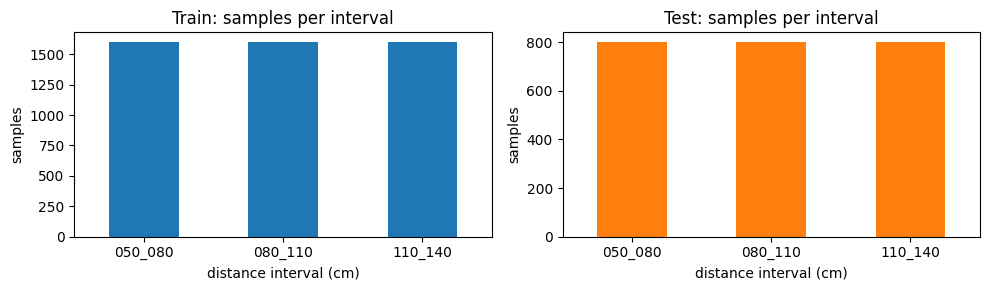

In [ ]:
# Contingency table: number of training samples for each (class, interval) pair
balance = pd.crosstab(pd.Series(y_train_names, name='class'),
                      pd.Series(int_train, name='interval'),
                      margins=True, margins_name='total')
display(balance)

# Test set: labels are unknown, so only the interval distribution can be checked
test_balance = pd.Series(int_test).value_counts().sort_index()
train_interval_counts = pd.Series(int_train).value_counts().sort_index()

# Bar plots of the interval distribution in train and test
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
train_interval_counts.plot.bar(ax=axes[0], color='tab:blue', title='Train: samples per interval')
test_balance.plot.bar(ax=axes[1], color='tab:orange', title='Test: samples per interval')
for ax in axes:
    ax.set_xlabel('distance interval (cm)')
    ax.set_ylabel('samples')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 2.2 One example per class

Each image is shown transposed (frequency on the x-axis, CWT scale on the y-axis), as in the original notebook. The white lines mark the edges of the five sub-bands and the **red bars** on top mark the sub-bands whose bit is 1, i.e. where a notch (a low-energy, blue area) is expected.

The examples are taken from the closest interval (50-80 cm), where the signal is cleanest.

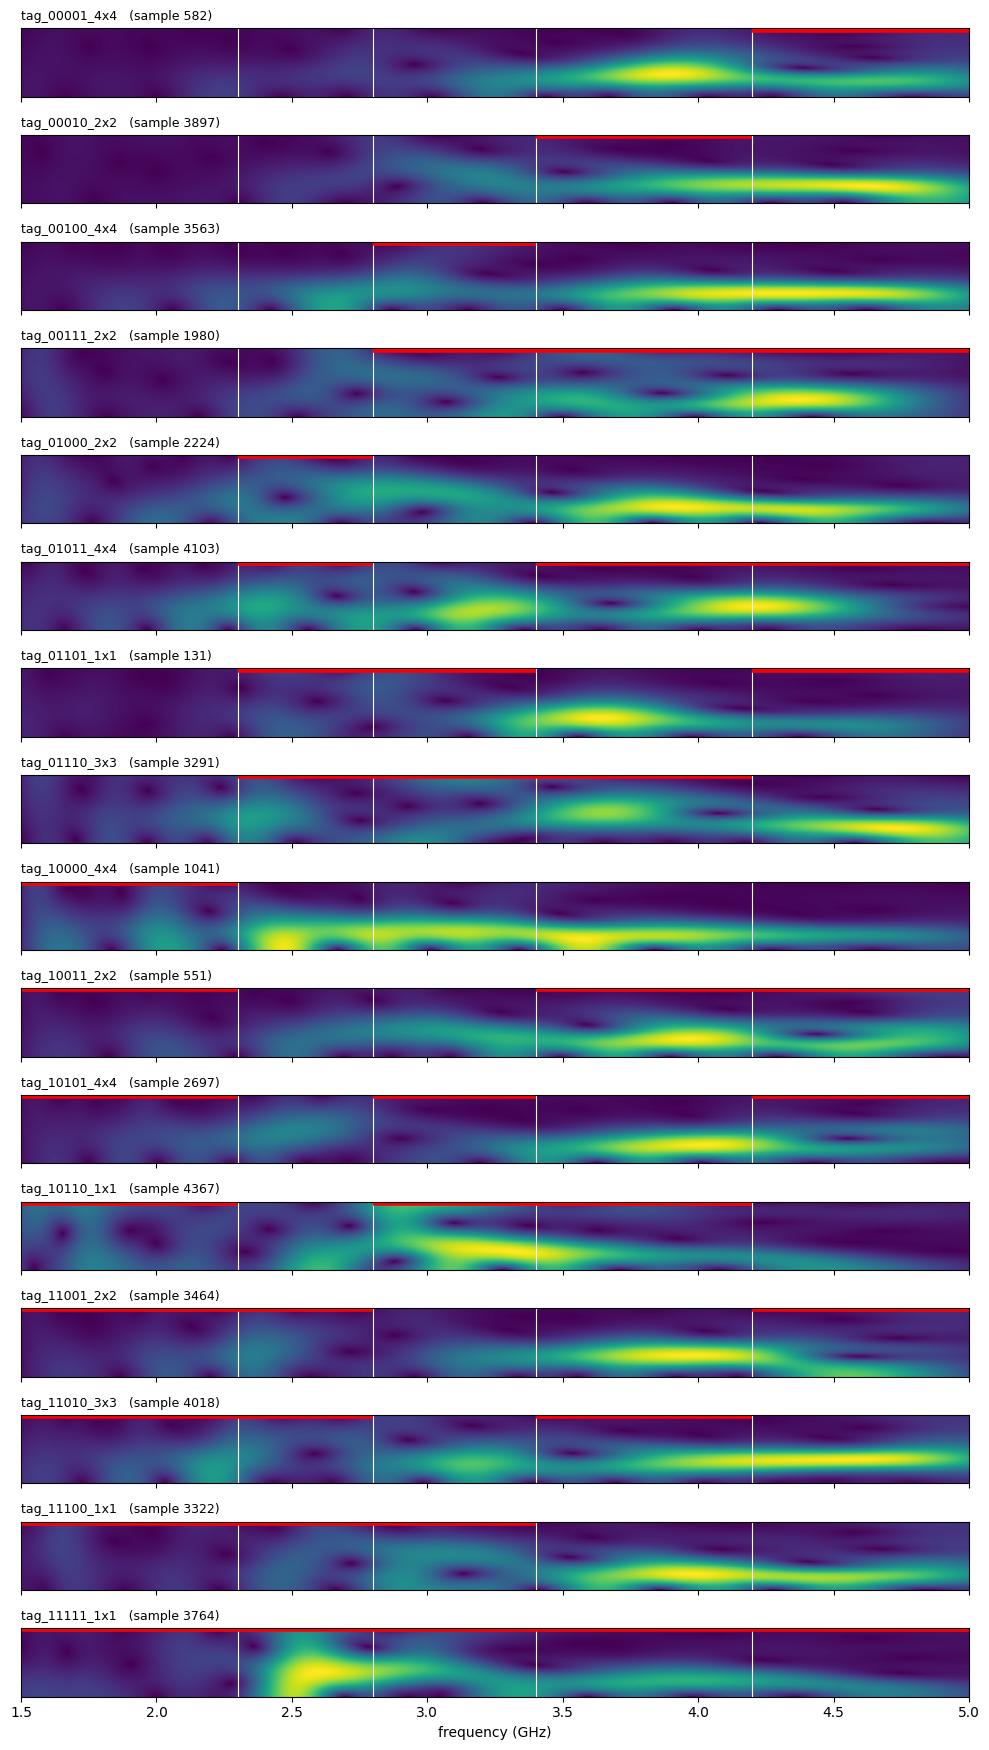

In [ ]:
def label_to_code(label):
    """Extract the 5-bit code from a tag name, e.g. 'tag_01110_3x3' -> '01110'."""
    return re.search(r'_(\d{5})_', str(label)).group(1)


def plot_cwt(ax, img, title=None, code=None):
    """Plot one CWT image transposed (frequency on x, scale on y).
    White lines = sub-band edges; red bars on top = sub-bands where the code expects a notch."""
    n_scales = img.shape[1]
    ax.imshow(img.T, origin='lower', aspect='auto',
              extent=[freqs[0] / 1e9, freqs[-1] / 1e9, 0, n_scales])
    for edge in SUBBAND_EDGES_GHZ[1:-1]:              # inner sub-band edges
        ax.axvline(edge, color='white', lw=0.8)
    if code is not None:                                # mark the expected notches
        for i, bit in enumerate(code):
            if bit == '1':
                ax.hlines(n_scales - 1, SUBBAND_EDGES_GHZ[i], SUBBAND_EDGES_GHZ[i + 1], color='red', lw=4)
    if title:
        ax.set_title(title, fontsize=9, loc='left')
    ax.set_yticks([])


rng = np.random.default_rng(SEED)   # seeded generator -> always the same examples
fig, axes = plt.subplots(N_CLASSES, 1, figsize=(10, 1.1 * N_CLASSES), sharex=True)
for ax, cls in zip(axes, CLASS_NAMES):
    # random training sample of this class from the closest interval (50-80 cm)
    candidates = np.where((y_train_names == cls) & (int_train == '050_080'))[0]
    idx = rng.choice(candidates)
    plot_cwt(ax, X_train[idx], title=f'{cls}   (sample {idx})', code=label_to_code(cls))
axes[-1].set_xlabel('frequency (GHz)')
plt.tight_layout()
plt.show()

## 2.3 Effect of the distance: mean image per class and interval

Averaging all the training images of one class removes most of the random noise and reveals the pattern that a model can learn. Comparing the three distance intervals shows how much the notches degrade when the tag is further from the antenna. The first column shows the mean of the clean reference measurements of the same tag for comparison.

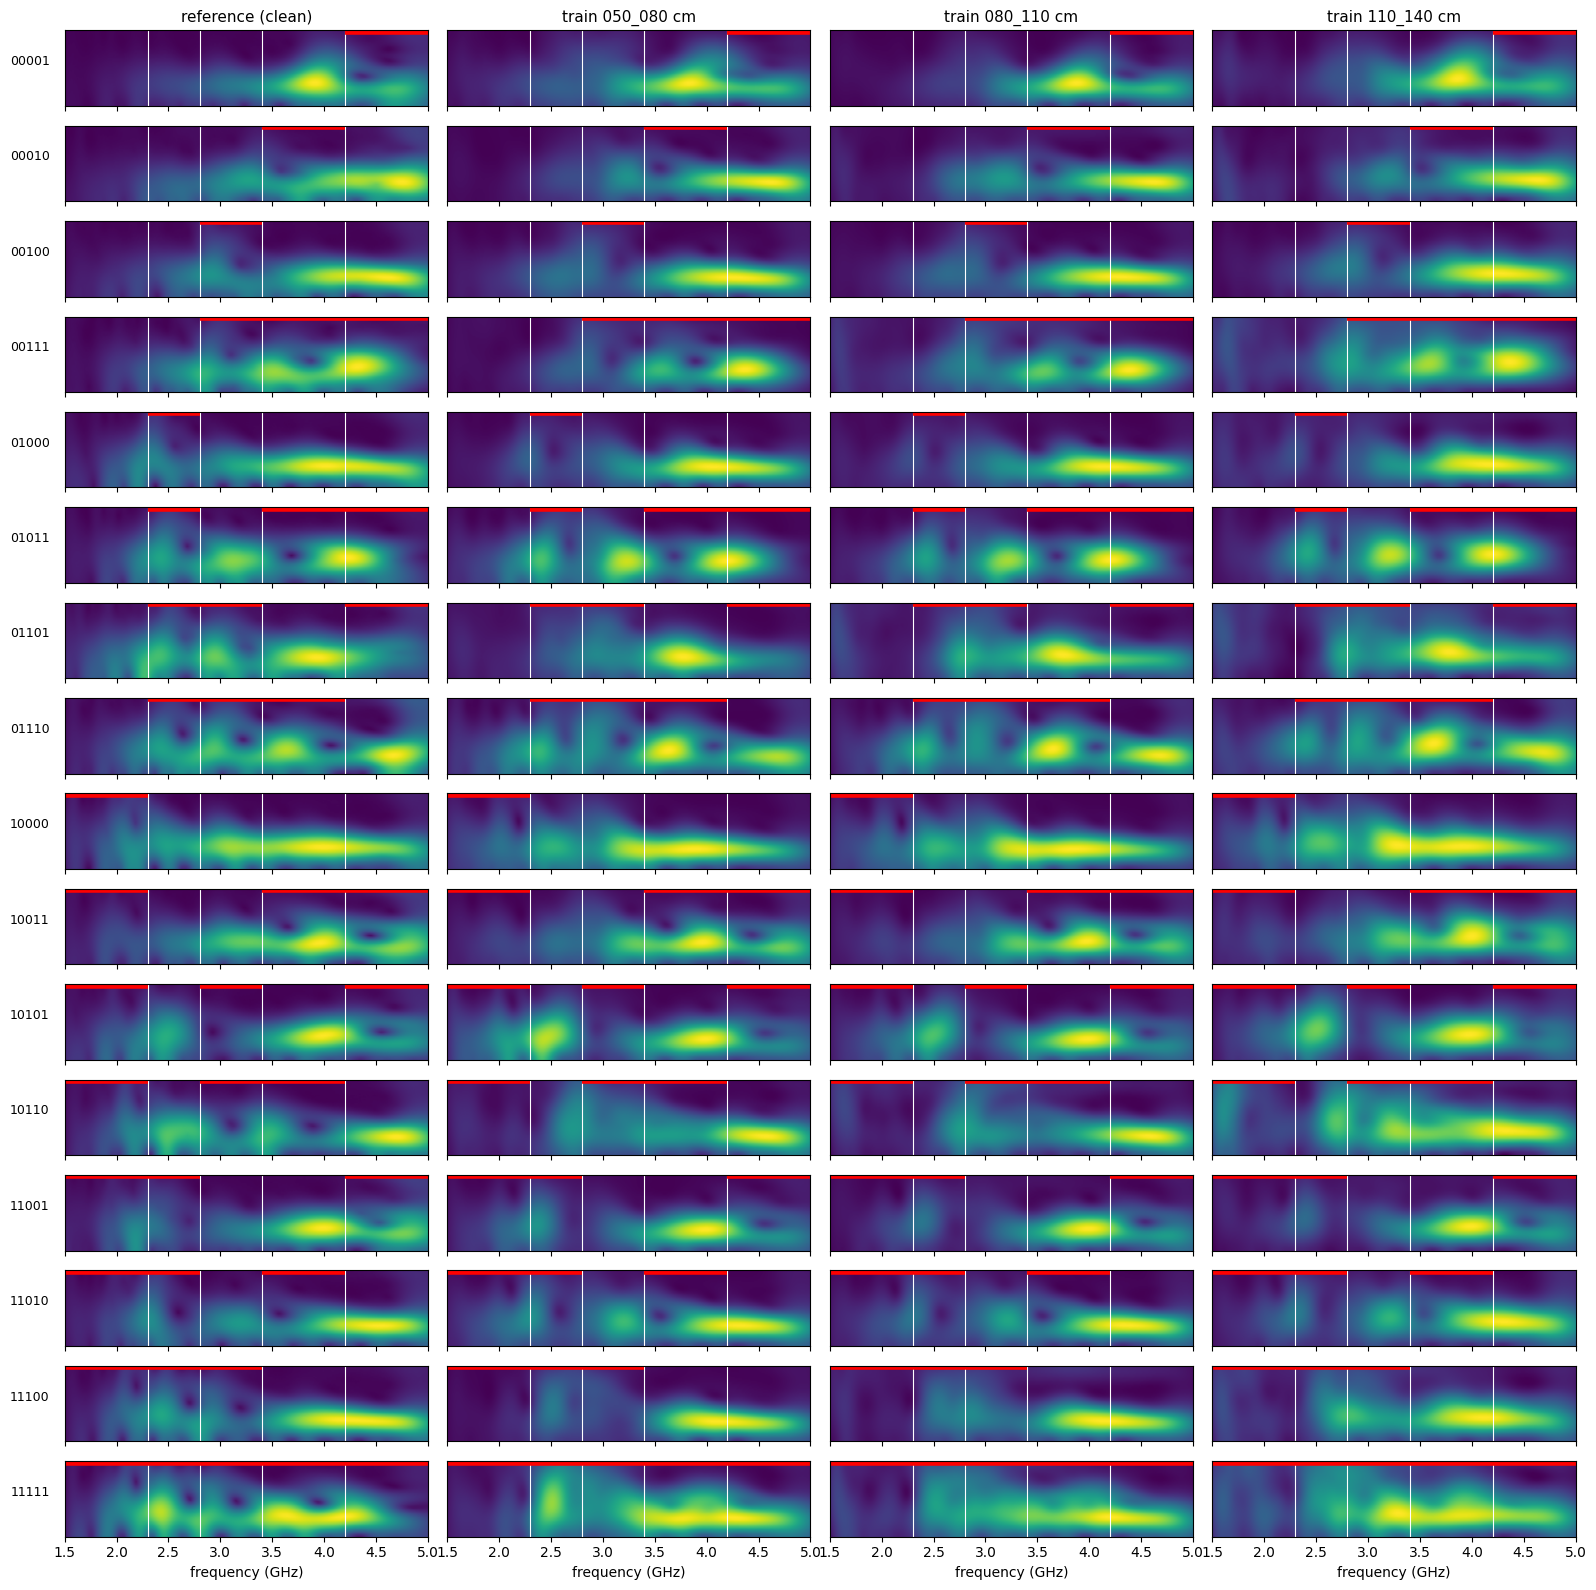

In [ ]:
INTERVALS = sorted(str(v) for v in set(int_train))   # ['050_080', '080_110', '110_140']

fig, axes = plt.subplots(N_CLASSES, 1 + len(INTERVALS), figsize=(16, 1.0 * N_CLASSES), sharex=True)
for r, cls in enumerate(CLASS_NAMES):
    code = label_to_code(cls)
    # Column 0: mean of the clean reference measurements of this tag
    plot_cwt(axes[r, 0], X_ref[y_ref_names == cls].mean(axis=0), code=code)
    # Columns 1-3: mean of the training images of this tag in each distance interval
    for c, itv in enumerate(INTERVALS, start=1):
        mask = (y_train_names == cls) & (int_train == itv)
        plot_cwt(axes[r, c], X_train[mask].mean(axis=0), code=code)
    axes[r, 0].set_ylabel(code, rotation=0, labelpad=25, fontsize=9)   # row label = 5-bit code

# Column titles
col_titles = ['reference (clean)'] + [f'train {itv} cm' for itv in INTERVALS]
for c, name in enumerate(col_titles):
    axes[0, c].set_title(name, fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel('frequency (GHz)')
plt.tight_layout()
plt.show()

## 2.4 How hard is each bit? A simple energy feature

A notch is a region of *low* energy. A very simple hand-crafted feature is therefore the mean CWT intensity inside each sub-band (averaged over all scales). If this single number already separates bit = 1 from bit = 0, the bit is easy; if it does not, a more powerful model is needed.

The separation is measured with the **ROC-AUC** (0.5 = no information, 1.0 = perfect separation), for each bit and each distance interval. This gives a first, model-free idea of which parts of the spectrum are hardest and how much the distance hurts each of them.

Frequency points per sub-band: [366, 229, 274, 366, 366]


,050_080,080_110,110_140,all
bit 1 (1.5-2.3 GHz),0.315,0.338,0.391,0.349
bit 2 (2.3-2.8 GHz),0.423,0.437,0.468,0.444
bit 3 (2.8-3.4 GHz),0.610,0.547,0.506,0.554
bit 4 (3.4-4.2 GHz),0.603,0.613,0.612,0.610
bit 5 (4.2-5.0 GHz),0.697,0.674,0.658,0.674


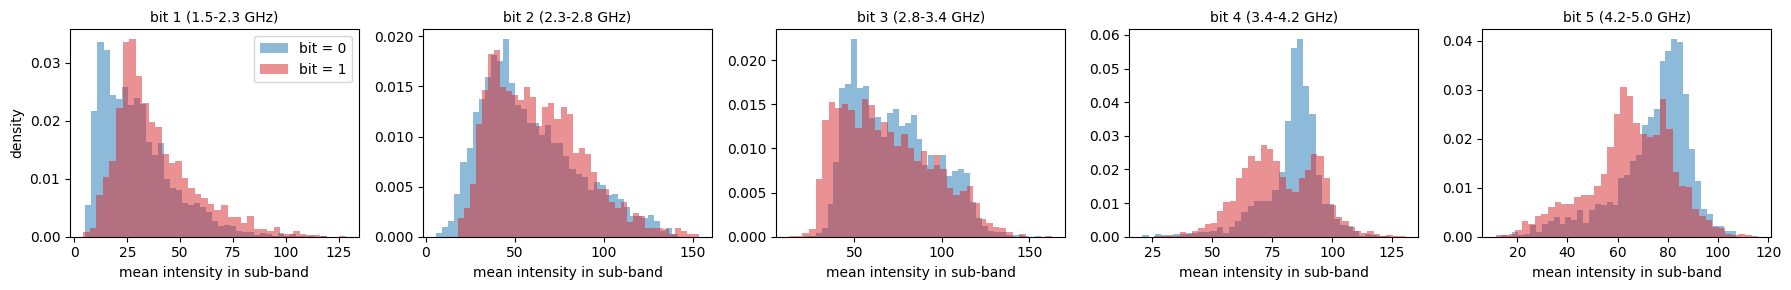

In [ ]:
from sklearn.metrics import roc_auc_score

# Frequency indices that belong to each of the 5 sub-bands
freqs_ghz = freqs / 1e9
band_idx = []
for lo, hi in zip(SUBBAND_EDGES_GHZ[:-1], SUBBAND_EDGES_GHZ[1:]):
    upper = hi if hi < SUBBAND_EDGES_GHZ[-1] else np.inf     # include the last frequency point in band 5
    band_idx.append(np.where((freqs_ghz >= lo) & (freqs_ghz < upper))[0])
print('Frequency points per sub-band:', [len(i) for i in band_idx])

# Feature: mean intensity of each training image inside each sub-band -> array (n_samples, 5)
band_energy = np.stack([X_train[:, idx, :].mean(axis=(1, 2)) for idx in band_idx], axis=1)

# True bits of every training sample -> array (n_samples, 5)
bits_train = np.array([[int(b) for b in label_to_code(l)] for l in y_train_names])

# ROC-AUC of the feature for every bit and interval.
# A notch means LOW energy, so -energy is used as the score for 'bit = 1'.
band_names = [f'bit {i + 1} ({lo}-{hi} GHz)'
              for i, (lo, hi) in enumerate(zip(SUBBAND_EDGES_GHZ[:-1], SUBBAND_EDGES_GHZ[1:]))]
auc = pd.DataFrame(index=band_names, columns=INTERVALS + ['all'], dtype=float)
for i in range(N_BITS):
    for itv in INTERVALS + ['all']:
        m = np.ones(len(int_train), dtype=bool) if itv == 'all' else (int_train == itv)
        auc.loc[band_names[i], itv] = roc_auc_score(bits_train[m, i], -band_energy[m, i])
display(auc.round(3).style.background_gradient(cmap='RdYlGn', vmin=0.5, vmax=1.0).format('{:.3f}'))

# Histograms of the feature for bit = 0 vs bit = 1 (all intervals together)
fig, axes = plt.subplots(1, N_BITS, figsize=(18, 3))
for i, ax in enumerate(axes):
    for b, color in [(0, 'tab:blue'), (1, 'tab:red')]:
        ax.hist(band_energy[bits_train[:, i] == b, i], bins=40, alpha=0.5,
                color=color, density=True, label=f'bit = {b}')
    ax.set_title(band_names[i], fontsize=10)
    ax.set_xlabel('mean intensity in sub-band')
axes[0].set_ylabel('density')
axes[0].legend()
plt.tight_layout()
plt.show()

## 2.5 EDA conclusions

1. **Perfectly balanced data.** The training set has exactly 100 samples per class and per distance interval (300 per class, 1600 per interval), and the test set has 800 samples per interval. Plain accuracy is therefore a fair metric, no class re-weighting is needed, and the validation split must be stratified by class *and* interval to keep this balance.
2. **The energy is concentrated in the upper part of the spectrum.** For every tag, most of the CWT energy lies between ~3 and 5 GHz, while the two lowest sub-bands (1.5-2.8 GHz) are dark. Intensity levels therefore differ a lot between sub-bands, which motivates a careful normalisation in preprocessing.
3. **Each class has a stable, recognisable pattern.** The mean image of each tag looks very similar in the three distance intervals and in the clean references. The distance mainly adds sample-to-sample noise rather than changing the pattern itself, so a model should be able to learn one pattern per class that generalises across distances.
4. **A notch is not just 'less energy in the sub-band'.** The simple per-sub-band mean intensity separates bit = 1 from bit = 0 poorly (ROC-AUC between 0.31 and 0.70), and for bits 1 and 2 the relation is even inverted (AUC < 0.5). The information is in the *local shape and position* of the high- and low-energy regions along frequency and scale, not in global averages.

**Consequences for the next steps**
- Hand-crafted global features are not enough, so we need models that learn local time-frequency patterns. This is a strong argument for **convolutional networks**, which we will compare against MLPs and classical baselines.
- The **position along the frequency axis** is what defines each bit, so the architectures should keep this information (e.g. avoid pooling away the frequency position too early).
- Since all four model families are trained on the same data, we will use the same preprocessing and the same stratified validation protocol for all of them.

# 3. Data leakage check

The measurements were recorded one after another. If consecutive measurements of the same tag are almost identical (for example, because the tag was barely moved between them), a random train/validation split would put near-copies of the same measurement on both sides. The validation accuracy would then be over-optimistic and would not reflect the real performance on the test set.

Before choosing the validation protocol we therefore check:
1. **How the samples are ordered** in the training file.
2. **Whether consecutive samples are more similar** than other samples of the same class and interval.
3. **How close the test samples are to the training samples**, compared with how close training samples are to each other.

As similarity measure we use the **Pearson correlation** between two images (1 = identical pattern, 0 = unrelated). To keep the computation light, the frequency axis is subsampled by 8 (1601 -> 201 points), which is enough to compare global patterns.

## 3.1 Order of the samples in the training file

If the file were sorted by tag and distance, consecutive samples would probably have been recorded one after the other. The class and interval of every sample are plotted against its position in the file, and the length of the runs of consecutive samples of the same (class, interval) group is measured.

Number of contiguous runs: 4705  |  run length: min 1, max 3, mean 1.0


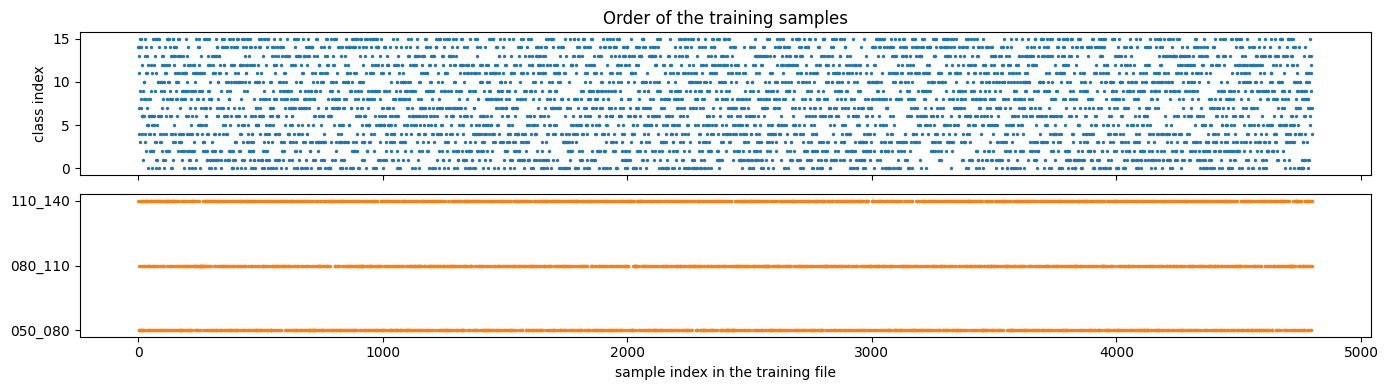

In [ ]:
y_train_idx = np.searchsorted(CLASS_NAMES, y_train_names)            # class name -> integer 0..15
int_train_idx = np.searchsorted(np.asarray(INTERVALS), int_train)   # interval   -> integer 0..2

# Group = (class, interval) pair. Find the runs of consecutive samples that belong to the same group
group_id = y_train_idx * len(INTERVALS) + int_train_idx
changes = np.flatnonzero(np.diff(group_id) != 0) + 1                 # positions where the group changes
run_lengths = np.diff(np.concatenate([[0], changes, [len(group_id)]]))
print(f'Number of contiguous runs: {len(run_lengths)}  |  run length: '
      f'min {run_lengths.min()}, max {run_lengths.max()}, mean {run_lengths.mean():.1f}')

# Plot the class and the interval of every sample against its position in the file
fig, axes = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
axes[0].scatter(np.arange(len(y_train_idx)), y_train_idx, s=2)
axes[0].set_ylabel('class index')
axes[0].set_title('Order of the training samples')
axes[1].scatter(np.arange(len(int_train_idx)), int_train_idx, s=2, color='tab:orange')
axes[1].set_yticks(range(len(INTERVALS)))
axes[1].set_yticklabels(INTERVALS)
axes[1].set_xlabel('sample index in the training file')
plt.tight_layout()
plt.show()

## 3.2 Similarity between consecutive samples

Mean correlation between pairs of samples of the same class and interval, as a function of their distance in the file (lag). If consecutive samples were near-copies of each other, the correlation would be clearly higher at lag 1 than at larger lags.

Vector size per image: 11457
Mean correlation, consecutive samples:     0.667
Mean correlation, non-consecutive samples: 0.667


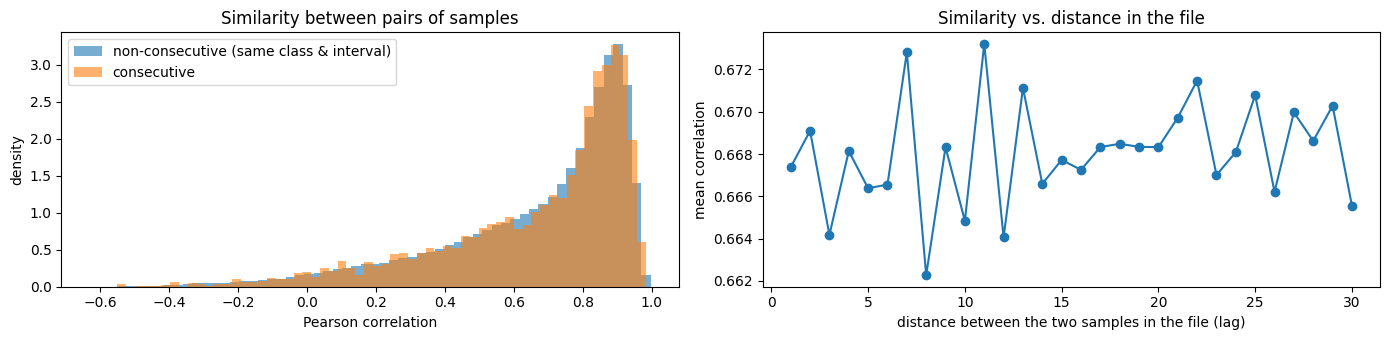

In [ ]:
def to_unit_vectors(X, step=8):
    """Flatten each image (frequency axis subsampled by `step`), remove its mean and scale it to unit norm.
    The dot product between two resulting vectors is the Pearson correlation of the two images."""
    Z = X[:, ::step, :].reshape(len(X), -1).astype(np.float32)
    Z -= Z.mean(axis=1, keepdims=True)
    Z /= np.linalg.norm(Z, axis=1, keepdims=True) + 1e-8
    return Z

Z_train = to_unit_vectors(X_train)
Z_test = to_unit_vectors(X_test)
print('Vector size per image:', Z_train.shape[1])

MAX_LAG = 30                              # largest distance in the file that we look at
lag_sum = np.zeros(MAX_LAG + 1)           # sum of correlations for each lag
lag_count = np.zeros(MAX_LAG + 1)         # number of pairs for each lag
consecutive, non_consecutive = [], []
for g in np.unique(group_id):
    idx = np.where(group_id == g)[0]      # samples of one (class, interval) group, in file order
    S = Z_train[idx] @ Z_train[idx].T     # correlation matrix inside the group
    for lag in range(1, MAX_LAG + 1):
        d = np.diagonal(S, offset=lag)    # pairs (i, i + lag)
        lag_sum[lag] += d.sum()
        lag_count[lag] += len(d)
    consecutive.append(np.diagonal(S, offset=1))               # neighbours in the file
    non_consecutive.append(S[np.triu_indices(len(idx), k=2)])  # every other pair of the group
consecutive = np.concatenate(consecutive)
non_consecutive = np.concatenate(non_consecutive)
lag_corr = lag_sum[1:] / lag_count[1:]    # mean correlation for lags 1..MAX_LAG

print(f'Mean correlation, consecutive samples:     {consecutive.mean():.3f}')
print(f'Mean correlation, non-consecutive samples: {non_consecutive.mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].hist(non_consecutive, bins=60, density=True, alpha=0.6, label='non-consecutive (same class & interval)')
axes[0].hist(consecutive, bins=60, density=True, alpha=0.6, label='consecutive')
axes[0].set_xlabel('Pearson correlation')
axes[0].set_ylabel('density')
axes[0].set_title('Similarity between pairs of samples')
axes[0].legend()
axes[1].plot(range(1, MAX_LAG + 1), lag_corr, marker='o')
axes[1].set_xlabel('distance between the two samples in the file (lag)')
axes[1].set_ylabel('mean correlation')
axes[1].set_title('Similarity vs. distance in the file')
plt.tight_layout()
plt.show()

## 3.3 Nearest neighbours: train vs train and test vs train

For every sample we find its most correlated training sample. This gives a model-free leave-one-out 1-NN classifier, shows whether the nearest neighbour is usually an adjacent sample in the file, and compares how close the test samples are to the training set with how close the training samples are to each other.

1-NN leave-one-out accuracy (train): 0.905
    050_080: 0.959
    080_110: 0.897
    110_140: 0.859
Nearest neighbour is the previous/next sample in the file: 0.0%  |  within 5 positions: 0.3%
Mean nearest-neighbour correlation: train->train 0.924 | test->train 0.925


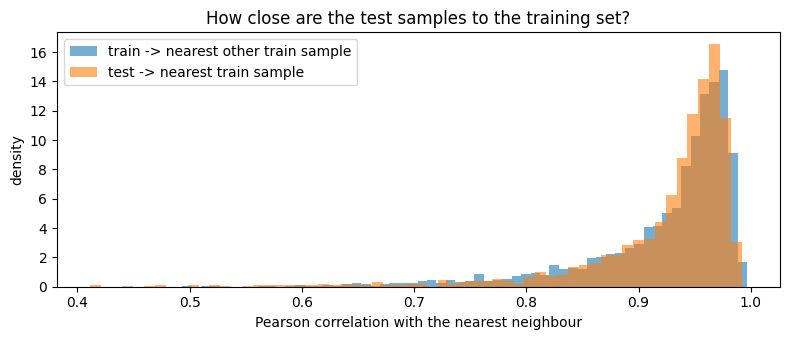

In [ ]:
# Correlation of every training sample with every other training sample
S_train = Z_train @ Z_train.T
np.fill_diagonal(S_train, -np.inf)            # a sample cannot be its own neighbour
nn_train = S_train.argmax(axis=1)             # index of the most similar OTHER training sample
nn_train_corr = S_train.max(axis=1)           # and its correlation

# Leave-one-out 1-nearest-neighbour classifier: a free, model-less baseline
loo_correct = (y_train_idx[nn_train] == y_train_idx)
print(f'1-NN leave-one-out accuracy (train): {loo_correct.mean():.3f}')
for k, itv in enumerate(INTERVALS):
    print(f'    {itv}: {loo_correct[int_train_idx == k].mean():.3f}')

# How often is the nearest neighbour a sample recorded right next to it in the file?
# (inside a group of 100 samples, a random neighbour would be adjacent only ~2% of the time)
gap = np.abs(nn_train - np.arange(len(nn_train)))
print(f'Nearest neighbour is the previous/next sample in the file: {np.mean(gap <= 1):.1%}'
      f'  |  within 5 positions: {np.mean(gap <= 5):.1%}')

# Similarity of every test sample to its most similar training sample
nn_test_corr = (Z_test @ Z_train.T).max(axis=1)
print(f'Mean nearest-neighbour correlation: train->train {nn_train_corr.mean():.3f} | test->train {nn_test_corr.mean():.3f}')

plt.figure(figsize=(8, 3.5))
plt.hist(nn_train_corr, bins=60, density=True, alpha=0.6, label='train -> nearest other train sample')
plt.hist(nn_test_corr, bins=60, density=True, alpha=0.6, label='test -> nearest train sample')
plt.xlabel('Pearson correlation with the nearest neighbour')
plt.ylabel('density')
plt.title('How close are the test samples to the training set?')
plt.legend()
plt.tight_layout()
plt.show()

# Free the large similarity matrix
del S_train
_ = gc.collect()   # assign to '_' so the number of freed objects is not printed

## 3.4 Leakage check conclusions

1. **The training file is shuffled.** There are 4705 runs of consecutive samples from the same (class, interval) group, with an average length of 1.0. The order of the file therefore carries no information about the acquisition order.
2. **Consecutive samples are not more similar than any other pair.** The mean correlation is 0.667 both for consecutive and non-consecutive samples of the same class and interval, and it does not depend on the distance between samples in the file. The nearest neighbour of a training sample is the previous or next sample in the file 0.0% of the time.
3. **The test set is as close to the training set as the training samples are to each other.** The mean correlation with the nearest training sample is 0.924 for training samples and 0.925 for test samples, and both distributions overlap almost perfectly. The test set was very likely drawn from the same measurement campaign as the training set.

**Decision:** a **stratified random split (by class and interval)** is a valid proxy for the test set, so we use **stratified 5-fold cross-validation** for all models. Because the file is shuffled we cannot completely rule out near-duplicate measurements, but point 3 shows that, if they exist, they affect the test set in the same way as the validation folds, so the validation accuracy should be a good estimate of the test accuracy.

**Bonus: a strong, model-free baseline.** A 1-nearest-neighbour classifier based on this correlation already reaches **90.5%** leave-one-out accuracy (95.9% / 89.7% / 85.9% for the 50-80 / 80-110 / 110-140 cm intervals). This is the reference that every model of the following sections must beat, and it confirms that the accuracy drops with the distance.

# 4. Preprocessing

This section turns the raw images into the arrays that every model will use. All models share the same preprocessing, so that the comparison between them is fair.

1. **Frequency downsampling (4.1).** The 1601 frequency points are averaged in groups of 4 (-> 400 points). The narrowest sub-band is 0.5 GHz wide and still keeps more than 50 points, so the notches remain well resolved while the input becomes 4 times smaller: faster training, fewer parameters and less risk of overfitting.
2. **Normalisation (4.2).** Three options are compared with a quick, model-free 1-nearest-neighbour test, and the best one is kept.
3. **Targets (4.3).** The class index for branch A (direct classification) and the 5-bit vector for branch B (bit-wise prediction), together with some sanity checks on the code.
4. **Cross-validation folds (4.4).** A stratified 5-fold split by class x interval, fixed once and reused by every model.

## 4.1 Frequency downsampling

The 1601 frequency points are averaged in groups of 4. The number of points left in each sub-band is printed to check that every notch can still be resolved, and the same image is shown before and after.

Shape before: (4800, 1601, 57) -> after: (4800, 400, 57)
Frequency points per sub-band after downsampling: [92, 57, 68, 92, 91]


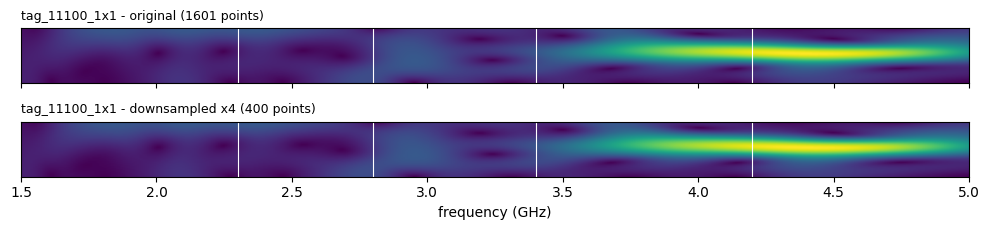

In [ ]:
DS_FACTOR = 4   # number of consecutive frequency points averaged together

def downsample_freq(X, factor=DS_FACTOR, batch=600):
    """Average-pool the frequency axis by `factor` and cast to float32.
    The work is done in batches so that a float32 copy of the whole array is never created at once."""
    n, n_freq, n_scales = X.shape
    new_f = n_freq // factor                         # 1601 // 4 = 400 (the last point is dropped)
    out = np.empty((n, new_f, n_scales), dtype=np.float32)
    for i in range(0, n, batch):
        chunk = X[i:i + batch, :new_f * factor, :].astype(np.float32)
        out[i:i + batch] = chunk.reshape(-1, new_f, factor, n_scales).mean(axis=2)
    return out

X_train_ds = downsample_freq(X_train)
X_test_ds = downsample_freq(X_test)
X_ref_ds = downsample_freq(X_ref)

# Frequency of every new bin (mean of the 4 original frequencies)
freqs_ds = freqs[:len(freqs) // DS_FACTOR * DS_FACTOR].reshape(-1, DS_FACTOR).mean(axis=1)

# Check that every sub-band still has enough points to resolve a notch
points_per_band = [int(np.sum((freqs_ds / 1e9 >= lo) & (freqs_ds / 1e9 < hi)))
                   for lo, hi in zip(SUBBAND_EDGES_GHZ[:-1], SUBBAND_EDGES_GHZ[1:])]
print('Shape before:', X_train.shape, '-> after:', X_train_ds.shape)
print('Frequency points per sub-band after downsampling:', points_per_band)

# Visual check: the same training sample before and after downsampling
fig, axes = plt.subplots(2, 1, figsize=(10, 2.4), sharex=True)
plot_cwt(axes[0], X_train[0], title=f'{y_train_names[0]} - original ({X_train.shape[1]} points)')
plot_cwt(axes[1], X_train_ds[0], title=f'{y_train_names[0]} - downsampled x{DS_FACTOR} ({X_train_ds.shape[1]} points)')
axes[-1].set_xlabel('frequency (GHz)')
plt.tight_layout()
plt.show()

## 4.2 Normalisation

The raw images are `uint8` values in [0, 255]. Three normalisations are compared:

| Mode | What it does | Idea behind it |
|---|---|---|
| `scale` | divide by 255 | keeps the absolute intensity of each image |
| `sample` | z-score of each image with its own mean and std | removes global gain differences between measurements (e.g. a weaker echo when the tag is far away) |
| `feature` | z-score of each (frequency, scale) position with the mean and std of the training set | gives the same weight to dark and bright regions of the spectrum (EDA: the low sub-bands are much darker) |

To choose without training any network, we use the leave-one-out **1-NN accuracy with Euclidean distance** in each normalised space: the normalisation that makes samples of the same class closer to each other is the most promising one. The final choice will be re-checked with the neural networks in the ablation study (section on improvements).

*Note: for the `feature` mode the mean and std are computed on the whole training set, which makes this quick test very slightly optimistic for that mode. Inside the cross-validation they will be computed on the training folds only.*

In [ ]:
def normalize(X, mode, stats=None):
    """Normalise a batch of images (float32 in, float32 out).
    'scale'  : divide by 255 -> values in [0, 1].
    'sample' : z-score of each image with its own mean and std.
    'feature': z-score of each (frequency, scale) position with the TRAINING mean and std given in `stats`."""
    if mode == 'scale':
        return X / 255.0
    if mode == 'sample':
        mu = X.mean(axis=(1, 2), keepdims=True)
        sd = X.std(axis=(1, 2), keepdims=True) + 1e-6
        return (X - mu) / sd
    if mode == 'feature':
        mu, sd = stats
        return (X - mu) / sd
    raise ValueError(f'Unknown normalisation mode: {mode}')


def fit_feature_stats(X):
    """Mean and std of every (frequency, scale) position, computed on the given (training) images."""
    return X.mean(axis=0, keepdims=True), X.std(axis=0, keepdims=True) + 1e-6


def knn_loo_correct(Xn, labels, step=2):
    """Leave-one-out 1-NN with Euclidean distance, computed on the GPU.
    Returns a boolean array: True where the nearest OTHER sample has the same label.
    The frequency axis is subsampled by `step` only to make the distance matrix lighter."""
    F = tf.constant(Xn[:, ::step, :].reshape(len(Xn), -1))
    sq = tf.reduce_sum(F * F, axis=1)                                        # squared norms
    D = sq[:, None] - 2.0 * tf.matmul(F, F, transpose_b=True) + sq[None, :]  # squared distances
    D = tf.linalg.set_diag(D, tf.fill([len(Xn)], np.float32(np.inf)))       # exclude the sample itself
    nn = tf.argmin(D, axis=1).numpy()
    return labels[nn] == labels


feature_stats = fit_feature_stats(X_train_ds)

norm_results = {}
for mode in ['scale', 'sample', 'feature']:
    correct = knn_loo_correct(normalize(X_train_ds, mode, feature_stats), y_train_idx)
    norm_results[mode] = {'all': correct.mean(),
                          **{itv: correct[int_train_idx == k].mean() for k, itv in enumerate(INTERVALS)}}
norm_results = pd.DataFrame(norm_results).T
display(norm_results.style.format('{:.3f}').highlight_max(axis=0, color='lightgreen'))

# Keep the normalisation with the best overall 1-NN accuracy
NORM_MODE = norm_results['all'].idxmax()
print('Selected normalisation:', NORM_MODE)

,all,050_080,080_110,110_140
scale,0.914,0.956,0.914,0.871
sample,0.905,0.959,0.897,0.858
feature,0.915,0.964,0.916,0.866


Selected normalisation: feature


## 4.3 Targets for the two output branches

- **Branch A (direct classification):** the integer index of the class, 0-15.
- **Branch B (bit-wise prediction):** the 5-bit code of the class, one binary target per sub-band.

Both targets are derived from the same `CODEBOOK`, a 16 x 5 matrix with the code of every class. We also verify the two properties of the code found during the exploration: all 16 codes are different, and all of them have an odd number of 1s (odd parity), which means that any two classes differ in at least 2 bits.

In [ ]:
# Apply the normalisation chosen in 4.2 to every dataset
# (for 'feature' mode the statistics always come from the training set)
X_train_p = normalize(X_train_ds, NORM_MODE, feature_stats).astype(np.float32)
X_test_p = normalize(X_test_ds, NORM_MODE, feature_stats).astype(np.float32)
X_ref_p = normalize(X_ref_ds, NORM_MODE, feature_stats).astype(np.float32)
print(f'Normalisation "{NORM_MODE}" applied | train mean {X_train_p.mean():.3f}, std {X_train_p.std():.3f}')

# Branch A target: integer class index 0..15 (same order as CLASS_NAMES)
y_train = y_train_idx

# Branch B target: the codebook holds the 5-bit code of each of the 16 classes
CODEBOOK = np.array([[int(b) for b in label_to_code(c)] for c in CLASS_NAMES], dtype=np.float32)   # (16, 5)
bits_train = CODEBOOK[y_train]                                                                     # (4800, 5)

# Sanity checks on the code
assert len(np.unique(CODEBOOK, axis=0)) == N_CLASSES, 'two classes share the same code'
assert np.all(CODEBOOK.sum(axis=1) % 2 == 1), 'not all codes have odd parity'
hamming = (CODEBOOK[:, None, :] != CODEBOOK[None, :, :]).sum(axis=-1)          # (16, 16) bit differences
print('All 16 codes are unique and have odd parity.')
print('Minimum Hamming distance between two classes:', hamming[~np.eye(N_CLASSES, dtype=bool)].min())
print('Number of classes with a 1 in each bit:', CODEBOOK.sum(axis=0).astype(int).tolist())

# Interval index of the test samples (possible extra input for some models)
int_test_idx = np.searchsorted(np.asarray(INTERVALS), int_test)

# Show the codebook as a table
display(pd.DataFrame(CODEBOOK.astype(int), index=CLASS_NAMES,
                     columns=[f'bit {i + 1}' for i in range(N_BITS)]))

Normalisation "feature" applied | train mean 0.000, std 1.000
All 16 codes are unique and have odd parity.
Minimum Hamming distance between two classes: 2
Number of classes with a 1 in each bit: [8, 8, 8, 8, 8]


,bit 1,bit 2,bit 3,bit 4,bit 5
tag_00001_4x4,0,0,0,0,1
tag_00010_2x2,0,0,0,1,0
tag_00100_4x4,0,0,1,0,0
tag_00111_2x2,0,0,1,1,1
tag_01000_2x2,0,1,0,0,0
tag_01011_4x4,0,1,0,1,1
tag_01101_1x1,0,1,1,0,1
tag_01110_3x3,0,1,1,1,0
tag_10000_4x4,1,0,0,0,0
tag_10011_2x2,1,0,0,1,1


## 4.4 Cross-validation folds

Following the conclusions of section 3, we use **stratified 5-fold cross-validation**. The stratification variable is the (class, interval) group, so every fold contains exactly the same number of samples of every class at every distance (20 per group).

The folds are computed **once** and stored in `fold_id`, so that every model of the following sections is trained and evaluated on exactly the same splits. Differences between models are therefore due to the models, not to a lucky split. Results will always be reported as **mean +/- standard deviation over the 5 folds**.

In [ ]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# fold_id[i] = fold in which sample i is used for VALIDATION
fold_id = np.empty(len(y_train), dtype=int)
for k, (_, val_idx) in enumerate(skf.split(np.zeros(len(group_id)), group_id)):   # stratify by (class, interval)
    fold_id[val_idx] = k

# Check: every fold has the same number of samples per interval and per class
display(pd.crosstab(fold_id, int_train, rownames=['fold'], colnames=['interval'], margins=True))
print('Samples of each class in every validation fold:', np.unique(pd.crosstab(fold_id, y_train).values))

# Summary of the arrays ready for modelling
print()
for name, arr in [('X_train_p', X_train_p), ('X_test_p', X_test_p), ('y_train', y_train), ('bits_train', bits_train)]:
    print(f'{name:11s} shape {str(arr.shape):18s} dtype {arr.dtype}')

interval,050_080,080_110,110_140,All
fold,,,,
0,320,320,320,960
1,320,320,320,960
2,320,320,320,960
3,320,320,320,960
4,320,320,320,960
All,1600,1600,1600,4800


Samples of each class in every validation fold: [60]

X_train_p   shape (4800, 400, 57)    dtype float32
X_test_p    shape (2400, 400, 57)    dtype float32
y_train     shape (4800,)            dtype int64
bits_train  shape (4800, 5)          dtype float32


## 4.5 Preprocessing conclusions

1. **Downsampling x4 loses no relevant information.** The images go from 1601 x 57 to **400 x 57**. The narrowest sub-band (2.3-2.8 GHz) still has 57 frequency points, and the visual check shows that the pattern is preserved.
2. **The three normalisations give very similar results** with the 1-NN test (91.4% `scale`, 90.5% `sample`, 91.5% `feature`). The differences (around 1%) are small, so the normalisation is not a critical choice for a distance-based method. We keep **`feature`** (z-score per frequency-scale position), which was marginally the best and gives the same weight to the dark low-frequency sub-bands as to the bright high-frequency ones. The choice will be re-checked with the neural networks.
   - *Important:* inside the cross-validation, the `feature` statistics must be computed on the training folds only (`fit_feature_stats` on `X_train_ds`), to avoid any information from the validation fold leaking into the training.
3. **Targets ready.** `y_train` (class index 0-15) for branch A and `bits_train` (5 bits) for branch B. The checks confirm that the 16 codes are unique, have odd parity and are at least 2 bits apart. Every bit is 1 in exactly 8 of the 16 classes, so the bit targets are balanced.
4. **Folds ready.** `fold_id` defines 5 folds of 960 samples each, with exactly 60 samples per class and 320 per interval in every fold.

**Arrays available for the models:** `X_train_p` (4800, 400, 57), `X_test_p` (2400, 400, 57), `y_train`, `bits_train`, `CODEBOOK`, `fold_id`.

# 5. Baselines

Before training neural networks we need reference results. A deep model is only worth its complexity if it clearly beats simpler approaches, so this section evaluates, with exactly the same 5 folds:

| Family | Model | Training? | Why |
|---|---|---|---|
| Physical / DSP | **Reference templates**: assign the tag whose clean reference measurement is most correlated | No | What a classical signal-processing approach would do with the clean measurements |
| Model-free | **Training centroids**: assign the class whose mean training image is most correlated | Only class means | Tests whether one average pattern per class is enough |
| Model-free | **1-NN**: assign the class of the most correlated training image | No | Strongest simple method found in section 3 (90.5% leave-one-out) |
| Classical ML | **PCA + Logistic Regression** | Yes | Linear classifier on a compressed representation |
| Classical ML | **PCA + SVM (RBF kernel)** | Yes | Non-linear classical classifier, usually a strong baseline |

We first build a **common evaluation framework (5.0)** that will also be reused by every neural network, so that all results are computed in exactly the same way.

## 5.0 Common evaluation framework

Every model of the notebook, from the baselines to the neural networks, is evaluated with the same functions:
- `get_fold(k)` returns the training and validation indices of fold `k` and the two normalised arrays. The `feature` statistics are computed on the training part only.
- `cross_validate(name, fit_predict)` runs the 5 folds, stores the out-of-fold predictions in `OOF_PRED` and the summary (mean, std and accuracy per interval) in `RESULTS`. A model only has to provide a `fit_predict` function that trains on one fold and returns the predicted classes of the validation fold.
- `show_results()` displays every model evaluated so far, best first.

In [ ]:
import time
from sklearn.metrics import accuracy_score

y_ref_idx = np.searchsorted(CLASS_NAMES, y_ref_names)   # class index of the clean reference measurements


def get_fold(k, X_raw=X_train_ds, mode=NORM_MODE):
    """Return (train indices, validation indices, normalised X_train, normalised X_val) for fold k.
    The 'feature' statistics are computed on the TRAINING part only, so nothing leaks from validation."""
    tr = np.where(fold_id != k)[0]
    va = np.where(fold_id == k)[0]
    stats = fit_feature_stats(X_raw[tr]) if mode == 'feature' else None
    return tr, va, normalize(X_raw[tr], mode, stats), normalize(X_raw[va], mode, stats)


RESULTS = {}    # model name -> summary of its cross-validation (filled by every experiment)
OOF_PRED = {}   # model name -> out-of-fold predicted class of every training sample


def cross_validate(name, fit_predict, verbose=True):
    """Run the 5-fold cross-validation of one model and store its results.
    `fit_predict(X_tr, y_tr, X_va, tr_idx, va_idx)` must train on the training fold and
    return the predicted class index (0..15) of every validation sample."""
    oof = np.full(len(y_train), -1)        # out-of-fold predictions
    fold_acc = []
    t0 = time.time()
    for k in range(N_FOLDS):
        tr, va, X_tr, X_va = get_fold(k)
        oof[va] = fit_predict(X_tr, y_train[tr], X_va, tr, va)
        fold_acc.append(accuracy_score(y_train[va], oof[va]))
        if verbose:
            print(f'  fold {k}: {fold_acc[-1]:.4f}')
    summary = {'mean acc': np.mean(fold_acc), 'std acc': np.std(fold_acc)}
    for j, itv in enumerate(INTERVALS):                    # accuracy per distance interval
        m = int_train_idx == j
        summary[itv] = accuracy_score(y_train[m], oof[m])
    summary['time (s)'] = time.time() - t0
    RESULTS[name], OOF_PRED[name] = summary, oof
    print(f'{name}: {summary["mean acc"]:.4f} +/- {summary["std acc"]:.4f}   ({summary["time (s)"]:.0f} s)')
    return summary


def show_results():
    """Table with every model evaluated so far, best first."""
    df = pd.DataFrame(RESULTS).T.sort_values('mean acc', ascending=False)
    fmt = {c: '{:.4f}' for c in ['mean acc', 'std acc'] + INTERVALS}
    fmt['time (s)'] = '{:.0f}'
    return df.style.format(fmt).background_gradient(subset=['mean acc'], cmap='Greens')


# Helpers for the correlation-based baselines
def flat(X):
    """(n, 400, 57) -> (n, 22800): one row per image."""
    return X.reshape(len(X), -1)


def corr_matrix(A, B):
    """Pearson correlation between every image of A and every image of B -> (len(A), len(B))."""
    A = flat(A) - flat(A).mean(axis=1, keepdims=True)
    B = flat(B) - flat(B).mean(axis=1, keepdims=True)
    A /= np.linalg.norm(A, axis=1, keepdims=True) + 1e-8
    B /= np.linalg.norm(B, axis=1, keepdims=True) + 1e-8
    return A @ B.T

print('Evaluation framework ready.')

Evaluation framework ready.


## 5.1 Correlation-based baselines (no learning)

The three methods compare each validation image with a set of 'prototype' images using the Pearson correlation, and assign the class of the most similar prototype. They only differ in the prototypes:
- **Reference templates**: the mean of the 5 clean reference measurements of each tag (16 prototypes). This is the classical DSP approach: compare with a known clean signature.
- **Training centroids**: the mean of all the training images of each class in the training folds (16 prototypes).
- **1-NN**: every training image of the training folds (3840 prototypes).

In [ ]:
def reference_templates(X_tr, y_tr, X_va, tr, va):
    """Nearest clean reference template. The references are normalised with the statistics
    of the training folds, exactly like the validation images."""
    stats = fit_feature_stats(X_train_ds[tr]) if NORM_MODE == 'feature' else None
    refs = normalize(X_ref_ds, NORM_MODE, stats)
    templates = np.stack([refs[y_ref_idx == c].mean(axis=0) for c in range(N_CLASSES)])   # (16, 400, 57)
    return corr_matrix(X_va, templates).argmax(axis=1)


def training_centroids(X_tr, y_tr, X_va, tr, va):
    """Nearest class centroid (mean training image of each class)."""
    centroids = np.stack([X_tr[y_tr == c].mean(axis=0) for c in range(N_CLASSES)])        # (16, 400, 57)
    return corr_matrix(X_va, centroids).argmax(axis=1)


def one_nn(X_tr, y_tr, X_va, tr, va):
    """Class of the most correlated training image."""
    return y_tr[corr_matrix(X_va, X_tr).argmax(axis=1)]


cross_validate('Reference templates (DSP)', reference_templates)
cross_validate('Training centroids', training_centroids)
cross_validate('1-NN (correlation)', one_nn)
display(show_results())

  fold 0: 0.5979
  fold 1: 0.6375
  fold 2: 0.6021
  fold 3: 0.6125
  fold 4: 0.6042
Reference templates (DSP): 0.6108 +/- 0.0142   (7 s)
  fold 0: 0.7312
  fold 1: 0.7677
  fold 2: 0.7427
  fold 3: 0.7490
  fold 4: 0.7510
Training centroids: 0.7483 +/- 0.0119   (5 s)
  fold 0: 0.9062
  fold 1: 0.9021
  fold 2: 0.9156
  fold 3: 0.9135
  fold 4: 0.9208
1-NN (correlation): 0.9117 +/- 0.0067   (8 s)


,mean acc,std acc,050_080,080_110,110_140,time (s)
1-NN (correlation),0.9117,0.0067,0.9675,0.9119,0.8556,8
Training centroids,0.7483,0.0119,0.8094,0.8044,0.6312,5
Reference templates (DSP),0.6108,0.0142,0.6850,0.6419,0.5056,7


## 5.2 Classical machine learning: PCA + Logistic Regression / SVM

Each image has 400 x 57 = 22,800 values, many more than the 3,840 training images of a fold. We therefore first compress the images with **PCA** (Principal Component Analysis) to 100 components, **standardise** each component (so that all components have the same scale, which the classifiers need to converge properly) and then train, always fitting everything on the training folds only:
- a **Logistic Regression** (linear classifier), and
- an **SVM with RBF kernel** (non-linear classifier).

The hyper-parameters are reasonable defaults (100 components, C = 1 for the logistic regression, C = 10 for the SVM). They are not tuned, because the goal is a fair reference point, not the best possible classical model.

  fold 0: 0.8948
  fold 1: 0.9073
  fold 2: 0.8990
  fold 3: 0.8844
  fold 4: 0.9094
PCA(100) + Logistic Regression: 0.8990 +/- 0.0090   (35 s)
  fold 0: 0.9042
  fold 1: 0.9010
  fold 2: 0.9052
  fold 3: 0.8917
  fold 4: 0.9135
PCA(100) + SVM (RBF): 0.9031 +/- 0.0071   (37 s)


,mean acc,std acc,050_080,080_110,110_140,time (s)
1-NN (correlation),0.9117,0.0067,0.9675,0.9119,0.8556,8
PCA(100) + SVM (RBF),0.9031,0.0071,0.9712,0.9381,0.8000,37
PCA(100) + Logistic Regression,0.8990,0.0090,0.9606,0.9200,0.8163,35
Training centroids,0.7483,0.0119,0.8094,0.8044,0.6312,5
Reference templates (DSP),0.6108,0.0142,0.6850,0.6419,0.5056,7


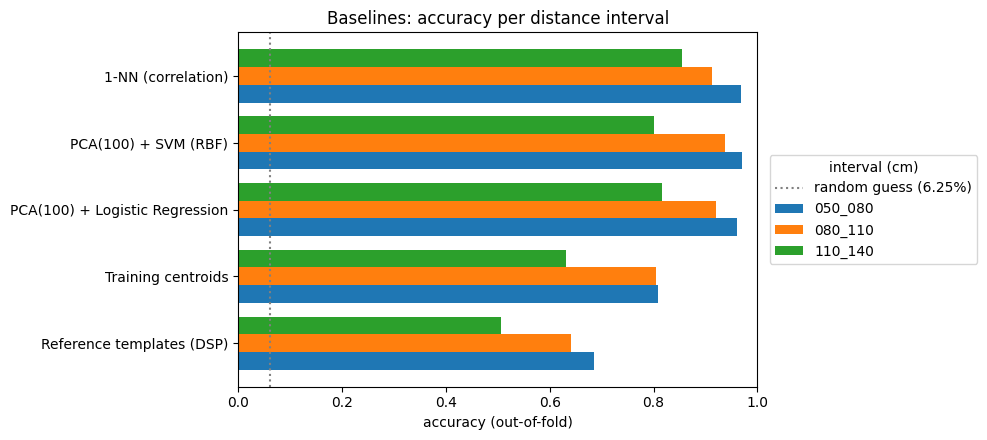

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def sklearn_model(make_model):
    """Wrap a scikit-learn model so that it can be used with cross_validate().
    `make_model` builds a NEW untrained model for every fold."""
    def fit_predict(X_tr, y_tr, X_va, tr, va):
        model = make_model()
        model.fit(flat(X_tr), y_tr)          # PCA, scaler and classifier are fitted on the training fold only
        return model.predict(flat(X_va))
    return fit_predict


cross_validate('PCA(100) + Logistic Regression',
               sklearn_model(lambda: make_pipeline(PCA(n_components=100, random_state=SEED),
                                                   StandardScaler(),   # give every PCA component the same scale
                                                   LogisticRegression(C=1.0, max_iter=3000))))
cross_validate('PCA(100) + SVM (RBF)',
               sklearn_model(lambda: make_pipeline(PCA(n_components=100, random_state=SEED),
                                                   StandardScaler(),   # give every PCA component the same scale
                                                   SVC(C=10, kernel='rbf', gamma='scale'))))

# Comparison of all the baselines
display(show_results())

df_res = pd.DataFrame(RESULTS).T.sort_values('mean acc')
ax = df_res[INTERVALS].plot.barh(figsize=(10, 4.5), width=0.8)
ax.axvline(1 / N_CLASSES, color='grey', ls=':', label='random guess (6.25%)')
ax.set_xlabel('accuracy (out-of-fold)')
ax.set_xlim(0, 1)
ax.set_title('Baselines: accuracy per distance interval')
ax.legend(title='interval (cm)', loc='center left', bbox_to_anchor=(1.01, 0.5))   # legend outside the axes
plt.tight_layout()
plt.show()

## 5.3 Baseline conclusions

| Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm |
|---|---|---|---|---|
| **1-NN (correlation)** | **91.2% +/- 0.7** | 96.8% | 91.2% | 85.6% |
| PCA(100) + SVM (RBF) | 90.3% +/- 0.7 | 97.1% | 93.8% | 80.0% |
| PCA(100) + Logistic Regression | 89.9% +/- 0.9 | 96.1% | 92.0% | 81.6% |
| Training centroids | 74.8% +/- 1.2 | 80.9% | 80.4% | 63.1% |
| Reference templates (DSP) | 61.1% +/- 1.4 | 68.5% | 64.2% | 50.6% |

1. **Classical DSP is not enough.** Comparing with the clean reference signatures only reaches 61%, and 51% at the largest distance. This confirms the statement of the problem: real-world measurements are too distorted for a template-matching approach, which motivates the use of machine learning.
2. **One average pattern per class is not enough either** (75%). Each class shows several different appearances (different distances and inclinations), so a good classifier must model the variability within a class, not only its mean.
3. **Simple data-driven methods are already strong: about 90-91%.** The 1-NN, which simply looks for the most similar training measurement, is the best baseline. The PCA models are slightly worse overall but better at 80-110 cm.
4. **The distance is the main difficulty.** Every method loses 10-17 points between 50-80 cm and 110-140 cm. The far interval is where a better model can gain the most.
5. **The folds are very stable** (standard deviation below 1.5 points), so differences of about 1-2 points between models will be meaningful.

**Target for the neural networks: clearly above 91.2%**, and especially better than 85.6% in the 110-140 cm interval.

# 6. Neural networks: MLP vs CNN, direct class vs bits

This is the core experiment of the project. We compare **two architectures** and **two ways of producing the output**, i.e. four models, all evaluated with the same 5 folds and the same framework as the baselines.

| | Branch A: direct class (16-way softmax) | Branch B: 5 bits (5 sigmoids + decoding) |
|---|---|---|
| **MLP** (fully connected) | MLP-A | MLP-B |
| **CNN 1D** (convolutional) | CNN1D-A | CNN1D-B |

**Architectures**
- **MLP**: the frequency axis is first average-pooled by 4 (400 -> 100 bins) to keep the number of weights manageable, then flattened (5,700 inputs) and passed through two dense layers (512 and 256 units), each followed by batch normalisation, ReLU and dropout 0.4.
- **CNN 1D**: the 57 CWT scales are treated as **channels** and the convolutions slide along the **frequency axis**, where the notches are. Three blocks of [Conv1D (kernel 7) -> BatchNorm -> ReLU -> MaxPool(2) -> Dropout 0.2] with 64, 128 and 128 filters reduce the 400 frequency bins to 50. The result is **flattened** (not globally pooled), so that the network keeps *where* along the frequency axis each pattern appears, which is exactly what defines each bit (EDA conclusion). A dense layer of 128 units follows.

**Outputs**
- **Branch A**: 16 softmax outputs trained with categorical cross-entropy. The predicted class is the most probable one.
- **Branch B**: 5 sigmoid outputs (one per sub-band) trained with binary cross-entropy. The 5 probabilities are converted into a class with **maximum-likelihood (soft-decision) decoding**: for each of the 16 valid codes we compute log P(code) = sum over the 5 bits of [ b log(p) + (1 - b) log(1 - p) ] and pick the most likely code. This always returns an existing tag, even when the thresholded bits form a code that does not exist. Thanks to the odd parity of the code, that happens every time exactly one bit is wrong, and simple thresholding or a Hamming-distance decoder would then face a 5-way tie.

**Training setup (identical for the four models)**
- Adam optimiser, learning rate 1e-3, batch size 64, up to 100 epochs.
- **Early stopping** (patience 10, best weights restored) and **learning-rate reduction** (x0.5 after 4 epochs without improvement), both monitored on an *inner* 10% split of the training folds. The validation fold is never used to take any training decision, so its accuracy is an honest estimate of the performance on unseen data.
- Same random seed for every fold and model.

## 6.1 Building blocks

The two backbones (`mlp_backbone`, `cnn1d_backbone`), the two output heads (`build_model`), the maximum-likelihood decoder of branch B (`decode_bits`) and the wrapper `keras_model`, which trains a new Keras model on every fold so that the networks plug into `cross_validate` exactly like the baselines.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

tf.get_logger().setLevel('ERROR')   # hide TensorFlow 'retracing' warnings (harmless: a new model is built for every fold)

INPUT_SHAPE = X_train_ds.shape[1:]   # (400 frequency bins, 57 CWT scales)
EPOCHS = 100                         # maximum number of epochs (early stopping usually stops much earlier)
BATCH = 64


def mlp_backbone(x):
    """Fully connected network. The frequency axis is average-pooled 400 -> 100 first,
    otherwise the first dense layer would have more than 11 million weights."""
    x = layers.AveragePooling1D(pool_size=4)(x)       # (100, 57)
    x = layers.Flatten()(x)                           # 5700 inputs
    for units in [512, 256]:
        x = layers.Dense(units)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Dropout(0.4)(x)
    return x


def cnn1d_backbone(x):
    """1D CNN: the 57 scales are channels, the convolutions slide along the frequency axis."""
    for filters in [64, 128, 128]:
        x = layers.Conv1D(filters, kernel_size=7, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling1D(pool_size=2)(x)       # 400 -> 200 -> 100 -> 50
        x = layers.Dropout(0.2)(x)
    x = layers.Flatten()(x)                           # keep the frequency position of every pattern
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.4)(x)
    return x


BACKBONES = {'mlp': mlp_backbone, 'cnn1d': cnn1d_backbone}


def build_model(arch, branch):
    """arch: 'mlp' or 'cnn1d'. branch: 'A' (16-class softmax) or 'B' (5 sigmoid bits)."""
    inp = keras.Input(shape=INPUT_SHAPE)
    feat = BACKBONES[arch](inp)
    if branch == 'A':
        out = layers.Dense(N_CLASSES, activation='softmax', name='class')(feat)
        loss, metrics = 'sparse_categorical_crossentropy', ['accuracy']
    else:
        out = layers.Dense(N_BITS, activation='sigmoid', name='bits')(feat)
        loss, metrics = 'binary_crossentropy', [keras.metrics.BinaryAccuracy(name='bit_acc')]
    model = keras.Model(inp, out, name=f'{arch}_{branch}')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=loss, metrics=metrics)
    return model


def decode_bits(p_bits, eps=1e-7):
    """Maximum-likelihood decoding of the 5 bit probabilities into one of the 16 valid classes.
    log P(code) = sum_i [ b_i log(p_i) + (1 - b_i) log(1 - p_i) ]  ->  (n_samples, 16), take the argmax."""
    log_lik = np.log(p_bits + eps) @ CODEBOOK.T + np.log(1 - p_bits + eps) @ (1 - CODEBOOK).T
    return log_lik.argmax(axis=1)


HISTORIES = {}      # model name -> list with the training history of every fold
BIT_STATS = {}      # model name -> quality of the raw bit predictions (branch B only)
MODEL_PARAMS = {}   # model name -> number of trainable parameters
OOF_PROBA = {}      # model name -> out-of-fold network outputs (class or bit probabilities)


def keras_model(arch, branch, name):
    """Return a fit_predict function (see cross_validate) that trains a new Keras model on every fold."""
    def fit_predict(X_tr, y_tr, X_va, tr, va):
        keras.backend.clear_session()
        tf.random.set_seed(SEED)
        # Inner split of the TRAINING fold, used only for early stopping and learning-rate reduction
        X_fit, X_es, y_fit, y_es = train_test_split(X_tr, y_tr, test_size=0.1, stratify=y_tr, random_state=SEED)
        target_fit = y_fit if branch == 'A' else CODEBOOK[y_fit]
        target_es = y_es if branch == 'A' else CODEBOOK[y_es]

        model = build_model(arch, branch)
        MODEL_PARAMS[name] = model.count_params()
        callbacks = [
            keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
        ]
        h = model.fit(X_fit, target_fit, validation_data=(X_es, target_es),
                      epochs=EPOCHS, batch_size=BATCH, callbacks=callbacks, verbose=0)
        HISTORIES.setdefault(name, []).append(h.history)
        print(f'    trained for {len(h.history["loss"])} epochs', end=' |')

        p = model.predict(X_va, batch_size=256, verbose=0)
        OOF_PROBA.setdefault(name, np.zeros((len(y_train), p.shape[1]), dtype=np.float32))[va] = p
        if branch == 'A':
            return p.argmax(axis=1)

        # Branch B: measure the quality of the raw bits before decoding
        true_bits = CODEBOOK[y_train[va]].astype(int)
        hard = (p > 0.5).astype(int)                                        # simple thresholding
        is_valid = (hard[:, None, :] == CODEBOOK[None].astype(int)).all(-1).any(-1)
        st = BIT_STATS.setdefault(name, {'bit accuracy': [], 'invalid codes (%)': [], 'acc. thresholding only': []})
        st['bit accuracy'].append((hard == true_bits).mean())
        st['invalid codes (%)'].append(100 * (~is_valid).mean())
        st['acc. thresholding only'].append((hard == true_bits).all(axis=1).mean())
        return decode_bits(p)                                               # maximum-likelihood decoding
    return fit_predict


# Show the two architectures (branch A versions)
for arch in ['mlp', 'cnn1d']:
    m = build_model(arch, 'A')
    print(f'{m.name}: {m.count_params():,} parameters')
build_model('cnn1d', 'A').summary()

mlp_A: 3,057,424 parameters
cnn1d_A: 1,021,072 parameters


Model: "cnn1d_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 400, 57)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 400, 64)        │        25,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 400, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 400, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 200, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 200, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 200, 128)       │        57,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 200, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 100, 128)       │       114,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 100, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class (Dense)                   │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,021,072 (3.90 MB)

 Trainable params: 1,020,176 (3.89 MB)

 Non-trainable params: 896 (3.50 KB)

## 6.2 MLP (fully connected network): branches A and B

For every fold a new model is trained from scratch. The output shows the number of epochs that early stopping kept and the validation-fold accuracy.

In [ ]:
cross_validate('MLP-A', keras_model('mlp', 'A', 'MLP-A'))
_ = cross_validate('MLP-B', keras_model('mlp', 'B', 'MLP-B'))   # '_ =' avoids printing the returned summary

    trained for 36 epochs |  fold 0: 0.9594
    trained for 27 epochs |  fold 1: 0.9583
    trained for 40 epochs |  fold 2: 0.9625
    trained for 35 epochs |  fold 3: 0.9594
    trained for 37 epochs |  fold 4: 0.9604
MLP-A: 0.9600 +/- 0.0014   (102 s)
    trained for 34 epochs |  fold 0: 0.9531
    trained for 68 epochs |  fold 1: 0.9490
    trained for 51 epochs |  fold 2: 0.9646
    trained for 42 epochs |  fold 3: 0.9479
    trained for 32 epochs |  fold 4: 0.9563
MLP-B: 0.9542 +/- 0.0060   (113 s)


## 6.3 CNN 1D (convolutional network): branches A and B

Same protocol as the MLP: a new model per fold, early stopping on an inner split of the training folds.

In [ ]:
cross_validate('CNN1D-A', keras_model('cnn1d', 'A', 'CNN1D-A'))
_ = cross_validate('CNN1D-B', keras_model('cnn1d', 'B', 'CNN1D-B'))   # '_ =' avoids printing the returned summary

    trained for 33 epochs |  fold 0: 0.9552
    trained for 33 epochs |  fold 1: 0.9583
    trained for 27 epochs |  fold 2: 0.9635
    trained for 28 epochs |  fold 3: 0.9594
    trained for 35 epochs |  fold 4: 0.9615
CNN1D-A: 0.9596 +/- 0.0028   (133 s)
    trained for 37 epochs |  fold 0: 0.9479
    trained for 32 epochs |  fold 1: 0.9427
    trained for 36 epochs |  fold 2: 0.9531
    trained for 29 epochs |  fold 3: 0.9469
    trained for 32 epochs |  fold 4: 0.9510
CNN1D-B: 0.9483 +/- 0.0036   (125 s)


## 6.4 Comparison of the four neural networks

We compare the four models with each other and with the two best baselines:
- the global table of results (mean +/- std over the 5 folds and accuracy per distance interval);
- the number of parameters of each network;
- for branch B, the quality of the raw bits: bit accuracy, how often the thresholded bits form an **invalid code**, and the accuracy obtained by simple thresholding versus maximum-likelihood decoding;
- the learning curves of fold 0, to check for over- or under-fitting.

,mean acc,std acc,050_080,080_110,110_140,time (s)
MLP-A,0.9600,0.0014,0.9862,0.9725,0.9213,102
CNN1D-A,0.9596,0.0028,0.9881,0.9725,0.9181,133
MLP-B,0.9542,0.0060,0.9800,0.9694,0.9131,113
CNN1D-B,0.9483,0.0036,0.9788,0.9625,0.9038,125
1-NN (correlation),0.9117,0.0067,0.9675,0.9119,0.8556,8
PCA(100) + SVM (RBF),0.9031,0.0071,0.9712,0.9381,0.8000,37
PCA(100) + Logistic Regression,0.8990,0.0090,0.9606,0.9200,0.8163,35
Training centroids,0.7483,0.0119,0.8094,0.8044,0.6312,5
Reference templates (DSP),0.6108,0.0142,0.6850,0.6419,0.5056,7


,trainable parameters
MLP-A,"3,057,424"
MLP-B,"3,054,597"
CNN1D-A,"1,021,072"
CNN1D-B,"1,019,653"


,bit accuracy,invalid codes (%),acc. thresholding only,acc. with ML decoding
MLP-B,0.9785,4.44,0.9287,0.9542
CNN1D-B,0.9755,4.81,0.9221,0.9483


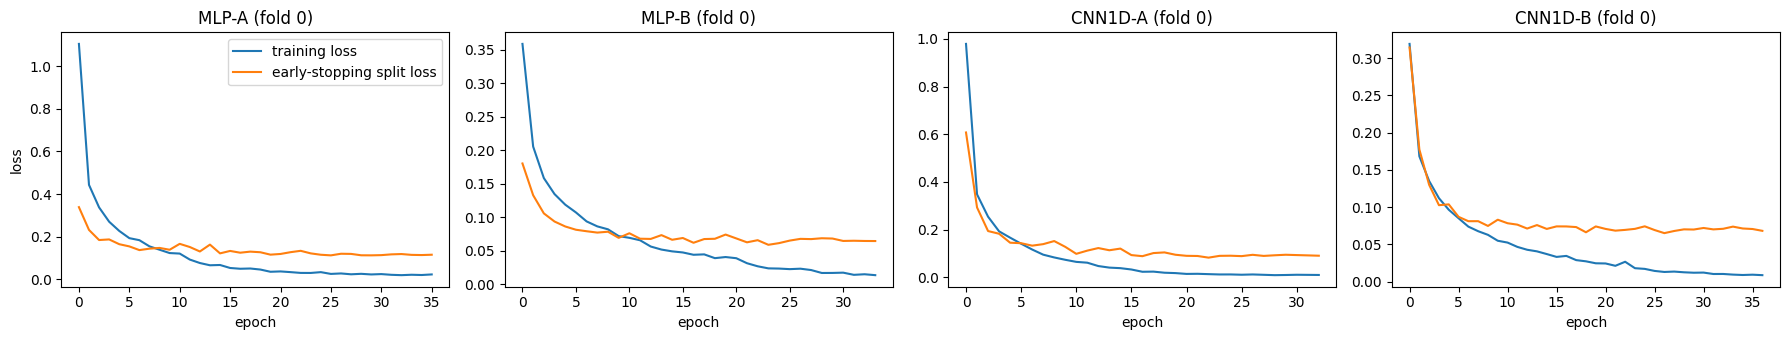

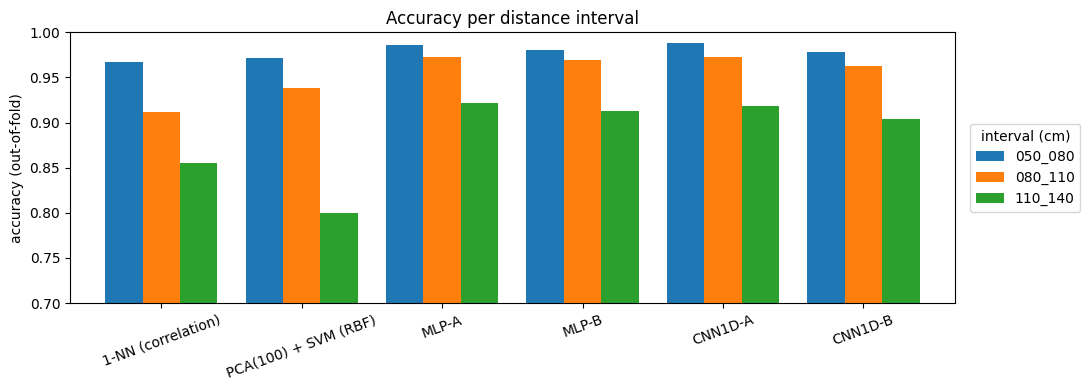

In [ ]:
NN_NAMES = ['MLP-A', 'MLP-B', 'CNN1D-A', 'CNN1D-B']

# Global results table (baselines + networks), best first
display(show_results())

# Size of every network
display(pd.Series(MODEL_PARAMS, name='trainable parameters').to_frame().style.format('{:,}'))

# Branch B: quality of the raw bits and effect of the maximum-likelihood decoding
bit_df = pd.DataFrame({n: {k: np.mean(v) for k, v in st.items()} for n, st in BIT_STATS.items()}).T
bit_df['acc. with ML decoding'] = [RESULTS[n]['mean acc'] for n in bit_df.index]
display(bit_df.style.format({'bit accuracy': '{:.4f}', 'invalid codes (%)': '{:.2f}',
                             'acc. thresholding only': '{:.4f}', 'acc. with ML decoding': '{:.4f}'}))

# Learning curves of fold 0 (training loss vs early-stopping loss)
fig, axes = plt.subplots(1, len(NN_NAMES), figsize=(18, 3.5))
for ax, name in zip(axes, NN_NAMES):
    h = HISTORIES[name][0]
    ax.plot(h['loss'], label='training loss')
    ax.plot(h['val_loss'], label='early-stopping split loss')
    ax.set_title(f'{name} (fold 0)')
    ax.set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
plt.tight_layout()
plt.show()

# Accuracy per distance interval: networks vs the two best baselines
compare = ['1-NN (correlation)', 'PCA(100) + SVM (RBF)'] + NN_NAMES
ax = pd.DataFrame(RESULTS).T.loc[compare, INTERVALS].plot.bar(figsize=(11, 4), width=0.8)
ax.set_ylim(0.7, 1.0)
ax.set_ylabel('accuracy (out-of-fold)')
ax.set_title('Accuracy per distance interval')
ax.tick_params(axis='x', rotation=20)
ax.legend(title='interval (cm)', loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

## 6.5 Neural network conclusions

| Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm | Parameters |
|---|---|---|---|---|---|
| **MLP-A** | **96.0% +/- 0.1** | 98.6% | 97.3% | 92.1% | 3.06 M |
| **CNN1D-A** | **96.0% +/- 0.3** | 98.8% | 97.3% | 91.8% | 1.02 M |
| MLP-B | 95.4% +/- 0.6 | 98.0% | 96.9% | 91.3% | 3.05 M |
| CNN1D-B | 94.8% +/- 0.4 | 97.9% | 96.3% | 90.4% | 1.02 M |
| *Best baseline: 1-NN* | *91.2% +/- 0.7* | *96.8%* | *91.2%* | *85.6%* | *-* |

1. **Every neural network clearly beats every baseline.** The best networks reach **96.0%**, almost 5 points above the 1-NN (91.2%). The gain is largest where the problem is hardest: at **110-140 cm** the accuracy goes from 85.6% to 92.1% (+6.5 points).
2. **MLP vs CNN: a tie in accuracy, but the CNN is 3 times smaller.** MLP-A and CNN1D-A reach the same accuracy (96.0%). However, the CNN achieves it with **1.0 M parameters instead of 3.1 M**, because convolutions share their weights along the frequency axis. This makes the CNN the more efficient architecture and the better starting point for further improvements (deeper or wider models are affordable).
3. **Branch A (direct class) beats branch B (bits) for both architectures** (+0.6 points for the MLP, +1.1 for the CNN). Although each individual bit is predicted very well (97.9% and 97.6% bit accuracy), a sample is only correct if **all 5 bits** are correct, and the errors of the 5 independent outputs add up. The softmax of branch A learns the 16 complete patterns directly and does not suffer from this.
4. **The maximum-likelihood decoder is essential for branch B.** With simple thresholding, **4-5% of the predictions are invalid codes** (codes that do not exist). The decoder converts them into the most likely valid tag and raises the accuracy from 92.9% to **95.4%** (MLP-B, +2.6 points) and from 92.2% to **94.8%** (CNN1D-B, +2.6 points). The odd parity of the code makes these errors easy to detect, and the bit probabilities make them correctable.
5. **There is some overfitting.** The learning curves show the training loss going almost to zero while the early-stopping loss stops improving after 10-15 epochs. Early stopping prevents the damage, but this suggests that more regularisation and **data augmentation** can still improve the results.

**Next steps:** the far interval (110-140 cm, about 92%) is where most errors remain. Candidate improvements: data augmentation, a multi-task model that combines branches A and B, a 2D CNN, hyper-parameter tuning, and finally an ensemble of the best models.

## 6.6 Detailed metrics: confusion matrix and per-bit accuracy

The mean accuracy says *how often* a model fails, but not *how*. Two extra views complete the validation protocol. Both are computed from the out-of-fold predictions, so every training sample is evaluated by a model that never saw it.

- **Confusion matrix** (true class in rows, predicted class in columns). Since the classes are 5-bit codes, each confusion can be read as a number of wrong bits. The code has odd parity, so two different tags always differ in 2 or 4 bits: a confusion at distance 2 means the network missed one notch and invented another one (or the reverse).
- **Accuracy of each bit.** For any model, the predicted class is converted back to its 5-bit code and compared with the true code, which tells which sub-band is the hardest. For branch B we also report the accuracy of the **raw** sigmoid outputs (thresholded at 0.5, before decoding), to see which bits the maximum-likelihood decoder repairs.

These functions are reused for every model trained from here on.

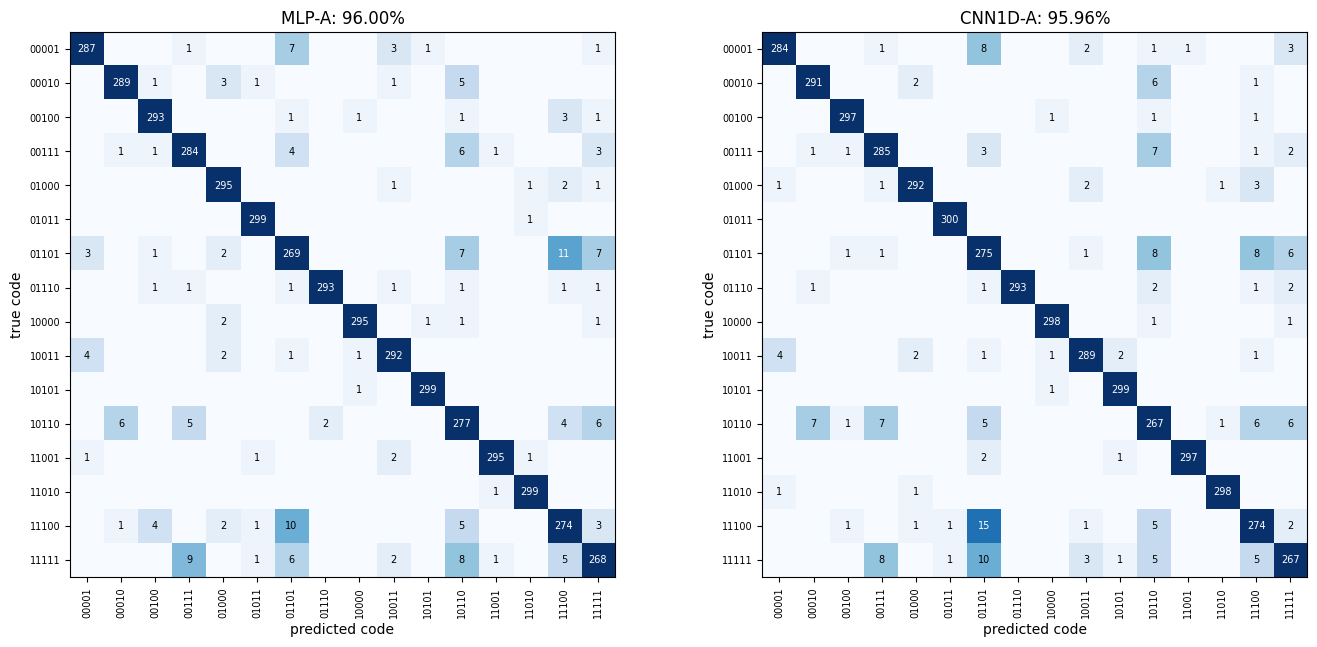

Most frequent confusions of MLP-A:


,true,predicted,count,bits that differ
0,01101,11100,11,2
1,11100,01101,10,2
2,11111,00111,9,2
3,11111,10110,8,2
4,00001,01101,7,2
5,01101,10110,7,4
6,01101,11111,7,2
7,11111,01101,6,2


Most frequent confusions of CNN1D-A:


,true,predicted,count,bits that differ
0,11100,01101,15,2
1,11111,01101,10,2
2,11111,00111,8,2
3,01101,10110,8,4
4,01101,11100,8,2
5,00001,01101,8,2
6,10110,00010,7,2
7,10110,00111,7,2


Errors grouped by the number of bits between the true and the predicted code:


,errors,2 bits apart (%),4 bits apart (%)
MLP-A,192,90.1,9.9
MLP-B,220,94.1,5.9
CNN1D-A,194,84.0,16.0
CNN1D-B,248,91.1,8.9


... (4 outputs left out)

Accuracy of each bit per distance interval (MLP-A):


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9906,0.9944,0.9956,0.9938,0.9944
080_110,0.9788,0.9894,0.9938,0.9912,0.9881
110_140,0.9556,0.9594,0.9812,0.9663,0.9637


Accuracy of each bit per distance interval (CNN1D-A):


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9931,0.9919,0.9962,0.9912,0.9962
080_110,0.9794,0.9925,0.9931,0.9900,0.9850
110_140,0.9469,0.9600,0.9775,0.9625,0.9631


In [ ]:
from sklearn.metrics import confusion_matrix

CODES = [label_to_code(c) for c in CLASS_NAMES]
BIT_COLS = [f'bit {i + 1} ({SUBBAND_EDGES_GHZ[i]}-{SUBBAND_EDGES_GHZ[i + 1]} GHz)' for i in range(N_BITS)]


def oof_confusion(name):
    return confusion_matrix(y_train, OOF_PRED[name], labels=np.arange(N_CLASSES))


def plot_confusion(name, ax):
    cm = oof_confusion(name)
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=20)   # low vmax so that the few errors are visible
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                        color='white' if cm[i, j] > 10 else 'black')
    ax.set_xticks(range(N_CLASSES))
    ax.set_xticklabels(CODES, rotation=90, fontsize=7)
    ax.set_yticks(range(N_CLASSES))
    ax.set_yticklabels(CODES, fontsize=7)
    ax.set_xlabel('predicted code')
    ax.set_ylabel('true code')
    ax.set_title(f'{name}: {RESULTS[name]["mean acc"]:.2%}')


def top_confusions(name, n=8):
    cm = oof_confusion(name)
    np.fill_diagonal(cm, 0)
    order = np.argsort(cm, axis=None)[::-1][:n]
    rows = [{'true': CODES[i], 'predicted': CODES[j], 'count': cm[i, j], 'bits that differ': hamming[i, j]}
            for i, j in zip(*np.unravel_index(order, cm.shape)) if cm[i, j] > 0]
    return pd.DataFrame(rows)


def errors_by_distance(names):
    rows = {}
    for name in names:
        wrong = OOF_PRED[name] != y_train
        d = hamming[y_train[wrong], OOF_PRED[name][wrong]]
        rows[name] = {'errors': wrong.sum(), '2 bits apart (%)': 100 * (d == 2).mean(),
                      '4 bits apart (%)': 100 * (d == 4).mean()}
    return pd.DataFrame(rows).T


def bit_accuracy(names):
    rows = {name: (CODEBOOK[OOF_PRED[name]] == CODEBOOK[y_train]).mean(axis=0) for name in names}
    return pd.DataFrame(rows, index=BIT_COLS).T


def raw_bit_accuracy(names):
    rows = {name: ((OOF_PROBA[name] > 0.5) == CODEBOOK[y_train]).mean(axis=0)
            for name in names if OOF_PROBA[name].shape[1] == N_BITS}
    return pd.DataFrame(rows, index=BIT_COLS).T


def bit_accuracy_by_interval(name):
    ok = CODEBOOK[OOF_PRED[name]] == CODEBOOK[y_train]
    return pd.DataFrame({itv: ok[int_train_idx == j].mean(axis=0) for j, itv in enumerate(INTERVALS)},
                        index=BIT_COLS).T


def detailed_report(names, focus):
    fig, axes = plt.subplots(1, len(focus), figsize=(7 * len(focus), 6.5), squeeze=False)
    for ax, name in zip(axes[0], focus):
        plot_confusion(name, ax)
    plt.tight_layout()
    plt.show()

    for name in focus:
        print(f'Most frequent confusions of {name}:')
        display(top_confusions(name))

    print('Errors grouped by the number of bits between the true and the predicted code:')
    display(errors_by_distance(names).style.format({'errors': '{:.0f}', '2 bits apart (%)': '{:.1f}',
                                                    '4 bits apart (%)': '{:.1f}'}))

    print('Accuracy of each bit of the predicted class:')
    display(bit_accuracy(names).style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))

    print('Branch B, raw sigmoid outputs before decoding:')
    display(raw_bit_accuracy(names).style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))

    for name in focus:
        print(f'Accuracy of each bit per distance interval ({name}):')
        display(bit_accuracy_by_interval(name).style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))


def paired_comparison(a, b):
    ok_a, ok_b = OOF_PRED[a] == y_train, OOF_PRED[b] == y_train
    return pd.DataFrame({'samples': [(ok_a & ok_b).sum(), (ok_a & ~ok_b).sum(),
                                     (~ok_a & ok_b).sum(), (~ok_a & ~ok_b).sum()]},
                        index=['both correct', f'only {a} correct', f'only {b} correct', 'both wrong'])


def full_table():
    df = pd.DataFrame(RESULTS).T
    df['parameters'] = pd.Series(MODEL_PARAMS)
    df = df.sort_values('mean acc', ascending=False)
    fmt = {c: '{:.4f}' for c in ['mean acc', 'std acc'] + INTERVALS}
    fmt.update({'time (s)': '{:.0f}', 'parameters': '{:,.0f}'})
    return df.style.format(fmt, na_rep='-').background_gradient(subset=['mean acc'], cmap='Greens')


detailed_report(NN_NAMES, focus=['MLP-A', 'CNN1D-A'])

## 6.7 Detailed metrics conclusions

| | MLP-A | CNN1D-A |
|---|---|---|
| Wrong predictions (out of 4,800) | 192 | 194 |
| Errors between codes 2 bits apart | 90.1% | 84.0% |
| Hardest bit: bit 1 (1.5-2.3 GHz) | 97.5% | 97.3% |
| Easiest bit: bit 3 (2.8-3.4 GHz) | 99.0% | 98.9% |
| Bit 1 at 50-80 cm / at 110-140 cm | 99.1% / 95.6% | 99.3% / 94.7% |

1. **Almost all errors are 'near misses'.** Two different tags always differ in 2 or 4 bits. Between 84% and 90% of the errors of the two best models fall on a code that is only 2 bits away, the minimum possible. The networks rarely confuse tags with very different signatures: they miss one notch and see another one that is not there. For branch B the share is even higher (91-94%), as expected from a decoder that changes as few bits as possible.
2. **The errors concentrate on the 1x1 tags.** Each one of the 8 most frequent confusions of MLP-A and of CNN1D-A involves at least one of the four 1x1 tags (01101, 10110, 11100, 11111), either as the true or as the predicted class. The most frequent pair, for both models, is 11100 / 01101, two 1x1 tags. A plausible physical explanation is that a 1x1 tag has a single resonator and reflects less power than a 4x4 tag, so its notches are closer to the noise level; we have not verified this with a specific experiment. The tag size is not needed to identify the class (section 4.3), but it does determine how hard the class is.
3. **Bit 1 (1.5-2.3 GHz) is the hardest and bit 3 (2.8-3.4 GHz) the easiest**, for the four networks. This agrees with the EDA (section 2.5): the lowest sub-bands contain very little energy, so their notches are harder to see.
4. **The distance degrades every bit, but not equally.** At 50-80 cm all the bits are above 99%. At 110-140 cm bit 3 is still at about 98%, while bit 1 drops to about 95%. The far interval is hard mostly because of the bits that were already the weakest.
5. **The maximum-likelihood decoder repairs the weak bits.** In MLP-B, decoding raises bit 1 from 96.7% to 97.3% and bit 2 from 97.4% to 97.8%, while the strong bits change by less than 0.2 points. This is how the decoder is expected to work: when the thresholded code is invalid, it flips the bit the network was least sure about, which is usually one of the low sub-bands.

**Consequences for the next steps:** the improvements should target noisy measurements of small tags and the low sub-bands (data augmentation with noise and amplitude changes), and the final analysis should report the accuracy per tag size.

# 7. 2D CNN: the scale axis as a second spatial dimension

**What the scale axis is.** Each input is the Continuous Wavelet Transform (CWT) of a measurement. The CWT compares the signal with stretched and compressed copies of one short oscillating pattern, the wavelet. The **scale** is the stretch factor: at small scales the wavelet is narrow and responds to sharp, fast changes; at large scales it is wide and responds to slow, broad trends. The 57 columns of an image are therefore 57 'zoom levels' of the same frequency sweep. A notch is not a single point of the image but a two-dimensional shape that spreads over several neighbouring scales, wider at the large ones.

**What the 1D CNN ignores.** The 1D CNN of section 6 takes the 57 scales as *channels*. Its first layer has an independent set of weights for every scale and nothing tells it that scale 10 and scale 11 are neighbours: if the 57 scales were shuffled, it would learn exactly the same.

**What a 2D CNN adds.** A 2D convolution slides small filters along frequency **and** scale, so that:
- it can detect the local two-dimensional shape of a notch (edges, ridges), which should be more robust to noise than the energy at each scale taken separately;
- its weights are shared along the scale axis too. The first layer needs 5 x 3 x 32 = 480 weights instead of the 7 x 57 x 64 = 25,536 of the 1D CNN, which acts as extra regularisation against the overfitting seen in section 6.

**Architecture.** It mirrors the 1D CNN so that the comparison isolates the effect of the 2D structure:
- three blocks of [Conv2D (kernel 5 x 3) -> BatchNorm -> ReLU -> MaxPool (2 x 2) -> Dropout 0.2] with 32, 64 and 128 filters: (400, 57) -> (200, 28) -> (100, 14) -> (50, 7). The kernel is longer along frequency because that axis has 7 times more points;
- the 7 remaining scale positions are averaged, but the 50 frequency positions are kept and flattened: the position along frequency is what defines each bit, so it must not be pooled away;
- the same dense head as the 1D CNN (128 units, BatchNorm, ReLU, dropout 0.4), and the same two output branches, optimiser, callbacks and folds.

The number of parameters is similar to the 1D CNN (about 1 M, most of them in the dense head), so a difference in accuracy cannot be attributed to model size.

In [ ]:
def cnn2d_backbone(x):
    x = layers.Reshape((*INPUT_SHAPE, 1))(x)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, kernel_size=(5, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(pool_size=2)(x)
        x = layers.Dropout(0.2)(x)
    x = layers.AveragePooling2D(pool_size=(1, x.shape[2]))(x)   # collapse the scale axis only
    x = layers.Flatten()(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.4)(x)
    return x


BACKBONES['cnn2d'] = cnn2d_backbone

for arch in ['cnn1d', 'cnn2d']:
    m = build_model(arch, 'A')
    print(f'{m.name}: {m.count_params():,} parameters')
build_model('cnn2d', 'A').summary()

cnn1d_A: 1,021,072 parameters
cnn2d_A: 977,104 parameters


Model: "cnn2d_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 400, 57)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 400, 57, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 400, 57, 32)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 400, 57, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 400, 57, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 200, 28, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 200, 28, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 200, 28, 64)    │        30,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 200, 28, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 200, 28, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 100, 14, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 100, 14, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 100, 14, 128)   │       123,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 100, 14, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 100, 14, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 50, 7, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 50, 7, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 50, 1, 128)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 977,104 (3.73 MB)

 Trainable params: 976,400 (3.72 MB)

 Non-trainable params: 704 (2.75 KB)

## 7.1 Training: branches A and B

Same protocol as in section 6: a new model for every fold, early stopping and learning-rate reduction on an inner 10% split of the training folds.

In [ ]:
cross_validate('CNN2D-A', keras_model('cnn2d', 'A', 'CNN2D-A'))
_ = cross_validate('CNN2D-B', keras_model('cnn2d', 'B', 'CNN2D-B'))

    trained for 40 epochs |  fold 0: 0.9490
    trained for 37 epochs |  fold 1: 0.9417
    trained for 43 epochs |  fold 2: 0.9427
    trained for 40 epochs |  fold 3: 0.9427
    trained for 33 epochs |  fold 4: 0.9458
CNN2D-A: 0.9444 +/- 0.0027   (215 s)
    trained for 27 epochs |  fold 0: 0.9333
    trained for 40 epochs |  fold 1: 0.9333
    trained for 41 epochs |  fold 2: 0.9281
    trained for 40 epochs |  fold 3: 0.9406
    trained for 42 epochs |  fold 4: 0.9323
CNN2D-B: 0.9335 +/- 0.0040   (204 s)


## 7.2 Ablation: does the order of the scales matter?

If the 2D CNN really exploits the fact that neighbouring scales are related, destroying that relation must hurt it. We train the same 2D CNN on images whose 57 scale columns have been **shuffled** with one fixed random permutation (the same for every image). The information is identical, only the neighbourhood along the scale axis is lost.

- If the accuracy drops, the 2D structure of the CWT carries useful information and the 2D convolution is exploiting it.
- If the accuracy does not change, the network only needs *where* along the frequency axis the energy changes, and the scale axis behaves like a set of unordered channels, which is what the 1D CNN already assumes.

In [ ]:
SCALE_PERM = np.random.default_rng(SEED).permutation(INPUT_SHAPE[1])


def cnn2d_shuffled_backbone(x):
    x = layers.Lambda(lambda t: tf.gather(t, SCALE_PERM, axis=2), output_shape=INPUT_SHAPE)(x)
    return cnn2d_backbone(x)


BACKBONES['cnn2d_shuffled'] = cnn2d_shuffled_backbone

_ = cross_validate('CNN2D-A (shuffled scales)', keras_model('cnn2d_shuffled', 'A', 'CNN2D-A (shuffled scales)'))

    trained for 39 epochs |  fold 0: 0.9542
    trained for 32 epochs |  fold 1: 0.9479
    trained for 33 epochs |  fold 2: 0.9469
    trained for 45 epochs |  fold 3: 0.9583
    trained for 31 epochs |  fold 4: 0.9615
CNN2D-A (shuffled scales): 0.9538 +/- 0.0057   (199 s)


## 7.3 Comparison with the previous networks

The quality of the raw bits of the three branch-B models, the learning curves of the 2D CNNs, the accuracy per distance interval, the detailed metrics of section 6.6 and a sample-by-sample comparison of the 1D and 2D CNNs: how many validation samples each one classifies correctly while the other one fails. If the two networks fail on different samples, combining them in an ensemble can beat both.

,bit accuracy,invalid codes (%),acc. thresholding only,acc. with ML decoding
MLP-B,0.9785,4.44,0.9287,0.9542
CNN1D-B,0.9755,4.81,0.9221,0.9483
CNN2D-B,0.9664,7.90,0.8875,0.9335


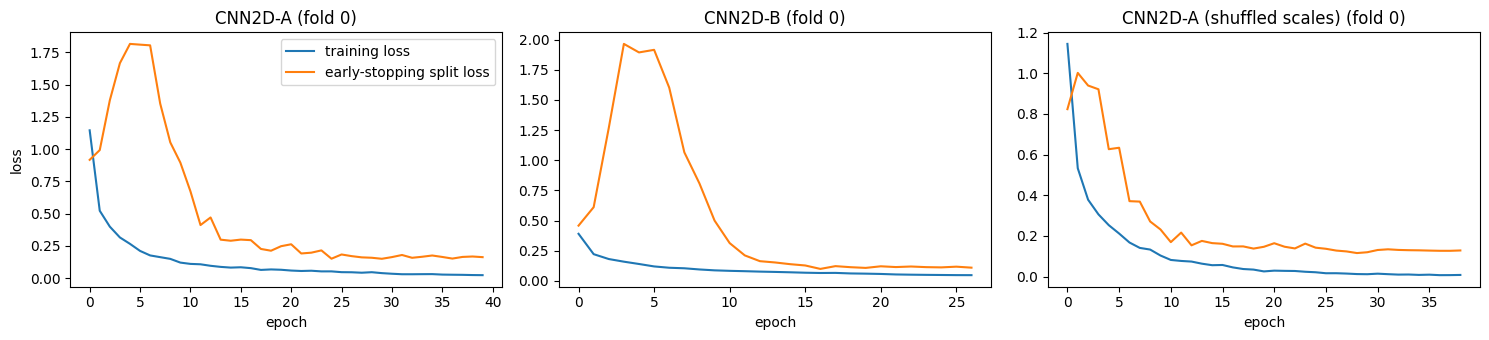

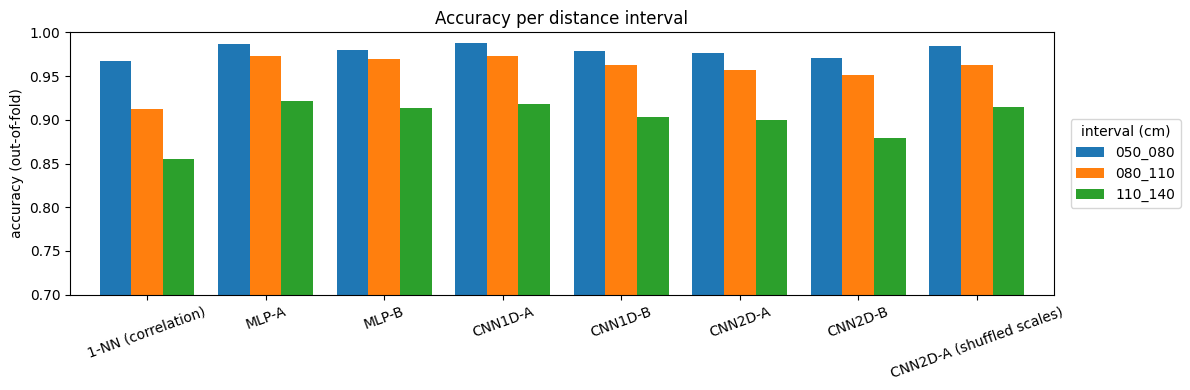

,samples
both correct,4474
only CNN1D-A correct,132
only CNN2D-A correct,59
both wrong,135


,samples
both correct,4462
only MLP-A correct,146
only CNN2D-A correct,71
both wrong,121


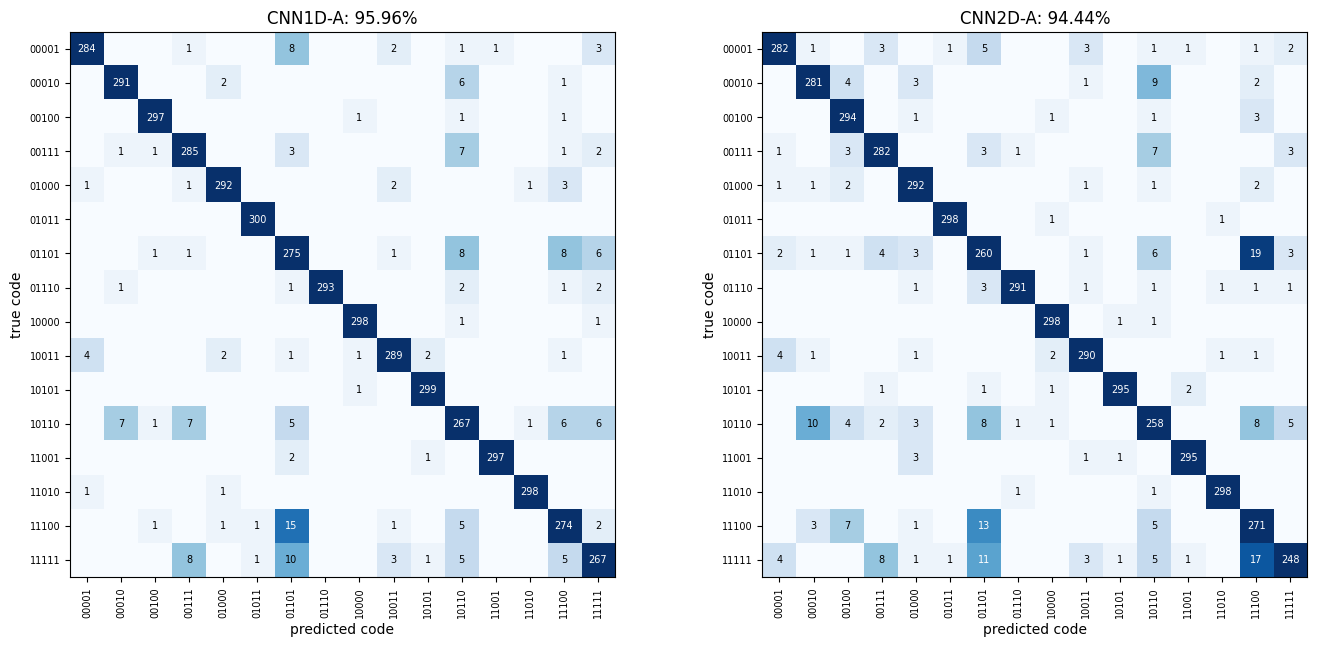

Most frequent confusions of CNN1D-A:


,true,predicted,count,bits that differ
0,11100,01101,15,2
1,11111,01101,10,2
2,11111,00111,8,2
3,01101,10110,8,4
4,01101,11100,8,2
5,00001,01101,8,2
6,10110,00010,7,2
7,10110,00111,7,2


Most frequent confusions of CNN2D-A:


,true,predicted,count,bits that differ
0,01101,11100,19,2
1,11111,11100,17,2
2,11100,01101,13,2
3,11111,01101,11,2
4,10110,00010,10,2
5,00010,10110,9,2
6,10110,11100,8,2
7,10110,01101,8,4


Errors grouped by the number of bits between the true and the predicted code:


,errors,2 bits apart (%),4 bits apart (%)
MLP-A,192,90.1,9.9
MLP-B,220,94.1,5.9
CNN1D-A,194,84.0,16.0
CNN1D-B,248,91.1,8.9
CNN2D-A,267,85.4,14.6
CNN2D-B,319,93.1,6.9


... (4 outputs left out)

Accuracy of each bit per distance interval (CNN1D-A):


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9931,0.9919,0.9962,0.9912,0.9962
080_110,0.9794,0.9925,0.9931,0.9900,0.9850
110_140,0.9469,0.9600,0.9775,0.9625,0.9631


Accuracy of each bit per distance interval (CNN2D-A):


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9850,0.9919,0.9919,0.9875,0.9912
080_110,0.9725,0.9812,0.9856,0.9788,0.9794
110_140,0.9400,0.9519,0.9712,0.9525,0.9569


In [ ]:
NN_NAMES = ['MLP-A', 'MLP-B', 'CNN1D-A', 'CNN1D-B', 'CNN2D-A', 'CNN2D-B']
CNN2D_NAMES = ['CNN2D-A', 'CNN2D-B', 'CNN2D-A (shuffled scales)']

bit_df = pd.DataFrame({n: {k: np.mean(v) for k, v in st.items()} for n, st in BIT_STATS.items()}).T
bit_df['acc. with ML decoding'] = [RESULTS[n]['mean acc'] for n in bit_df.index]
display(bit_df.style.format({'bit accuracy': '{:.4f}', 'invalid codes (%)': '{:.2f}',
                             'acc. thresholding only': '{:.4f}', 'acc. with ML decoding': '{:.4f}'}))

fig, axes = plt.subplots(1, len(CNN2D_NAMES), figsize=(15, 3.5))
for ax, name in zip(axes, CNN2D_NAMES):
    h = HISTORIES[name][0]
    ax.plot(h['loss'], label='training loss')
    ax.plot(h['val_loss'], label='early-stopping split loss')
    ax.set_title(f'{name} (fold 0)')
    ax.set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
plt.tight_layout()
plt.show()

compare = ['1-NN (correlation)'] + NN_NAMES + ['CNN2D-A (shuffled scales)']
ax = pd.DataFrame(RESULTS).T.loc[compare, INTERVALS].plot.bar(figsize=(12, 4), width=0.8)
ax.set_ylim(0.7, 1.0)
ax.set_ylabel('accuracy (out-of-fold)')
ax.set_title('Accuracy per distance interval')
ax.tick_params(axis='x', rotation=20)
ax.legend(title='interval (cm)', loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()


display(paired_comparison('CNN1D-A', 'CNN2D-A'))
display(paired_comparison('MLP-A', 'CNN2D-A'))

detailed_report(NN_NAMES, focus=['CNN1D-A', 'CNN2D-A'])

## 7.4 2D CNN conclusions

| Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm | Parameters | Time (5 folds) |
|---|---|---|---|---|---|---|
| **CNN1D-A** | **96.0% +/- 0.3** | 98.8% | 97.3% | 91.8% | 1.02 M | 133 s |
| CNN2D-A (shuffled scales) | 95.4% +/- 0.6 | 98.4% | 96.3% | 91.4% | 0.98 M | 199 s |
| CNN2D-A | 94.4% +/- 0.3 | 97.7% | 95.7% | 89.9% | 0.98 M | 215 s |
| CNN1D-B | 94.8% +/- 0.4 | 97.9% | 96.3% | 90.4% | 1.02 M | 125 s |
| CNN2D-B | 93.4% +/- 0.4 | 97.1% | 95.1% | 87.9% | 0.98 M | 204 s |

1. **The 2D CNN is worse than the 1D CNN.** CNN2D-A reaches 94.4%, 1.5 points below CNN1D-A (96.0%). The difference is about five times the fold-to-fold standard deviation (0.3), and the 1D CNN is better in each of the 5 folds. It is also better in the three distance intervals, and the gap grows with the distance (-1.1, -1.6 and -1.9 points). The same happens with branch B (93.4% vs 94.8%). Both networks have about 1 M parameters, so the model size does not explain it. The 2D CNN is also about 1.6 times slower to train.
2. **The order of the scales carries no useful information for the 2D CNN.** With the 57 scales shuffled, the same network reaches 95.4%, which is not lower than with the original order: it is higher in all 5 folds (between +0.4 and +1.6 points). If the network were using the two-dimensional shape of the notches, destroying the neighbourhood between scales would have hurt it. It does not, so what the network uses is *where along the frequency axis* the response changes, and the scale axis behaves like a set of unordered channels. This is exactly what the 1D CNN assumes.
3. **Why the 2D CNN loses (our interpretation, not verified with further experiments).** The first layer of the 1D CNN sees the 57 scales at the same time, with its own weights for each one. The 2D CNN applies the same small filter at every scale, only sees 3 neighbouring scales at a time and finally averages along the scale axis, so it partly loses *which* scale a response comes from. Sharing weights along an axis is a good assumption when a pattern means the same wherever it appears, as in natural images. Here it is not: a response at a small scale and the same response at a large scale describe different things. The gain of the shuffled version is consistent with this: neighbouring scales are highly redundant, and after shuffling each filter covers scales that were far apart.
4. **The bits of the 2D CNN are noisier, which makes the decoder more valuable.** With branch B, 7.9% of the thresholded codes are invalid (4.8% for the 1D CNN and 4.4% for the MLP), and the maximum-likelihood decoder raises the accuracy from 88.8% to 93.4% (+4.6 points, against +2.6 and +2.6).
5. **The two CNNs are only partly complementary.** The 2D CNN classifies correctly 59 samples that the 1D CNN misses, but the 1D CNN is right on 132 that the 2D CNN misses, and 135 are wrong for both. An ensemble of the two is therefore not an obvious gain; it will be evaluated together with the other candidates in the final phase.
6. **The structure of the errors does not change.** The most frequent confusions still involve the 1x1 tags, bit 1 is still the hardest one and the far interval the worst (section 6.7). The 2D CNN makes more of the same errors, not different ones.

**Decision:** the 2D CNN is discarded. The comparison is still a useful result: it shows that, for these images, the information is positional along the frequency axis, and it justifies keeping the simpler and faster **CNN1D-A** (together with MLP-A) as the base for the improvements of the next section.

# 8. Multi-task model (branch C): class and bits at the same time

So far every network had a single output: the class (branch A) or the 5 bits (branch B). Branch C is **one network with both outputs**. The backbone is shared and two heads are attached to it:
- a **class head**: 16 softmax outputs, as in branch A;
- a **bit head**: 5 sigmoid outputs, as in branch B.

**Why it could help.** The two targets describe the same label in two ways. The class head learns the 16 complete patterns, which is what gave the best accuracy in section 6. The bit head forces the shared features to answer a more physical question, 'is there a notch in this sub-band?', for each of the 5 sub-bands. This acts as an auxiliary task: it adds supervision that is consistent with the main task and can regularise the backbone, which is useful because the networks of section 6 overfit.

**Loss.** The total loss is the sum of the two losses: the categorical cross-entropy of the class head plus the binary cross-entropy of the bit head. Keras averages the binary cross-entropy over the 5 bits, so the bit term is multiplied by 5. In this way both terms are the negative log-likelihood of the complete label and have a comparable scale, and neither head dominates the training.

**Prediction.** A multi-task network gives three ways of predicting the class, and we compare the three:
- **class head only**: the most probable of the 16 softmax outputs;
- **bit head only**: maximum-likelihood decoding of the 5 bits, as in branch B;
- **both heads**: for each of the 16 tags we add the log-probability given by the class head and the log-likelihood of its code given by the bit head, and pick the tag with the highest sum. The two heads vote, each one with its own confidence.

**Architecture.** Branch C is applied to the **1D CNN**, the base model chosen in section 7.4, and also to the MLP, which had the same accuracy and is cheap to train. The backbones, optimiser, callbacks and folds are the same as in section 6, so the only change is the second head (85 extra weights for the CNN).

In [ ]:
BIT_WEIGHT = N_BITS


def build_multitask(arch):
    inp = keras.Input(shape=INPUT_SHAPE)
    feat = BACKBONES[arch](inp)
    out_class = layers.Dense(N_CLASSES, activation='softmax', name='class')(feat)
    out_bits = layers.Dense(N_BITS, activation='sigmoid', name='bits')(feat)
    model = keras.Model(inp, [out_class, out_bits], name=f'{arch}_C')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss=['sparse_categorical_crossentropy', 'binary_crossentropy'],
                  loss_weights=[1.0, BIT_WEIGHT])
    return model


def bit_log_likelihood(p_bits, eps=1e-7):
    return np.log(p_bits + eps) @ CODEBOOK.T + np.log(1 - p_bits + eps) @ (1 - CODEBOOK).T


def store_proba(name, va, p):
    OOF_PROBA.setdefault(name, np.zeros((len(y_train), p.shape[1]), dtype=np.float32))[va] = p


def multitask_model(arch, name):
    def fit_predict(X_tr, y_tr, X_va, tr, va):
        keras.backend.clear_session()
        tf.random.set_seed(SEED)
        X_fit, X_es, y_fit, y_es = train_test_split(X_tr, y_tr, test_size=0.1, stratify=y_tr, random_state=SEED)

        model = build_multitask(arch)
        MODEL_PARAMS[name] = model.count_params()
        callbacks = [
            keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
        ]
        h = model.fit(X_fit, [y_fit, CODEBOOK[y_fit]], validation_data=(X_es, [y_es, CODEBOOK[y_es]]),
                      epochs=EPOCHS, batch_size=BATCH, callbacks=callbacks, verbose=0)
        HISTORIES.setdefault(name, []).append(h.history)
        print(f'    trained for {len(h.history["loss"])} epochs', end=' |')

        p_class, p_bits = model.predict(X_va, batch_size=256, verbose=0)
        score = np.log(p_class + 1e-7) + bit_log_likelihood(p_bits)        # both heads vote
        posterior = np.exp(score - score.max(axis=1, keepdims=True))
        store_proba(name, va, posterior / posterior.sum(axis=1, keepdims=True))
        store_proba(f'{name} (class head only)', va, p_class)
        store_proba(f'{name} (bit head only)', va, p_bits)
        return score.argmax(axis=1)
    return fit_predict


def register_oof(name, pred, parent):
    fold_acc = [accuracy_score(y_train[fold_id == k], pred[fold_id == k]) for k in range(N_FOLDS)]
    summary = {'mean acc': np.mean(fold_acc), 'std acc': np.std(fold_acc)}
    for j, itv in enumerate(INTERVALS):
        m = int_train_idx == j
        summary[itv] = accuracy_score(y_train[m], pred[m])
    summary['time (s)'] = RESULTS[parent]['time (s)']
    RESULTS[name], OOF_PRED[name], MODEL_PARAMS[name] = summary, pred, MODEL_PARAMS[parent]
    print(f'{name}: {summary["mean acc"]:.4f} +/- {summary["std acc"]:.4f}')


def register_single_heads(name):
    register_oof(f'{name} (class head only)', OOF_PROBA[f'{name} (class head only)'].argmax(axis=1), name)
    register_oof(f'{name} (bit head only)', decode_bits(OOF_PROBA[f'{name} (bit head only)']), name)


m = build_multitask('cnn1d')
print(f'{m.name}: {m.count_params():,} parameters')

cnn1d_C: 1,021,717 parameters


## 8.1 Training

Each model is trained once per fold. The prediction stored as `CNN1D-C` / `MLP-C` is the one that combines both heads. The predictions of each head alone come from the same trained networks, so the three variants are compared on exactly the same models.

In [ ]:
cross_validate('CNN1D-C', multitask_model('cnn1d', 'CNN1D-C'))
register_single_heads('CNN1D-C')

_ = cross_validate('MLP-C', multitask_model('mlp', 'MLP-C'))
register_single_heads('MLP-C')

    trained for 32 epochs |  fold 0: 0.9490
    trained for 33 epochs |  fold 1: 0.9604
    trained for 27 epochs |  fold 2: 0.9531
    trained for 36 epochs |  fold 3: 0.9510
    trained for 35 epochs |  fold 4: 0.9542
CNN1D-C: 0.9535 +/- 0.0039   (139 s)
CNN1D-C (class head only): 0.9567 +/- 0.0039
CNN1D-C (bit head only): 0.9446 +/- 0.0049
    trained for 31 epochs |  fold 0: 0.9563
    trained for 36 epochs |  fold 1: 0.9552
    trained for 33 epochs |  fold 2: 0.9563
    trained for 38 epochs |  fold 3: 0.9448
    trained for 41 epochs |  fold 4: 0.9635
MLP-C: 0.9552 +/- 0.0060   (113 s)
MLP-C (class head only): 0.9577 +/- 0.0036
MLP-C (bit head only): 0.9496 +/- 0.0074


## 8.2 Comparison with branches A and B

- Results of the three branches for each architecture, and of the three ways of predicting with branch C.
- Quality of the raw bits of the bit head (before decoding), compared with the single-task branch B: does learning the class at the same time improve the bits?
- Sample-by-sample comparison of branch C with branch A.
- Learning curves of fold 0 and the detailed metrics of section 6.6.
- A final table with every model evaluated so far: accuracy, accuracy per interval, number of parameters and training time.

,mean acc,std acc,050_080,080_110,110_140
CNN1D-A,0.9596,0.0028,0.9881,0.9725,0.9181
CNN1D-B,0.9483,0.0036,0.9788,0.9625,0.9038
CNN1D-C,0.9535,0.0039,0.9806,0.9663,0.9137
CNN1D-C (class head only),0.9567,0.0039,0.9862,0.9669,0.9169
CNN1D-C (bit head only),0.9446,0.0049,0.9738,0.9619,0.8981


,mean acc,std acc,050_080,080_110,110_140
MLP-A,0.9600,0.0014,0.9862,0.9725,0.9213
MLP-B,0.9542,0.0060,0.9800,0.9694,0.9131
MLP-C,0.9552,0.0060,0.9825,0.9669,0.9163
MLP-C (class head only),0.9577,0.0036,0.9850,0.9681,0.9200
MLP-C (bit head only),0.9496,0.0074,0.9788,0.9637,0.9062


,bit accuracy,invalid codes (%),acc. thresholding only,acc. with ML decoding
MLP-B,0.9785,4.44,0.9287,0.9542
MLP-C (bit head only),0.9774,4.42,0.9267,0.9496
CNN1D-B,0.9755,4.81,0.9221,0.9483
CNN1D-C (bit head only),0.9749,5.44,0.9165,0.9446


,samples
both correct,4526
only CNN1D-A correct,80
only CNN1D-C correct,51
both wrong,143


,samples
both correct,4538
only MLP-A correct,70
only MLP-C correct,47
both wrong,145


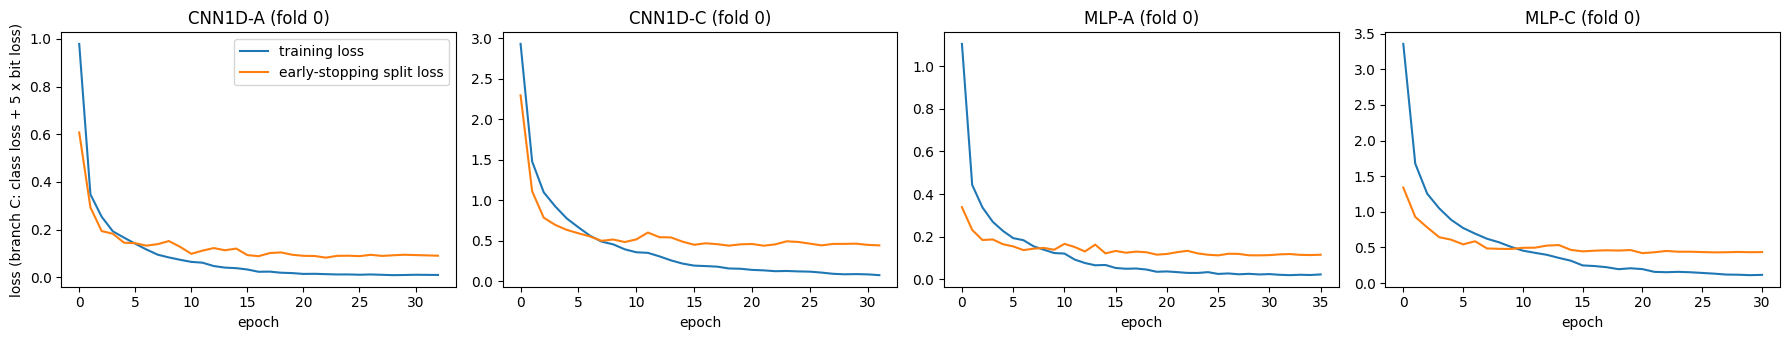

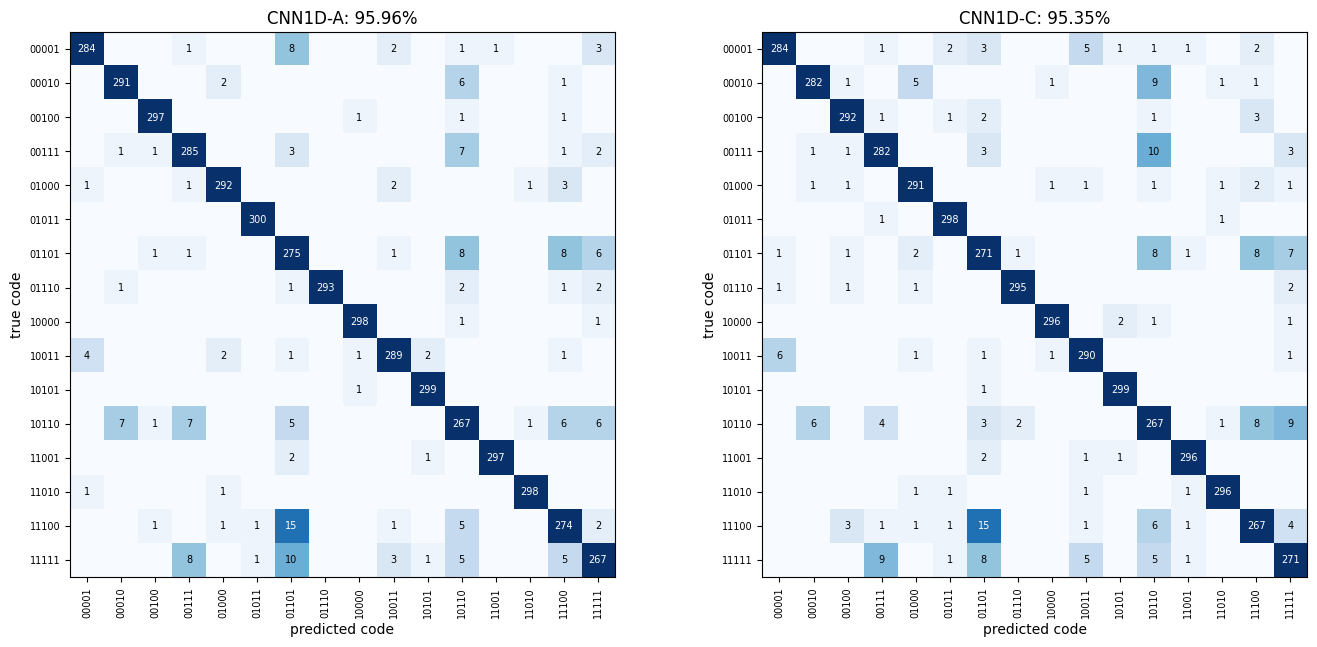

Most frequent confusions of CNN1D-A:


,true,predicted,count,bits that differ
0,11100,01101,15,2
1,11111,01101,10,2
2,11111,00111,8,2
3,01101,10110,8,4
4,01101,11100,8,2
5,00001,01101,8,2
6,10110,00010,7,2
7,10110,00111,7,2


Most frequent confusions of CNN1D-C:


,true,predicted,count,bits that differ
0,11100,01101,15,2
1,00111,10110,10,2
2,10110,11111,9,2
3,11111,00111,9,2
4,00010,10110,9,2
5,01101,10110,8,4
6,10110,11100,8,2
7,11111,01101,8,2


Errors grouped by the number of bits between the true and the predicted code:


,errors,2 bits apart (%),4 bits apart (%)
MLP-A,192,90.1,9.9
MLP-C,215,92.6,7.4
CNN1D-A,194,84.0,16.0
CNN1D-C,223,88.3,11.7
CNN1D-C (bit head only),266,94.0,6.0


... (5 outputs left out)

,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9931,0.9919,0.9962,0.9912,0.9962
080_110,0.9794,0.9925,0.9931,0.9900,0.9850
110_140,0.9469,0.9600,0.9775,0.9625,0.9631


Accuracy of each bit per distance interval (CNN1D-C):


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9912,0.9919,0.9931,0.9912,0.9938
080_110,0.9794,0.9850,0.9906,0.9869,0.9856
110_140,0.9419,0.9569,0.9788,0.9625,0.9600


,mean acc,std acc,050_080,080_110,110_140,time (s),parameters
MLP-A,0.9600,0.0014,0.9862,0.9725,0.9213,102,"3,057,424"
CNN1D-A,0.9596,0.0028,0.9881,0.9725,0.9181,133,"1,021,072"
MLP-C (class head only),0.9577,0.0036,0.9850,0.9681,0.9200,113,"3,058,709"
CNN1D-C (class head only),0.9567,0.0039,0.9862,0.9669,0.9169,139,"1,021,717"
MLP-C,0.9552,0.0060,0.9825,0.9669,0.9163,113,"3,058,709"
MLP-B,0.9542,0.0060,0.9800,0.9694,0.9131,113,"3,054,597"
CNN2D-A (shuffled scales),0.9538,0.0057,0.9844,0.9625,0.9144,199,"977,104"
CNN1D-C,0.9535,0.0039,0.9806,0.9663,0.9137,139,"1,021,717"
MLP-C (bit head only),0.9496,0.0074,0.9788,0.9637,0.9062,113,"3,058,709"
CNN1D-B,0.9483,0.0036,0.9788,0.9625,0.9038,125,"1,019,653"


In [ ]:
def branch_table(prefix):
    names = [f'{prefix}-A', f'{prefix}-B', f'{prefix}-C',
             f'{prefix}-C (class head only)', f'{prefix}-C (bit head only)']
    fmt = {c: '{:.4f}' for c in ['mean acc', 'std acc'] + INTERVALS}
    return pd.DataFrame(RESULTS).T.loc[names, ['mean acc', 'std acc'] + INTERVALS].style.format(fmt)


def raw_bit_quality(names):
    rows = {}
    true_bits = CODEBOOK[y_train].astype(int)
    for name in names:
        hard = (OOF_PROBA[name] > 0.5).astype(int)
        is_valid = (hard[:, None, :] == CODEBOOK[None].astype(int)).all(-1).any(-1)
        rows[name] = {'bit accuracy': (hard == true_bits).mean(),
                      'invalid codes (%)': 100 * (~is_valid).mean(),
                      'acc. thresholding only': (hard == true_bits).all(axis=1).mean(),
                      'acc. with ML decoding': (decode_bits(OOF_PROBA[name]) == y_train).mean()}
    return pd.DataFrame(rows).T.style.format({'bit accuracy': '{:.4f}', 'invalid codes (%)': '{:.2f}',
                                              'acc. thresholding only': '{:.4f}', 'acc. with ML decoding': '{:.4f}'})


display(branch_table('CNN1D'))
display(branch_table('MLP'))

display(raw_bit_quality(['MLP-B', 'MLP-C (bit head only)', 'CNN1D-B', 'CNN1D-C (bit head only)']))

display(paired_comparison('CNN1D-A', 'CNN1D-C'))
display(paired_comparison('MLP-A', 'MLP-C'))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, name in zip(axes, ['CNN1D-A', 'CNN1D-C', 'MLP-A', 'MLP-C']):
    h = HISTORIES[name][0]
    ax.plot(h['loss'], label='training loss')
    ax.plot(h['val_loss'], label='early-stopping split loss')
    ax.set_title(f'{name} (fold 0)')
    ax.set_xlabel('epoch')
axes[0].set_ylabel('loss (branch C: class loss + 5 x bit loss)')
axes[0].legend()
plt.tight_layout()
plt.show()

detailed_report(['MLP-A', 'MLP-C', 'CNN1D-A', 'CNN1D-C', 'CNN1D-C (bit head only)'], focus=['CNN1D-A', 'CNN1D-C'])

display(full_table())

## 8.3 Multi-task conclusions

| Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm |
|---|---|---|---|---|
| **CNN1D-A** | **96.0% +/- 0.3** | 98.8% | 97.3% | 91.8% |
| CNN1D-C (class head only) | 95.7% +/- 0.4 | 98.6% | 96.7% | 91.7% |
| CNN1D-C (both heads) | 95.4% +/- 0.4 | 98.1% | 96.6% | 91.4% |
| CNN1D-B | 94.8% +/- 0.4 | 97.9% | 96.3% | 90.4% |
| CNN1D-C (bit head only) | 94.5% +/- 0.5 | 97.4% | 96.2% | 89.8% |
| **MLP-A** | **96.0% +/- 0.1** | 98.6% | 97.3% | 92.1% |
| MLP-C (class head only) | 95.8% +/- 0.4 | 98.5% | 96.8% | 92.0% |
| MLP-C (both heads) | 95.5% +/- 0.6 | 98.3% | 96.7% | 91.6% |
| MLP-B | 95.4% +/- 0.6 | 98.0% | 96.9% | 91.3% |
| MLP-C (bit head only) | 95.0% +/- 0.7 | 97.9% | 96.4% | 90.6% |

1. **The multi-task model does not improve on branch A.** Its best variant, the class head alone, reaches 95.7% (CNN) and 95.8% (MLP), 0.2-0.3 points below the single-task branch A (96.0%). This difference is of the same size as the fold-to-fold standard deviation (0.1-0.6), so we cannot say that the bit head harms the class head, but it clearly does not help it.
2. **Letting both heads vote is worse than using the class head alone** (95.4% vs 95.7% for the CNN, 95.5% vs 95.8% for the MLP). The order is the same for both architectures: class head > both heads > bit head. The bit head is the weaker predictor, and both heads read the same shared features, so their mistakes are not independent: adding a weaker voter that fails on similar samples pulls the result down instead of correcting it. The sample-by-sample comparison shows the same: CNN1D-C is right on 51 samples that CNN1D-A misses, but CNN1D-A is right on 80 that CNN1D-C misses, and 143 are wrong for both.
3. **The bit head does not benefit from the class task either.** Its raw bits are as good as those of the single-task branch B, not better: bit accuracy 97.5% vs 97.6% (CNN) and 97.7% vs 97.9% (MLP), invalid codes 5.4% vs 4.8% and 4.4% vs 4.4%, accuracy after decoding 94.5% vs 94.8% and 95.0% vs 95.4%.
4. **Why the auxiliary task adds nothing (our interpretation).** An auxiliary task helps when it brings information that the main task does not have. Here the 5 bits are a fixed function of the class: knowing the class already tells every bit. The softmax of branch A must already encode which notches are present in order to separate the 16 tags, so asking for the bits explicitly does not give the backbone anything new to learn.
5. **The structure of the errors is again the same.** The 8 most frequent confusions of CNN1D-C all involve a 1x1 tag, bit 1 is the hardest one (97.1%) and the far interval the worst (section 6.7).
6. **Limitation.** A single weighting of the two losses was tested (class loss + 5 x bit loss). A smaller weight for the bit loss could behave differently; given conclusions 3 and 4, we do not expect it to change the outcome.

**Decision:** branch C is discarded and **branch A** is kept as the output of the final model.

**Overall picture after sections 6, 7 and 8.** Three architectures (MLP, 1D CNN, 2D CNN) and three ways of producing the output (class, bits, both) have been compared with the same folds, and none of them goes beyond **96.0%** (see the final table above). The remaining errors are the same for every model: 1x1 tags, the lowest sub-band and the far interval. The limit is therefore not in the architecture or in the form of the output, but in the noisy measurements themselves. The next steps act on that: data augmentation and regularisation, hyper-parameter tuning, and an ensemble of the best models.

# 9. Improvements on the best model

Sections 6, 7 and 8 compared architectures and output types, and none of them went beyond 96.0%. The remaining errors are the same for every model (1x1 tags, the lowest sub-band and the far interval), and the learning curves show overfitting. This section therefore keeps the architecture and acts on **how the model is trained**, in four steps:

| Step | What changes | Question |
|---|---|---|
| 9.2 Data augmentation | Random, physically plausible changes of the training images | Does showing the network more variability reduce overfitting? |
| 9.3 Distance interval as input | The interval of each measurement is given to the network | Does knowing the distance help to interpret a noisy signal? |
| 9.4 Regularisation | Weight decay and label smoothing | Do the classic regularisers help on top of dropout and early stopping? |
| 9.5 Hyper-parameter search | Optuna explores architecture, optimiser, regularisation and augmentation together | How much do the manual choices leave on the table? |

**Base model: CNN1D-A.** It ties with MLP-A (96.0%) with 3 times fewer parameters, its first layer has a separate weight for each CWT scale (section 7.4), and its size makes the search of 9.5 affordable.

**Protocol**
- Every experiment uses the same 5 folds as the rest of the notebook.
- The steps are **greedy**: each one starts from the best model of the previous step, and only one thing is changed at a time, so every gain can be attributed to a single change.
- A change is **kept** only if it improves the mean accuracy **and** improves the accuracy in at least 3 of the 5 folds. The second condition protects against keeping a change that only wins on average because of one lucky fold (the fold-to-fold standard deviation is about 0.4 points).
- All the models of this section are trained with the same input pipeline (9.1). The base model is re-trained with it, and every change is compared with that re-run rather than with the CNN1D-A of section 6, so that the comparison is not affected by small differences between the two pipelines.

## 9.1 Configurable model and training pipeline

All the experiments of this section are described by a **configuration** dictionary. `BASE_CFG` reproduces CNN1D-A of section 6 exactly: same architecture, Adam with learning rate 1e-3 and no weight decay, no augmentation.

- `build_cnn1d_cfg(cfg)` builds the 1D CNN. The number of filters (`width`), the kernel size, the size of the dense layer and the two dropout rates are parameters. If `use_interval` is set, the one-hot interval is concatenated to the flattened convolutional features, before the dense layer, so that the dense layer can combine it with the patterns found by the convolutions.
- The optimiser is **AdamW** (Adam with decoupled weight decay); with `weight_decay = 0` it is plain Adam. The loss is the categorical cross-entropy with optional **label smoothing**. One-hot targets are used instead of class indices because mixup produces mixed targets.
- `make_augment(cfg, mu, sd)` applies the augmentations to each training batch, on the fly, so that the network never sees exactly the same image twice. The validation fold and the inner early-stopping split are never augmented.
- `cfg_model(cfg, name)` trains a new model on every fold and plugs into `cross_validate`, like every previous model.
- `keeps(name, ref)` implements the rule of the protocol and `best_of(candidates, ref)` returns the best candidate that satisfies it (or the reference if none does).

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
N_INTERVALS = len(INTERVALS)
ITV_ONEHOT = np.eye(N_INTERVALS, dtype=np.float32)[int_train_idx]

BASE_CFG = {
    'width': 1.0, 'kernel': 7, 'dense': 128, 'drop_conv': 0.2, 'drop_dense': 0.4,
    'lr': 1e-3, 'weight_decay': 0.0, 'label_smoothing': 0.0,
    'noise': 0.0, 'shift': 0, 'scale': 0.0, 'mixup': 0.0,
    'use_interval': False,
}
CFGS = {}   # model name -> configuration used to train it


def build_cnn1d_cfg(cfg):
    inp = keras.Input(shape=INPUT_SHAPE)
    x = inp
    for filters in [64, 128, 128]:
        x = layers.Conv1D(int(filters * cfg['width']), kernel_size=cfg['kernel'], padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling1D(pool_size=2)(x)
        x = layers.Dropout(cfg['drop_conv'])(x)
    x = layers.Flatten()(x)
    inputs = inp
    if cfg['use_interval']:
        itv = keras.Input(shape=(N_INTERVALS,))
        inputs = [inp, itv]
        x = layers.Concatenate()([x, itv])
    x = layers.Dense(cfg['dense'])(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(cfg['drop_dense'])(x)
    out = layers.Dense(N_CLASSES, activation='softmax')(x)
    model = keras.Model(inputs, out)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=cfg['lr'], weight_decay=cfg['weight_decay']),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=cfg['label_smoothing']),
                  metrics=['accuracy'])
    return model


def make_augment(cfg, mu, sd):
    mu, sd = tf.constant(mu), tf.constant(sd)
    n_freq = INPUT_SHAPE[0]

    def augment(x, itv, y):
        b = tf.shape(x)[0]
        if cfg['scale'] > 0 or cfg['shift'] > 0:
            raw = x * sd + mu                     # undo the normalisation: scale and shift act on the measured intensity
            if cfg['scale'] > 0:
                raw = raw * tf.random.uniform([b, 1, 1], 1 - cfg['scale'], 1 + cfg['scale'])
            if cfg['shift'] > 0:
                k = tf.random.uniform([b, 1], -cfg['shift'], cfg['shift'] + 1, dtype=tf.int32)
                idx = tf.clip_by_value(tf.range(n_freq)[None, :] - k, 0, n_freq - 1)   # the edge bin is repeated
                raw = tf.gather(raw, idx, axis=1, batch_dims=1)
            x = (raw - mu) / sd
        if cfg['noise'] > 0:
            x = x + tf.random.normal(tf.shape(x), stddev=cfg['noise'])
        if cfg['mixup'] > 0:
            g1 = tf.random.gamma([b], cfg['mixup'])
            g2 = tf.random.gamma([b], cfg['mixup'])
            lam = g1 / (g1 + g2 + 1e-8)           # lam ~ Beta(alpha, alpha)
            perm = tf.random.shuffle(tf.range(b))
            x = lam[:, None, None] * x + (1 - lam[:, None, None]) * tf.gather(x, perm)
            itv = lam[:, None] * itv + (1 - lam[:, None]) * tf.gather(itv, perm)
            y = lam[:, None] * y + (1 - lam[:, None]) * tf.gather(y, perm)
        return x, itv, y
    return augment


def model_inputs(cfg, X, itv):
    return (X, itv) if cfg['use_interval'] else X


def train_cfg(cfg, X_tr, y_tr, X_va, tr, va):
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    mu, sd = fit_feature_stats(X_train_ds[tr])   # the statistics get_fold used to normalise this fold
    fit, es = train_test_split(np.arange(len(tr)), test_size=0.1, stratify=y_tr, random_state=SEED)
    Y_tr = np.eye(N_CLASSES, dtype=np.float32)[y_tr]
    I_tr, I_va = ITV_ONEHOT[tr], ITV_ONEHOT[va]

    ds = (tf.data.Dataset.from_tensor_slices((X_tr[fit], I_tr[fit], Y_tr[fit]))
          .shuffle(len(fit), seed=SEED)
          .batch(BATCH)
          .map(make_augment(cfg, mu, sd), num_parallel_calls=AUTOTUNE)
          .map(lambda x, i, y: (model_inputs(cfg, x, i), y))
          .prefetch(AUTOTUNE))

    model = build_cnn1d_cfg(cfg)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
    ]
    h = model.fit(ds, validation_data=(model_inputs(cfg, X_tr[es], I_tr[es]), Y_tr[es]),
                  epochs=EPOCHS, callbacks=callbacks, verbose=0)
    p = model.predict(model_inputs(cfg, X_va, I_va), batch_size=256, verbose=0)
    return model, h, p


def cfg_model(cfg, name):
    CFGS[name] = dict(cfg)

    def fit_predict(X_tr, y_tr, X_va, tr, va):
        model, h, p = train_cfg(cfg, X_tr, y_tr, X_va, tr, va)
        MODEL_PARAMS[name] = model.count_params()
        HISTORIES.setdefault(name, []).append(h.history)
        OOF_PROBA.setdefault(name, np.zeros((len(y_train), N_CLASSES), dtype=np.float32))[va] = p
        print(f'    trained for {len(h.history["loss"])} epochs', end=' |')
        return p.argmax(axis=1)
    return fit_predict


def run_variant(name, ref, changes):
    return cross_validate(name, cfg_model({**CFGS[ref], **changes}, name))


def fold_accuracies(name, folds=range(N_FOLDS)):
    return np.array([accuracy_score(y_train[fold_id == k], OOF_PRED[name][fold_id == k]) for k in folds])


def keeps(name, ref):
    d = fold_accuracies(name) - fold_accuracies(ref)
    return d.mean() > 0 and (d > 0).sum() >= 3


def best_of(candidates, ref):
    kept = [n for n in candidates if keeps(n, ref)]
    return max(kept, key=lambda n: RESULTS[n]['mean acc']) if kept else ref


def change_table(candidates, ref):
    rows = {}
    for n in [ref] + list(candidates):
        d = fold_accuracies(n) - fold_accuracies(ref)
        rows[n] = {'mean acc': RESULTS[n]['mean acc'], 'std acc': RESULTS[n]['std acc'],
                   **{itv: RESULTS[n][itv] for itv in INTERVALS},
                   'gain (points)': 100 * d.mean(), 'folds improved': int((d > 0).sum()),
                   'kept': '-' if n == ref else ('yes' if keeps(n, ref) else 'no')}
    fmt = {c: '{:.4f}' for c in ['mean acc', 'std acc'] + INTERVALS}
    fmt['gain (points)'] = '{:+.2f}'
    return pd.DataFrame(rows).T.style.format(fmt)


m = build_cnn1d_cfg(BASE_CFG)
print(f'Base configuration: {m.count_params():,} parameters (CNN1D-A: {MODEL_PARAMS.get("CNN1D-A", "not trained in this session")})')

Base configuration: 1,021,072 parameters (CNN1D-A: 1021072)


## 9.2 Data augmentation

The training set has 3,456 images per fold for 16 classes, and the networks of section 6 learn it almost perfectly while the validation loss stops improving after 10-15 epochs. Data augmentation creates new, slightly different training images at every epoch, so the network cannot memorise them. The changes must be **physically plausible**: they must look like another real measurement of the same tag, never like a different tag.

| Technique | What it does | Physical motivation | Value tested |
|---|---|---|---|
| **Noise** | Adds Gaussian noise to every pixel of the normalised image | Measurement noise and interference, the main effect of the distance (EDA, section 2.3) | std 0.1 (in units of the per-position std) |
| **Frequency shift** | Shifts the whole image along the frequency axis by a random number of bins | Small changes of the resonance frequencies due to the inclination of the tag or manufacturing tolerances | up to +/- 2 bins (+/- 17.5 MHz) |
| **Amplitude scaling** | Multiplies the measured intensity by a random factor | The received power changes with the distance and the inclination | factor in [0.9, 1.1] |
| **Mixup** | Replaces each image by a weighted mix of two training images, and mixes their labels with the same weight | Not physical: a regulariser that encourages smooth transitions between classes instead of sharp, over-confident boundaries | weights from Beta(0.2, 0.2), mostly close to 0 or 1 |

**Why the shift is so small.** Each bit is defined by the sub-band where the notch is. The narrowest sub-band is 0.5 GHz wide (57 bins after downsampling), so a shift of at most 2 bins can never move a notch to another sub-band, and therefore never changes the label.

**Why scale and shift act on the measured intensity.** The images are normalised position by position (section 4.2). Scaling or shifting the normalised image would not correspond to any real change of the signal, so the augmentation first undoes the normalisation, applies the change and normalises again with the same statistics.

The figure shows the effect of each technique on one training image, as the mean over the 57 scales along the frequency axis (the sub-bands are delimited by the dashed lines). Then each technique is evaluated **alone** against the base model, and the ones that are kept are combined.

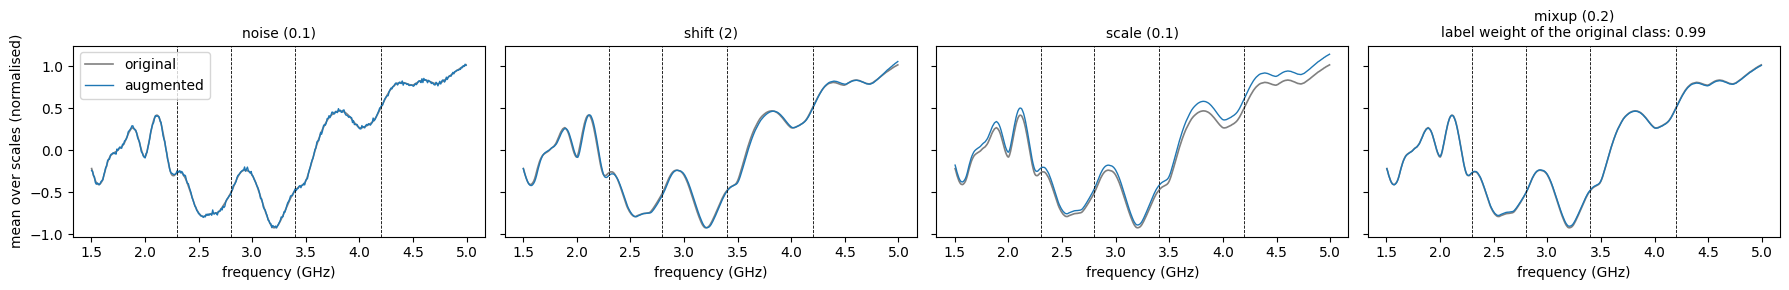

In [ ]:
AUGMENTATIONS = {'noise': 0.1, 'shift': 2, 'scale': 0.1, 'mixup': 0.2}

tr0 = np.where(fold_id != 0)[0]
mu0, sd0 = fit_feature_stats(X_train_ds[tr0])
demo_idx = np.where(int_train_idx == 2)[0][:64]                 # one batch of far-interval samples
demo_x = normalize(X_train_ds[demo_idx], 'feature', (mu0, sd0)).astype(np.float32)
demo_y = np.eye(N_CLASSES, dtype=np.float32)[y_train[demo_idx]]
demo_i = ITV_ONEHOT[demo_idx]
freqs_ds_ghz = freqs_ds / 1e9

tf.random.set_seed(SEED)
fig, axes = plt.subplots(1, len(AUGMENTATIONS), figsize=(18, 3), sharey=True)
for ax, (aug, value) in zip(axes, AUGMENTATIONS.items()):
    x_aug, _, y_aug = make_augment({**BASE_CFG, aug: value}, mu0, sd0)(demo_x, demo_i, demo_y)
    ax.plot(freqs_ds_ghz, demo_x[0].mean(axis=1), color='grey', lw=1.2, label='original')
    ax.plot(freqs_ds_ghz, x_aug.numpy()[0].mean(axis=1), lw=1, label='augmented')
    for edge in SUBBAND_EDGES_GHZ[1:-1]:
        ax.axvline(edge, color='black', ls='--', lw=0.6)
    title = f'{aug} ({value})'
    if aug == 'mixup':
        title += f'\nlabel weight of the original class: {y_aug.numpy()[0, y_train[demo_idx[0]]]:.2f}'
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('frequency (GHz)')
axes[0].set_ylabel('mean over scales (normalised)')
axes[0].legend()
plt.tight_layout()
plt.show()

In [ ]:
BASE = 'CNN1D base (sec. 9)'
cross_validate(BASE, cfg_model(BASE_CFG, BASE))

aug_names = []
for aug, value in AUGMENTATIONS.items():
    aug_names.append(f'CNN1D + {aug}')
    run_variant(aug_names[-1], BASE, {aug: value})

kept_augs = [aug for aug in AUGMENTATIONS if keeps(f'CNN1D + {aug}', BASE)]
if len(kept_augs) >= 2:
    aug_names.append('CNN1D + ' + ' + '.join(kept_augs))
    run_variant(aug_names[-1], BASE, {aug: AUGMENTATIONS[aug] for aug in kept_augs})

display(change_table(aug_names, BASE))
CURRENT = best_of(aug_names, BASE)
print('Kept after the augmentation step:', CURRENT)

    trained for 21 epochs |  fold 0: 0.9646
    trained for 35 epochs |  fold 1: 0.9594
    trained for 26 epochs |  fold 2: 0.9604
    trained for 36 epochs |  fold 3: 0.9604
    trained for 24 epochs |  fold 4: 0.9542
CNN1D base (sec. 9): 0.9598 +/- 0.0033   (125 s)
    trained for 28 epochs |  fold 0: 0.9646
    trained for 41 epochs |  fold 1: 0.9635
    trained for 40 epochs |  fold 2: 0.9667
    trained for 17 epochs |  fold 3: 0.9510
    trained for 37 epochs |  fold 4: 0.9563
CNN1D + noise: 0.9604 +/- 0.0059   (149 s)
    trained for 35 epochs |  fold 0: 0.9625
    trained for 33 epochs |  fold 1: 0.9615
    trained for 33 epochs |  fold 2: 0.9656
    trained for 45 epochs |  fold 3: 0.9604
    trained for 40 epochs |  fold 4: 0.9552
CNN1D + shift: 0.9610 +/- 0.0034   (149 s)
    trained for 23 epochs |  fold 0: 0.9594
    trained for 30 epochs |  fold 1: 0.9563
    trained for 28 epochs |  fold 2: 0.9615
    trained for 42 epochs |  fold 3: 0.9615
    trained for 25 epochs |  

,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D base (sec. 9),0.9598,0.0033,0.9881,0.9719,0.9194,+0.00,0,-
CNN1D + noise,0.9604,0.0059,0.9894,0.9688,0.9231,+0.06,3,yes
CNN1D + shift,0.9610,0.0034,0.9900,0.9681,0.9250,+0.12,3,yes
CNN1D + scale,0.9587,0.0026,0.9875,0.9706,0.9181,-0.10,3,no
CNN1D + mixup,0.9596,0.0067,0.9888,0.9700,0.9200,-0.02,3,no
CNN1D + noise + shift,0.9625,0.0015,0.9888,0.9712,0.9275,+0.27,4,yes


Kept after the augmentation step: CNN1D + noise + shift


## 9.3 Distance interval as an extra input

The interval of every measurement (50-80, 80-110 or 110-140 cm) is known, also for the test set. Until now the networks ignored it. Giving it to the network could help it to interpret the signal: the same weak notch may be a real notch at 140 cm but just noise at 50 cm.

The interval is encoded as a one-hot vector of 3 values and concatenated to the convolutional features, before the dense layer. This is an **ablation**: the same model is trained with and without this input, and the difference measures how much information the interval adds to what the network can already infer from the image itself (the EDA showed that the distance mainly adds noise, which the network may already recognise).

In [ ]:
itv_name = f'{CURRENT} + interval'
run_variant(itv_name, CURRENT, {'use_interval': True})
display(change_table([itv_name], CURRENT))
CURRENT = best_of([itv_name], CURRENT)
print('Kept after the interval step:', CURRENT)

    trained for 40 epochs |  fold 0: 0.9583
    trained for 28 epochs |  fold 1: 0.9656
    trained for 25 epochs |  fold 2: 0.9656
    trained for 42 epochs |  fold 3: 0.9604
    trained for 27 epochs |  fold 4: 0.9615
CNN1D + noise + shift + interval: 0.9623 +/- 0.0029   (167 s)


,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D + noise + shift,0.9625,0.0015,0.9888,0.9712,0.9275,+0.00,0,-
CNN1D + noise + shift + interval,0.9623,0.0029,0.9875,0.9738,0.9256,-0.02,3,no


Kept after the interval step: CNN1D + noise + shift


## 9.4 Regularisation

The model already uses three regularisers since section 6: **dropout** (0.2 after each convolutional block, 0.4 in the dense layer), **early stopping** (patience 10, best weights restored) and **learning-rate reduction on plateau** (x0.5 after 4 epochs without improvement), the last two monitored on the inner 10% split. This step tests two more:

- **Weight decay** (1e-2, decoupled, AdamW). At every step it shrinks all the weights slightly towards zero, which penalises solutions that rely on a few very large weights. It acts on all the layers, including the dense layer that holds about 80% of the parameters and is the most likely place for overfitting.
- **Label smoothing** (0.1). The target of the correct class becomes 0.9 instead of 1, and the other 15 classes share the remaining 0.1. The network is no longer pushed to output probabilities of exactly 1, which is what drives the training loss to zero and makes the model over-confident.

Each one is tested alone and, if both are kept, together. The dropout rates are not changed here: they are tuned, together with everything else, in the hyper-parameter search of 9.5.

In [ ]:
REGULARISERS = {'weight decay': {'weight_decay': 1e-2}, 'label smoothing': {'label_smoothing': 0.1}}

ref = CURRENT
reg_names = []
for reg, changes in REGULARISERS.items():
    reg_names.append(f'{ref} + {reg}')
    run_variant(reg_names[-1], ref, changes)

kept_regs = [reg for reg in REGULARISERS if keeps(f'{ref} + {reg}', ref)]
if len(kept_regs) == 2:
    reg_names.append(f'{ref} + ' + ' + '.join(kept_regs))
    run_variant(reg_names[-1], ref, {**REGULARISERS['weight decay'], **REGULARISERS['label smoothing']})

display(change_table(reg_names, ref))
MANUAL_BEST = best_of(reg_names, ref)
print('Best model of the manual steps:', MANUAL_BEST)
display(pd.Series(CFGS[MANUAL_BEST], name=MANUAL_BEST).to_frame())

    trained for 37 epochs |  fold 0: 0.9594
    trained for 37 epochs |  fold 1: 0.9656
    trained for 27 epochs |  fold 2: 0.9667
    trained for 31 epochs |  fold 3: 0.9594
    trained for 26 epochs |  fold 4: 0.9594
CNN1D + noise + shift + weight decay: 0.9621 +/- 0.0033   (159 s)
    trained for 37 epochs |  fold 0: 0.9667
    trained for 44 epochs |  fold 1: 0.9688
    trained for 53 epochs |  fold 2: 0.9688
    trained for 52 epochs |  fold 3: 0.9677
    trained for 40 epochs |  fold 4: 0.9583
CNN1D + noise + shift + label smoothing: 0.9660 +/- 0.0039   (196 s)


,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D + noise + shift,0.9625,0.0015,0.9888,0.9712,0.9275,+0.00,0,-
CNN1D + noise + shift + weight decay,0.9621,0.0033,0.9919,0.9750,0.9194,-0.04,2,no
CNN1D + noise + shift + label smoothing,0.9660,0.0039,0.9919,0.9794,0.9269,+0.35,4,yes


Best model of the manual steps: CNN1D + noise + shift + label smoothing


,CNN1D + noise + shift + label smoothing
width,1.0
kernel,7
dense,128
drop_conv,0.2
drop_dense,0.4
lr,0.001
weight_decay,0.0
label_smoothing,0.1
noise,0.1
shift,2


## 9.5 Hyper-parameter search with Optuna

The manual steps changed one thing at a time with fixed values. The best values, however, depend on each other: for example, more augmentation usually needs less dropout, and a wider network needs more regularisation. **Optuna** searches all of them together.

**How it works.** Optuna runs a sequence of *trials*. Each trial trains a model with one combination of hyper-parameters and returns its validation accuracy. The combinations are proposed by a **TPE sampler** (Tree-structured Parzen Estimator): after a few trials it models which values tend to give good results and which ones bad results, and proposes new combinations from the promising regions, so it needs far fewer trials than a grid or random search. A **median pruner** stops a trial early when its first fold is already worse than the median of the previous trials at the same point, which saves time for the promising ones.

**Search space** (starting from the best manual configuration, which is evaluated first):

| Group | Hyper-parameter | Range |
|---|---|---|
| Architecture | `width` (multiplier of the 64-128-128 filters) | 0.5, 1.0, 1.5 |
| | `kernel` size | 5, 7, 9, 11 |
| | `dense` units | 64, 128, 256 |
| Optimiser | learning rate | 3e-4 to 3e-3 (log scale) |
| Regularisation | weight decay | 1e-5 to 1e-1 (log scale) |
| | label smoothing | 0 to 0.2 |
| | dropout after the convolutions / in the dense layer | 0 to 0.4 / 0.2 to 0.6 |
| Augmentation | noise std / max shift (bins) / amplitude factor | 0 to 0.3 / 0 to 4 / 0 to 0.2 |
| | mixup alpha (0 = off) | 0, 0.1, 0.2, 0.4 |

The use of the interval as input is not searched: it is fixed to the decision of 9.3.

**Avoiding an optimistic estimate.** If the best of many trials were selected and evaluated on the same data, part of its accuracy would be luck: the trial that happened to fit those folds best. To avoid this, the search only uses **folds 0 and 1** (each trial trains 2 models, one per fold, and returns their mean accuracy). The selected configuration is then evaluated on all 5 folds, and its accuracy on **folds 2, 3 and 4**, which the search never used, is an unbiased estimate that can be compared fairly with the other models.

**Budget.** At most 40 trials or 30 minutes. The best parameters are saved to a JSON file next to the data, so that the final model can be trained without repeating the search.

In [ ]:
%pip install -q optuna

In [ ]:
import json
import optuna

SEARCH_FOLDS = [0, 1]
N_TRIALS = 40
TIMEOUT_S = 30 * 60
RUN_OPTUNA = True                       # False reuses the parameters saved by a previous search
BEST_PARAMS_FILE = path_files + 'optuna_best_params_cnn1d.json'


def suggest_cfg(trial):
    return {
        **CFGS[MANUAL_BEST],
        'width': trial.suggest_categorical('width', [0.5, 1.0, 1.5]),
        'kernel': trial.suggest_categorical('kernel', [5, 7, 9, 11]),
        'dense': trial.suggest_categorical('dense', [64, 128, 256]),
        'lr': trial.suggest_float('lr', 3e-4, 3e-3, log=True),
        'weight_decay': trial.suggest_float('weight_decay', 1e-5, 1e-1, log=True),
        'label_smoothing': trial.suggest_float('label_smoothing', 0.0, 0.2),
        'drop_conv': trial.suggest_float('drop_conv', 0.0, 0.4),
        'drop_dense': trial.suggest_float('drop_dense', 0.2, 0.6),
        'noise': trial.suggest_float('noise', 0.0, 0.3),
        'shift': trial.suggest_int('shift', 0, 4),
        'scale': trial.suggest_float('scale', 0.0, 0.2),
        'mixup': trial.suggest_categorical('mixup', [0.0, 0.1, 0.2, 0.4]),
    }


def objective(trial):
    cfg = suggest_cfg(trial)
    accs = []
    for step, k in enumerate(SEARCH_FOLDS):
        tr, va, X_tr, X_va = get_fold(k)
        _, _, p = train_cfg(cfg, X_tr, y_train[tr], X_va, tr, va)
        accs.append(accuracy_score(y_train[va], p.argmax(axis=1)))
        trial.report(np.mean(accs), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(accs)


def log_trial(study, trial):
    done = trial.state == optuna.trial.TrialState.COMPLETE
    value = f'{trial.value:.4f}' if done else f'pruned after fold {SEARCH_FOLDS[0]} ({trial.value:.4f})'
    print(f'trial {trial.number:2d}: {value}   best so far {study.best_value:.4f}')


if RUN_OPTUNA:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5))
    start = CFGS[MANUAL_BEST]
    study.enqueue_trial({p: start[p] for p in ['width', 'kernel', 'dense', 'lr', 'label_smoothing', 'drop_conv',
                                               'drop_dense', 'noise', 'shift', 'scale', 'mixup']}
                        | {'weight_decay': max(start['weight_decay'], 1e-5)})
    t0 = time.time()
    study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_S, callbacks=[log_trial], gc_after_trial=True)
    best_params = study.best_params
    with open(BEST_PARAMS_FILE, 'w') as f:
        json.dump(best_params, f, indent=1)
    states = pd.Series([t.state.name for t in study.trials]).value_counts().to_dict()
    print(f'\n{len(study.trials)} trials in {(time.time() - t0) / 60:.0f} min: {states}')
    print(f'Best mean accuracy on folds {SEARCH_FOLDS}: {study.best_value:.4f} (trial {study.best_trial.number})')
else:
    with open(BEST_PARAMS_FILE) as f:
        best_params = json.load(f)

TUNED_CFG = {**CFGS[MANUAL_BEST], **best_params}
display(pd.DataFrame({'manual best': CFGS[MANUAL_BEST], 'Optuna': TUNED_CFG}))

trial  0: 0.9651   best so far 0.9651
trial  1: 0.9568   best so far 0.9651
trial  2: 0.9583   best so far 0.9651
trial  3: 0.9641   best so far 0.9651
trial  4: 0.9609   best so far 0.9651
trial  5: pruned after fold 0 (0.9521)   best so far 0.9651
trial  6: 0.9672   best so far 0.9672
trial  7: pruned after fold 0 (0.9563)   best so far 0.9672
trial  8: pruned after fold 0 (0.9531)   best so far 0.9672
trial  9: pruned after fold 0 (0.9604)   best so far 0.9672
trial 10: pruned after fold 0 (0.9552)   best so far 0.9672
trial 11: pruned after fold 0 (0.9594)   best so far 0.9672
trial 12: 0.9661   best so far 0.9672
trial 13: 0.9661   best so far 0.9672
trial 14: 0.9635   best so far 0.9672
trial 15: pruned after fold 0 (0.9646)   best so far 0.9672
trial 16: 0.9646   best so far 0.9672
trial 17: 0.9651   best so far 0.9672
trial 18: pruned after fold 0 (0.9635)   best so far 0.9672
trial 19: pruned after fold 0 (0.9615)   best so far 0.9672
trial 20: pruned after fold 0 (0.9646)   b

,manual best,Optuna
width,1.0,1.5
kernel,7,9
dense,128,128
drop_conv,0.2,0.12424
drop_dense,0.4,0.250035
lr,0.001,0.00159
weight_decay,0.0,0.000068
label_smoothing,0.1,0.033949
noise,0.1,0.109437
shift,2,4


,number,value,state,dense,drop_conv,drop_dense,kernel,label_smoothing,lr,mixup,noise,scale,shift,weight_decay,width
27,27,0.9693,COMPLETE,128,0.1242,0.2500,9,0.0339,0.0016,0.1000,0.1094,0.0072,4,0.0001,1.5000
6,6,0.9672,COMPLETE,128,0.0440,0.2912,9,0.0636,0.0019,0.1000,0.1281,0.1721,4,0.0384,1.5000
24,24,0.9667,COMPLETE,128,0.1901,0.2365,9,0.0488,0.0011,0.1000,0.0813,0.1477,4,0.0000,1.5000
12,12,0.9661,COMPLETE,128,0.1176,0.4214,7,0.1892,0.0010,0.0000,0.1195,0.0032,3,0.0000,1.0000
13,13,0.9661,COMPLETE,128,0.1371,0.2634,9,0.0968,0.0015,0.1000,0.0553,0.1890,4,0.0000,1.5000
25,25,0.9661,COMPLETE,128,0.0425,0.2501,9,0.1077,0.0019,0.1000,0.1031,0.1463,4,0.0128,1.0000
17,17,0.9651,COMPLETE,128,0.0820,0.4891,9,0.1361,0.0014,0.0000,0.1214,0.0642,4,0.0004,1.0000
0,0,0.9651,COMPLETE,128,0.2000,0.4000,7,0.1000,0.0010,0.0000,0.1000,0.0000,2,0.0000,1.0000
15,15,0.9646,PRUNED,128,0.1620,0.2595,9,0.1129,0.0023,0.1000,0.2023,0.0717,4,0.0241,1.5000
16,16,0.9646,COMPLETE,128,0.0775,0.2549,9,0.1597,0.0029,0.1000,0.0631,0.1360,3,0.0002,1.5000


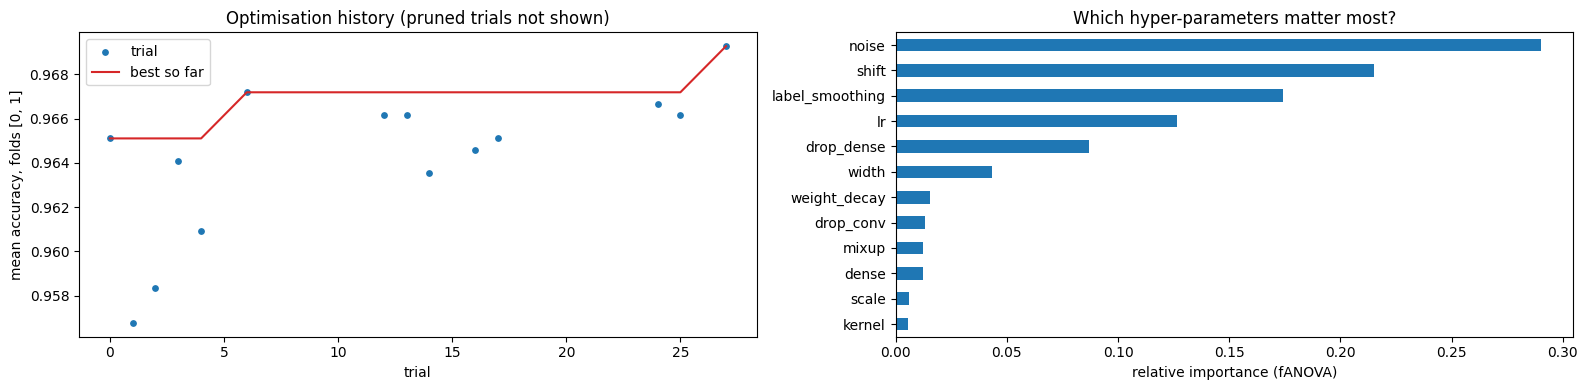

In [ ]:
if RUN_OPTUNA:
    trials = study.trials_dataframe(attrs=('number', 'value', 'state', 'params'))
    trials.columns = [c.replace('params_', '') for c in trials.columns]
    display(trials.sort_values('value', ascending=False).head(10).style.format(precision=4))

    fig, axes = plt.subplots(1, 2, figsize=(16, 4))
    complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    axes[0].scatter([t.number for t in complete], [t.value for t in complete], s=15, label='trial')
    axes[0].plot([t.number for t in complete], np.maximum.accumulate([t.value for t in complete]),
                 color='tab:red', label='best so far')
    axes[0].set_xlabel('trial')
    axes[0].set_ylabel(f'mean accuracy, folds {SEARCH_FOLDS}')
    axes[0].set_title('Optimisation history (pruned trials not shown)')
    axes[0].legend()
    importance = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
    importance.plot.barh(ax=axes[1])
    axes[1].set_xlabel('relative importance (fANOVA)')
    axes[1].set_title('Which hyper-parameters matter most?')
    plt.tight_layout()
    plt.show()

## 9.6 Evaluation of the tuned model

The configuration found by Optuna is trained and evaluated with the usual 5-fold protocol. The table separates the accuracy on the two folds used by the search, which is optimistic for the tuned model, from the accuracy on the three folds that the search never saw, which is the fair comparison between the base model, the best manual configuration and the tuned one.

Then the same views as in the previous sections: sample-by-sample comparison with the base model, learning curves, confusion matrices, accuracy per bit and per interval, and the final table with every model of the notebook.

    trained for 46 epochs |  fold 0: 0.9635
    trained for 25 epochs |  fold 1: 0.9635
    trained for 42 epochs |  fold 2: 0.9677
    trained for 31 epochs |  fold 3: 0.9708
    trained for 33 epochs |  fold 4: 0.9594
CNN1D tuned (Optuna): 0.9650 +/- 0.0039   (195 s)


,mean acc (5 folds),"acc. folds [0, 1] (used by the search)","acc. folds [2, 3, 4] (never used)",050_080,080_110,110_140,parameters
CNN1D base (sec. 9),0.9598,0.9620,0.9583,0.9881,0.9719,0.9194,"1,021,072"
CNN1D + noise + shift + label smoothing,0.9660,0.9677,0.9649,0.9919,0.9794,0.9269,"1,021,072"
CNN1D tuned (Optuna),0.9650,0.9635,0.9660,0.9900,0.9769,0.9281,"1,780,816"


,samples
both correct,4564
only CNN1D base (sec. 9) correct,43
only CNN1D tuned (Optuna) correct,68
both wrong,125


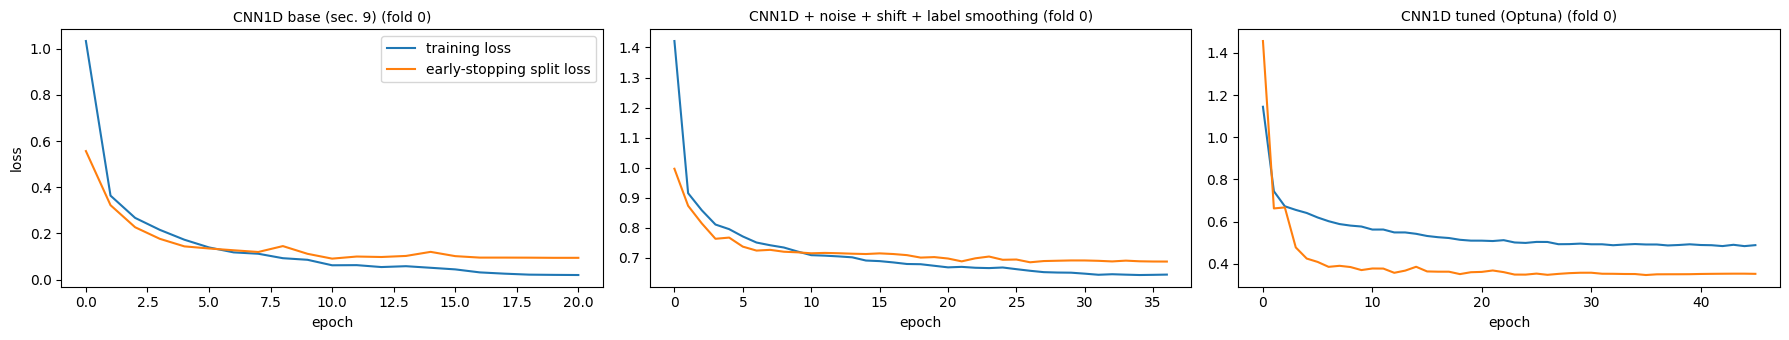

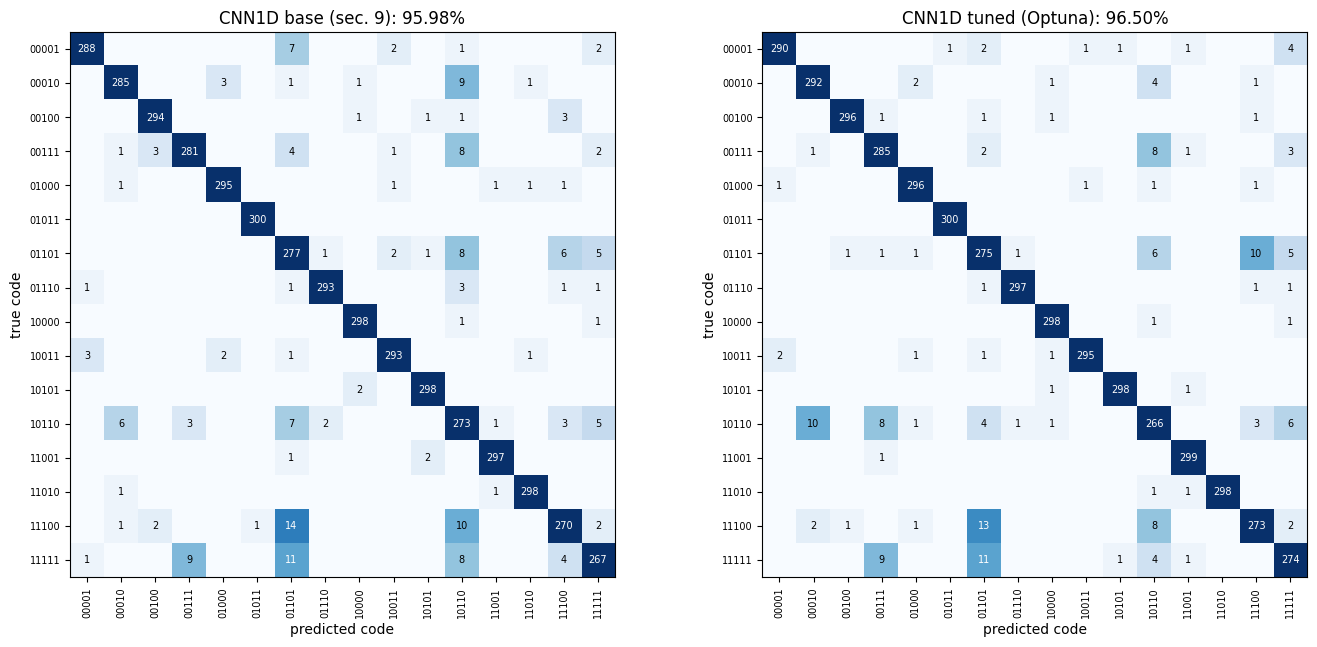

Most frequent confusions of CNN1D tuned (Optuna):


,true,predicted,count,bits that differ
0,11100,01101,13,2
1,11111,01101,11,2
2,10110,00010,10,2
3,01101,11100,10,2
4,11111,00111,9,2
5,10110,00111,8,2
6,00111,10110,8,2
7,11100,10110,8,2


Accuracy of each bit of the predicted class:


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
CNN1D base (sec. 9),0.9731,0.9798,0.9906,0.9812,0.9819
CNN1D + noise + shift + label smoothing,0.9765,0.9842,0.9925,0.9829,0.9840
CNN1D tuned (Optuna),0.9752,0.9842,0.9915,0.9846,0.9842


Accuracy of each bit per distance interval (CNN1D tuned (Optuna)):


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
050_080,0.9950,0.9950,0.9988,0.9944,0.9956
080_110,0.9794,0.9919,0.9919,0.9919,0.9912
110_140,0.9513,0.9656,0.9838,0.9675,0.9656


,mean acc,std acc,050_080,080_110,110_140,time (s),parameters
CNN1D + noise + shift + label smoothing,0.9660,0.0039,0.9919,0.9794,0.9269,196,"1,021,072"
CNN1D tuned (Optuna),0.9650,0.0039,0.9900,0.9769,0.9281,195,"1,780,816"
CNN1D + noise + shift,0.9625,0.0015,0.9888,0.9712,0.9275,156,"1,021,072"
CNN1D + noise + shift + interval,0.9623,0.0029,0.9875,0.9738,0.9256,167,"1,021,456"
CNN1D + noise + shift + weight decay,0.9621,0.0033,0.9919,0.9750,0.9194,159,"1,021,072"
CNN1D + shift,0.9610,0.0034,0.9900,0.9681,0.9250,149,"1,021,072"
CNN1D + noise,0.9604,0.0059,0.9894,0.9688,0.9231,149,"1,021,072"
MLP-A,0.9600,0.0014,0.9862,0.9725,0.9213,102,"3,057,424"
CNN1D base (sec. 9),0.9598,0.0033,0.9881,0.9719,0.9194,125,"1,021,072"
CNN1D-A,0.9596,0.0028,0.9881,0.9725,0.9181,133,"1,021,072"


In [ ]:
TUNED = 'CNN1D tuned (Optuna)'
cross_validate(TUNED, cfg_model(TUNED_CFG, TUNED))

unseen_folds = [k for k in range(N_FOLDS) if k not in SEARCH_FOLDS]
phase5 = list(dict.fromkeys([BASE, MANUAL_BEST, TUNED]))
rows = {}
for n in phase5:
    rows[n] = {'mean acc (5 folds)': RESULTS[n]['mean acc'],
               f'acc. folds {SEARCH_FOLDS} (used by the search)': fold_accuracies(n, SEARCH_FOLDS).mean(),
               f'acc. folds {unseen_folds} (never used)': fold_accuracies(n, unseen_folds).mean(),
               **{itv: RESULTS[n][itv] for itv in INTERVALS},
               'parameters': MODEL_PARAMS[n]}
display(pd.DataFrame(rows).T.style.format(precision=4).format('{:,.0f}', subset=['parameters']))

display(paired_comparison(BASE, TUNED))

fig, axes = plt.subplots(1, len(phase5), figsize=(6 * len(phase5), 3.5), squeeze=False)
for ax, n in zip(axes[0], phase5):
    h = HISTORIES[n][-N_FOLDS]                      # fold 0 of the last run of this model
    ax.plot(h['loss'], label='training loss')
    ax.plot(h['val_loss'], label='early-stopping split loss')
    ax.set_title(f'{n} (fold 0)', fontsize=10)
    ax.set_xlabel('epoch')
axes[0, 0].set_ylabel('loss')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, n in zip(axes, [BASE, TUNED]):
    plot_confusion(n, ax)
plt.tight_layout()
plt.show()

print(f'Most frequent confusions of {TUNED}:')
display(top_confusions(TUNED))
print('Accuracy of each bit of the predicted class:')
display(bit_accuracy(phase5).style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))
print(f'Accuracy of each bit per distance interval ({TUNED}):')
display(bit_accuracy_by_interval(TUNED).style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))

display(full_table())

## 9.7 Conclusions of the improvement step

| Step | Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm | Gain | Kept |
|---|---|---|---|---|---|---|---|
| Base | CNN1D base (sec. 9) | 96.0% +/- 0.3 | 98.8% | 97.2% | 91.9% | - | - |
| 9.2 | + noise | 96.0% +/- 0.6 | 98.9% | 96.9% | 92.3% | +0.06 | yes (3/5 folds) |
| 9.2 | + shift | 96.1% +/- 0.3 | 99.0% | 96.8% | 92.5% | +0.12 | yes (3/5 folds) |
| 9.2 | + scale | 95.9% +/- 0.3 | 98.8% | 97.1% | 91.8% | -0.10 | no |
| 9.2 | + mixup | 96.0% +/- 0.7 | 98.9% | 97.0% | 92.0% | -0.02 | no |
| 9.2 | **+ noise + shift** | **96.3% +/- 0.2** | 98.9% | 97.1% | 92.8% | +0.27 | **yes, best (4/5 folds)** |
| 9.3 | + noise + shift + interval | 96.2% +/- 0.3 | 98.8% | 97.4% | 92.6% | -0.02 | no |
| 9.4 | + noise + shift + weight decay | 96.2% +/- 0.3 | 99.2% | 97.5% | 91.9% | -0.04 | no (2/5 folds) |
| 9.4 | **+ noise + shift + label smoothing** | **96.6% +/- 0.4** | 99.2% | 97.9% | 92.7% | +0.35 | **yes, best (4/5 folds)** |
| 9.5-9.6 | CNN1D tuned (Optuna) | 96.5% +/- 0.4 | 99.0% | 97.7% | 92.8% | - | - |

| Model | Folds 0-1 (used by the search) | Folds 2-4 (never used) | Parameters |
|---|---|---|---|
| CNN1D base (sec. 9) | 96.2% | 95.8% | 1.02 M |
| CNN1D + noise + shift + label smoothing | 96.8% | 96.5% | 1.02 M |
| CNN1D tuned (Optuna) | 96.4% | 96.6% | 1.78 M |

1. **The new pipeline reproduces the previous model.** With the base configuration, the configurable model has exactly the same number of parameters as CNN1D-A and reaches 96.0% (CNN1D-A: 96.0%). Every gain below therefore comes from the change being tested, not from the new training code.
2. **Data augmentation gives very little.** Each technique alone moves the mean by -0.10 to +0.12 points, below the fold-to-fold standard deviation (0.3-0.7). Noise and frequency shift pass the keep rule, only just (3 of 5 folds). Together they reach 96.3% (+0.27, 4 of 5 folds), mostly in the far interval (91.9% to 92.8%), which is the most noisy one. This makes physical sense: these two augmentations imitate the measurement noise and small changes of the resonance frequencies. Scaling and mixup are not kept. Our interpretation of the small effect: with 3,456 training images for 16 classes the network is not short of data, and the 300 real measurements of every tag already contain the variability that augmentation imitates.
3. **The distance interval does not help as an input.** Adding the one-hot interval lowers the mean slightly (-0.02 points) and does not improve the far interval, where we expected the gain (92.8% to 92.6%). The network does not need to be told the distance, because the overall attenuation of the image already carries it (the t-SNE of section 12.4 shows the features are distance-invariant). The final model therefore does not use the interval, which also keeps the test prediction independent of that column.
4. **Label smoothing is the only clear improvement of the section.** Replacing the one-hot targets by 0.906 for the true class and 0.006 for the other 15 raises the accuracy from 96.3% to **96.6%** (+0.35 points, 4 of 5 folds). The gain is largest in the middle interval (97.1% to 97.9%). The learning curves show why. The base model drives its training loss almost to zero (0.02) while the early-stopping loss stays at 0.09: it memorises the training images and becomes over-confident between very similar tags. With label smoothing the two losses stay together (about 0.65 and 0.69) and the gap disappears. Weight decay does not help (-0.04 points, 2 of 5 folds).
5. **Optuna does not beat the manual configuration.** The search hit the 30-minute limit after 28 trials (14 complete, 14 stopped by the pruner after the first fold). Its best trial reached 96.9% on the two search folds, but the same configuration gives 96.4% on those folds when it is re-trained, and 96.5% on the 5 folds. On the three folds the search never saw it is level with the manual best (96.6% vs 96.5%), with 75% more parameters. Most of the 96.9% was luck: with two folds and 28 trials, the search partly selects configurations that happen to fit folds 0 and 1. The tuned model is clearly better than the base model sample by sample (68 samples right only for the tuned model, 43 only for the base model), but not better than the manual best.
6. **What the search says about the hyper-parameters.** The importance plot ranks the noise, the frequency shift, label smoothing and the learning rate first, and the architecture (kernel, dense units, width) last. This agrees with the manual steps: the training recipe matters more than the size of the network. The best trials share a kernel of 9, the largest frequency shift allowed (4 bins), little dropout in the convolutions and dropout around 0.25 in the dense layer. The importances come from only 14 complete trials and should be read as a trend.
7. **The noise floor of the comparisons.** This section was run twice, and the greedy path changed. In the first run mixup was the best augmentation (96.1%) and noise plus shift were not combined; in this run mixup is slightly negative (-0.02) and noise plus shift win. The same configurations moved by up to 0.15 points between the two runs, because training on the GPU is not exactly deterministic. The manual best configuration also gave 96.5% on folds 0 and 1 inside the search and 96.8% in the 5-fold run. Differences of about 0.3 points between two models are therefore not meaningful on their own, and the choice between the augmentations is within that noise. What both runs agree on: **label smoothing is the only clear gain** (+0.35 and +0.50 points), the interval does not help, weight decay does not help and Optuna does not beat the manual configuration.
8. **The errors keep the same structure.** The most frequent confusions are still between 1x1 tags at Hamming distance 2 (11100 and 11111 predicted as 01101, 10110 as 00010). Bit 1 (1.5-2.3 GHz) is still the weakest, especially in the far interval (95.1%).

**Decision:** the final training recipe is the base architecture (kernel 7, dropout 0.2 / 0.4, learning rate 1e-3) with **label smoothing 0.1**, a light augmentation and no interval input. Since the choice of augmentation is within the noise (mixup in the first run, noise and shift in this one), the following sections keep the configuration of the first run, mixup 0.2 + label smoothing 0.1 (`FINAL_CFG`). Re-trained in section 10.1 it reaches 96.65%, the same as noise + shift + label smoothing here (96.60%). Overall, section 9 raises the best single-model accuracy from **96.0% to 96.6%**, almost entirely through label smoothing.

# 10. Other approaches: transformer, transfer learning and pseudo-labelling

Section 9 fixed the training recipe of the final model (CNN1D-A with label smoothing and a light augmentation, 96.6%; mixup 0.2 + label smoothing 0.1, see the decision of 9.7). This section tests three ideas that change something other than the recipe:

| Step | Idea | Question |
|---|---|---|
| 10.2 Transformer | Replace the last convolutional block by self-attention layers | Does relating every frequency position with every other one help to read the 5 notches together? |
| 10.3 Transfer learning | Start from a network pre-trained on ImageNet instead of random weights | Do features learned on natural photographs help on CWT images? |
| 10.4 Pseudo-labelling | Add the confidently predicted test images to the training set | Do the 2,400 unlabelled measurements contain useful information? |

**Protocol.** The same 5 folds and the same keep rule as in section 9 (better mean accuracy **and** better in at least 3 of the 5 folds). Section 9.7 showed that two runs of the same configuration can differ by about 0.3 points, so the reference is not the number of section 9 but the final configuration **re-trained in this section** (10.1), and every model of this section uses the final training recipe (mixup 0.2, label smoothing 0.1, same optimiser and callbacks), so that the only thing that changes is the one being tested.

## 10.1 Shared training function and reference model

`fit_arch(build, cfg, ...)` is the training loop of section 9.1 with the model builder as a parameter, so that any architecture can be trained with the final recipe. `arch_model(build, cfg, name)` plugs it into `cross_validate`. Besides the validation fold, every trained model also predicts:
- the **test set**, normalised with the statistics of its own training fold;
- its **inner early-stopping split**, which is part of the training fold but not used to fit the weights. Its predictions show how reliable the model is at each confidence level without touching the validation fold, and are used to choose the pseudo-labelling threshold in 10.4.

The reference model `CNN1D final (sec. 10)` is the final configuration of section 9 trained with this function. It is also the *teacher* of the pseudo-labelling step.

In [ ]:
FINAL_CFG = {**BASE_CFG, 'mixup': 0.2, 'label_smoothing': 0.1}   # decision of section 9.7
FOLD_OUT = {}   # model name -> fold -> predictions on the early-stopping split and on the test set


def fit_arch(build, cfg, X_fit, Y_fit, X_es, Y_es, mu, sd):
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    I_fit = np.zeros((len(X_fit), N_INTERVALS), dtype=np.float32)   # the interval is not used as input
    ds = (tf.data.Dataset.from_tensor_slices((X_fit, I_fit, Y_fit))
          .shuffle(len(X_fit), seed=SEED)
          .batch(BATCH)
          .map(make_augment(cfg, mu, sd), num_parallel_calls=AUTOTUNE)
          .map(lambda x, i, y: (x, y))
          .prefetch(AUTOTUNE))
    model = build(cfg)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
    ]
    h = model.fit(ds, validation_data=(X_es, Y_es), epochs=EPOCHS, callbacks=callbacks, verbose=0)
    return model, h


def arch_model(build, cfg, name, teacher=None):
    CFGS[name] = dict(cfg)

    def fit_predict(X_tr, y_tr, X_va, tr, va):
        k = fold_id[va[0]]
        mu, sd = fit_feature_stats(X_train_ds[tr])
        X_te = normalize(X_test_ds, 'feature', (mu, sd)).astype(X_tr.dtype)
        fit, es = train_test_split(np.arange(len(tr)), test_size=0.1, stratify=y_tr, random_state=SEED)
        Y_tr = np.eye(N_CLASSES, dtype=np.float32)[y_tr]
        X_fit, Y_fit = X_tr[fit], Y_tr[fit]
        if teacher is not None:
            sel, labels = select_pseudo_labels(teacher, k)
            X_fit = np.concatenate([X_fit, X_te[sel]])
            Y_fit = np.concatenate([Y_fit, np.eye(N_CLASSES, dtype=np.float32)[labels]])
            print(f'    +{len(sel)} pseudo-labelled test images', end=' |')

        model, h = fit_arch(build, cfg, X_fit, Y_fit, X_tr[es], Y_tr[es], mu, sd)
        p, p_es, p_te = (model.predict(x, batch_size=256, verbose=0) for x in (X_va, X_tr[es], X_te))
        MODEL_PARAMS[name] = model.count_params()
        HISTORIES.setdefault(name, []).append(h.history)
        OOF_PROBA.setdefault(name, np.zeros((len(y_train), N_CLASSES), dtype=np.float32))[va] = p
        FOLD_OUT.setdefault(name, {})[k] = {'es_proba': p_es, 'es_true': y_tr[es], 'test_proba': p_te}
        print(f'    trained for {len(h.history["loss"])} epochs', end=' |')
        return p.argmax(axis=1)
    return fit_predict


REF = 'CNN1D final (sec. 10)'
cross_validate(REF, arch_model(build_cnn1d_cfg, FINAL_CFG, REF))

    trained for 29 epochs |  fold 0: 0.9625
    trained for 44 epochs |  fold 1: 0.9708
    trained for 63 epochs |  fold 2: 0.9677
    trained for 31 epochs |  fold 3: 0.9625
    trained for 37 epochs |  fold 4: 0.9688
CNN1D final (sec. 10): 0.9665 +/- 0.0034   (182 s)


{'mean acc': np.float64(0.9664583333333333),
 'std acc': np.float64(0.003385016001931634),
 '050_080': 0.99,
 '080_110': 0.975625,
 '110_140': 0.93375,
 'time (s)': 181.88055396080017}

## 10.2 Transformer

**Idea.** A convolution only looks at a small window of neighbouring frequencies (7 bins per layer). The class, however, is defined by the combination of the 5 notches, which are spread over the whole 1.5-5 GHz band. **Self-attention** lets every frequency position look at every other one in a single layer: each position computes how relevant every other position is for it and takes a weighted mix of their features. A transformer can therefore relate, for example, a weak notch in the first sub-band with the presence or absence of the others.

**Architecture (hybrid CNN + transformer).** Pure transformers need far more than 3,456 training images to learn good low-level features, so the first two convolutional blocks of CNN1D-A are kept: they turn the 400 x 57 image into a sequence of 100 *tokens* (one every 4 frequency bins, 35 MHz) of 128 features. The third convolutional block is replaced by 2 **transformer encoder layers**:
- a learned **position embedding** is added to the tokens, because attention by itself ignores the order of the tokens, and here the position (frequency) is exactly what defines each bit;
- each layer applies multi-head self-attention (4 heads) and a small feed-forward network, both with layer normalisation and residual connections.

The head is the same as in CNN1D-A (pooling to 50 positions, flatten, dense layer of 128, softmax), so the comparison with the reference isolates the change convolution vs attention in the last block.

In [ ]:
class PositionEmbedding(layers.Layer):
    def build(self, input_shape):
        self.pos = self.add_weight(name='pos', shape=tuple(input_shape[1:]),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02))

    def call(self, x):
        return x + self.pos


def transformer_block(x, cfg):
    d = x.shape[-1]
    a = layers.LayerNormalization()(x)
    a = layers.MultiHeadAttention(num_heads=cfg['heads'], key_dim=d // cfg['heads'], dropout=cfg['drop_attn'])(a, a)
    x = x + layers.Dropout(cfg['drop_attn'])(a)
    f = layers.LayerNormalization()(x)
    f = layers.Dense(2 * d, activation='gelu')(f)
    f = layers.Dense(d)(layers.Dropout(cfg['drop_attn'])(f))
    return x + layers.Dropout(cfg['drop_attn'])(f)


def build_transformer(cfg):
    inp = keras.Input(shape=INPUT_SHAPE)
    x = inp
    for filters in [64, 128]:
        x = layers.Conv1D(filters, kernel_size=cfg['kernel'], padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling1D(pool_size=2)(x)
        x = layers.Dropout(cfg['drop_conv'])(x)
    x = PositionEmbedding()(x)
    for _ in range(cfg['n_layers']):
        x = transformer_block(x, cfg)
    x = layers.LayerNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(cfg['dense'])(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(cfg['drop_dense'])(x)
    out = layers.Dense(N_CLASSES, activation='softmax')(x)
    model = keras.Model(inp, out, name='cnn_transformer')
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=cfg['lr'], weight_decay=cfg['weight_decay']),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=cfg['label_smoothing']),
                  metrics=['accuracy'])
    return model


TRANSFORMER_CFG = {**FINAL_CFG, 'n_layers': 2, 'heads': 4, 'drop_attn': 0.1}
print(f'{build_transformer(TRANSFORMER_CFG).count_params():,} parameters')

TRANSFORMER = 'CNN1D + transformer'
cross_validate(TRANSFORMER, arch_model(build_transformer, TRANSFORMER_CFG, TRANSFORMER))
display(change_table([TRANSFORMER], REF))

1,183,760 parameters
    trained for 49 epochs |  fold 0: 0.9615
    trained for 42 epochs |  fold 1: 0.9604
    trained for 36 epochs |  fold 2: 0.9625
    trained for 40 epochs |  fold 3: 0.9542
    trained for 44 epochs |  fold 4: 0.9656
CNN1D + transformer: 0.9608 +/- 0.0038   (352 s)


,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D final (sec. 10),0.9665,0.0034,0.9900,0.9756,0.9337,+0.00,0,-
CNN1D + transformer,0.9608,0.0038,0.9900,0.9738,0.9187,-0.56,0,no


## 10.3 Transfer learning from ImageNet

**Idea.** Instead of starting from random weights, start from a network already trained on ImageNet (1.3 million natural photographs, 1,000 classes) and **fine-tune** all its weights on our images. Its first layers have learned generic detectors of edges, blobs and textures, which could help to find the notches with few training images.

**Network: EfficientNetV2-B0** (Keras applications), a modern and light ImageNet network (about 6 million parameters, the smallest of the EfficientNetV2 family). Its classification layer is replaced by global average pooling, dropout and our 16-class softmax.

**Adapting the input.**
- ImageNet networks expect colour images, so the 400 x 57 CWT image is repeated in the 3 channels.
- The network is built with `include_preprocessing=False`, so it takes our normalised images directly (it would otherwise rescale pixel values from the 0-255 range).
- The image is not resized: the network is fully convolutional and accepts 400 x 57 inputs. After its 5 stride-2 stages the frequency axis is reduced to 13 positions, coarser than in CNN1D-A (50), which is one of the risks of this approach.

**Control experiment.** Any difference with the reference could come from the pre-trained weights or simply from the different (and much deeper) architecture. The same network is therefore also trained **from random weights**: the difference between the two runs is the effect of the ImageNet pre-training alone.

Both runs use the final recipe with a lower learning rate (5e-4), the usual choice when fine-tuning pre-trained weights so that the first updates do not destroy them. They are the slowest models of the notebook (several minutes per fold on the GPU).

In [ ]:
def build_effnet(cfg):
    inp = keras.Input(shape=INPUT_SHAPE)
    x = layers.Reshape((*INPUT_SHAPE, 1))(inp)
    x = layers.Concatenate()([x, x, x])                  # the same image in the 3 colour channels
    backbone = keras.applications.EfficientNetV2B0(include_top=False, weights=cfg['weights'],
                                                   input_shape=(*INPUT_SHAPE, 3), include_preprocessing=False)
    x = backbone(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(cfg['drop_dense'])(x)
    out = layers.Dense(N_CLASSES, activation='softmax')(x)
    model = keras.Model(inp, out, name='effnetv2b0')
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=cfg['lr'], weight_decay=cfg['weight_decay']),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=cfg['label_smoothing']),
                  metrics=['accuracy'])
    return model


TRANSFER_CFG = {**FINAL_CFG, 'lr': 5e-4, 'weights': 'imagenet'}
PRETRAINED = 'EfficientNetV2-B0 (ImageNet)'
SCRATCH = 'EfficientNetV2-B0 (random init.)'
cross_validate(PRETRAINED, arch_model(build_effnet, TRANSFER_CFG, PRETRAINED))
cross_validate(SCRATCH, arch_model(build_effnet, {**TRANSFER_CFG, 'weights': None}, SCRATCH))

display(change_table([PRETRAINED, SCRATCH], REF))
display(paired_comparison(SCRATCH, PRETRAINED))

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
    trained for 48 epochs |  fold 0: 0.9635
    trained for 31 epochs |  fold 1: 0.9625
    trained for 44 epochs |  fold 2: 0.9719
    trained for 37 epochs |  fold 3: 0.9625
    trained for 56 epochs |  fold 4: 0.9698
EfficientNetV2-B0 (ImageNet): 0.9660 +/- 0.0040   (1067 s)
    trained for 48 epochs |  fold 0: 0.9635
    trained for 61 epochs |  fold 1: 0.9677
    trained for 54 epochs |  fold 2: 0.9542
    trained for 65 epochs |  fold 3: 0.9594
    trained for 65 epochs |  fold 4: 0.9667
EfficientNetV2-B0 (random init.): 0.9623 +/- 0.0050   (1151 s)


,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D final (sec. 10),0.9665,0.0034,0.9900,0.9756,0.9337,+0.00,0,-
EfficientNetV2-B0 (ImageNet),0.9660,0.0040,0.9875,0.9812,0.9294,-0.04,3,no
EfficientNetV2-B0 (random init.),0.9623,0.0050,0.9856,0.9756,0.9256,-0.42,1,no


,samples
both correct,4551
only EfficientNetV2-B0 (random init.) correct,68
only EfficientNetV2-B0 (ImageNet) correct,86
both wrong,95


## 10.4 Pseudo-labelling with the test set

**Idea.** The 2,400 test images have no labels, but the model already classifies most of them correctly. **Pseudo-labelling** (a form of semi-supervised learning) adds the test images that the model predicts with high confidence to the training set, labelled with its prediction, and re-trains. If the pseudo-labels are almost always right, the model sees 40-60% more real measurements, including the test conditions themselves. Only the test **images** are used, never test labels (which we do not have), so this is a legitimate use of the unlabelled data.

**Avoiding leakage in the evaluation.** For fold *k*, the pseudo-labels are produced by the reference model of fold *k* (10.1), which never saw the validation fold *k*. The student of fold *k* is then trained on the training part of fold *k* plus the selected test images, and evaluated on validation fold *k*. No validation information reaches the student at any point.

**Choosing the confidence threshold.** A wrong pseudo-label teaches the model a wrong answer, so only predictions that are very likely correct are kept. Because of label smoothing, the highest probability the model gives is about 0.9, so a fixed threshold such as 0.99 would select nothing. Instead, the threshold is chosen on the teacher's **inner early-stopping split** (labelled data of the training fold, not used to fit its weights): it is the lowest confidence at which the predictions above it are still at least **99% correct** on that split. The test images above that threshold are kept.

The student uses exactly the same architecture and recipe as the teacher, so the comparison with the reference measures only the effect of the extra data.

In [ ]:
PL_PRECISION = 0.99


def confidence_threshold(conf, correct, target=PL_PRECISION):
    order = np.argsort(-conf)
    precision = np.cumsum(correct[order]) / np.arange(1, len(conf) + 1)   # accuracy of the top-n most confident
    ok = np.where(precision >= target)[0]
    return conf[order][ok.max()] if len(ok) else 1.0


def select_pseudo_labels(teacher, k):
    out = FOLD_OUT[teacher][k]
    es_conf = out['es_proba'].max(axis=1)
    threshold = confidence_threshold(es_conf, out['es_proba'].argmax(axis=1) == out['es_true'])
    test_conf = out['test_proba'].max(axis=1)
    sel = np.where(test_conf >= threshold)[0]
    labels = out['test_proba'][sel].argmax(axis=1)
    counts = np.bincount(labels, minlength=N_CLASSES)
    PSEUDO_LOG[k] = {'threshold': threshold,
                     'early-stopping split above threshold': (es_conf >= threshold).mean(),
                     'test images selected': len(sel),
                     **{f'selected {itv}': (test_conf[int_test_idx == j] >= threshold).mean()
                        for j, itv in enumerate(INTERVALS)},
                     'fewest / most per class': f'{counts.min()} / {counts.max()}'}
    return sel, labels


PSEUDO_LOG = {}
PSEUDO = 'CNN1D final + pseudo-labels'
cross_validate(PSEUDO, arch_model(build_cnn1d_cfg, FINAL_CFG, PSEUDO, teacher=REF))

print('Pseudo-label selection per fold:')
display(pd.DataFrame(PSEUDO_LOG).T.style.format(precision=3))
display(change_table([PSEUDO], REF))
display(paired_comparison(REF, PSEUDO))

    +1993 pseudo-labelled test images |    trained for 32 epochs |  fold 0: 0.9625
    +2131 pseudo-labelled test images |    trained for 44 epochs |  fold 1: 0.9583
    +2114 pseudo-labelled test images |    trained for 35 epochs |  fold 2: 0.9635
    +2176 pseudo-labelled test images |    trained for 41 epochs |  fold 3: 0.9594
    +2118 pseudo-labelled test images |    trained for 43 epochs |  fold 4: 0.9635
CNN1D final + pseudo-labels: 0.9615 +/- 0.0022   (280 s)
Pseudo-label selection per fold:


,threshold,early-stopping split above threshold,test images selected,selected 050_080,selected 080_110,selected 110_140,fewest / most per class
0,0.587,0.914,1993,0.895,0.864,0.733,64 / 148
1,0.432,0.943,2131,0.926,0.909,0.829,60 / 163
2,0.480,0.940,2114,0.930,0.910,0.802,64 / 149
3,0.448,0.948,2176,0.940,0.935,0.845,86 / 157
4,0.473,0.956,2118,0.943,0.905,0.800,89 / 153


,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D final (sec. 10),0.9665,0.0034,0.9900,0.9756,0.9337,+0.00,0,-
CNN1D final + pseudo-labels,0.9615,0.0022,0.9869,0.9738,0.9237,-0.50,0,no


,samples
both correct,4586
only CNN1D final (sec. 10) correct,53
only CNN1D final + pseudo-labels correct,29
both wrong,132


## 10.5 Summary of the section

All the models of this section against the reference re-trained in 10.1, with the accuracy per bit and the final table with every model of the notebook.

In [ ]:
SEC10 = [REF, TRANSFORMER, PRETRAINED, SCRATCH, PSEUDO]
display(change_table(SEC10[1:], REF))
print('Accuracy of each bit of the predicted class:')
display(bit_accuracy(SEC10).style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))
display(full_table())

,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D final (sec. 10),0.9665,0.0034,0.9900,0.9756,0.9337,+0.00,0,-
CNN1D + transformer,0.9608,0.0038,0.9900,0.9738,0.9187,-0.56,0,no
EfficientNetV2-B0 (ImageNet),0.9660,0.0040,0.9875,0.9812,0.9294,-0.04,3,no
EfficientNetV2-B0 (random init.),0.9623,0.0050,0.9856,0.9756,0.9256,-0.42,1,no
CNN1D final + pseudo-labels,0.9615,0.0022,0.9869,0.9738,0.9237,-0.50,0,no


Accuracy of each bit of the predicted class:


,bit 1 (1.5-2.3 GHz),bit 2 (2.3-2.8 GHz),bit 3 (2.8-3.4 GHz),bit 4 (3.4-4.2 GHz),bit 5 (4.2-5.0 GHz)
CNN1D final (sec. 10),0.9777,0.9844,0.9900,0.9854,0.9854
CNN1D + transformer,0.9750,0.9808,0.9888,0.9821,0.9817
EfficientNetV2-B0 (ImageNet),0.9783,0.9833,0.9921,0.9833,0.9858
EfficientNetV2-B0 (random init.),0.9769,0.9788,0.9890,0.9810,0.9856
CNN1D final + pseudo-labels,0.9738,0.9812,0.9894,0.9815,0.9829


,mean acc,std acc,050_080,080_110,110_140,time (s),parameters
CNN1D final (sec. 10),0.9665,0.0034,0.9900,0.9756,0.9337,182,"1,021,072"
EfficientNetV2-B0 (ImageNet),0.9660,0.0040,0.9875,0.9812,0.9294,1067,"5,939,808"
CNN1D + noise + shift + label smoothing,0.9660,0.0039,0.9919,0.9794,0.9269,196,"1,021,072"
CNN1D tuned (Optuna),0.9650,0.0039,0.9900,0.9769,0.9281,195,"1,780,816"
CNN1D + noise + shift,0.9625,0.0015,0.9888,0.9712,0.9275,156,"1,021,072"
EfficientNetV2-B0 (random init.),0.9623,0.0050,0.9856,0.9756,0.9256,1151,"5,939,808"
CNN1D + noise + shift + interval,0.9623,0.0029,0.9875,0.9738,0.9256,167,"1,021,456"
CNN1D + noise + shift + weight decay,0.9621,0.0033,0.9919,0.9750,0.9194,159,"1,021,072"
CNN1D final + pseudo-labels,0.9615,0.0022,0.9869,0.9738,0.9237,280,"1,021,072"
CNN1D + shift,0.9610,0.0034,0.9900,0.9681,0.9250,149,"1,021,072"


## 10.6 Conclusions of the section

| Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm | Gain vs reference | Folds improved | Parameters | Time |
|---|---|---|---|---|---|---|---|---|
| **CNN1D final (reference)** | **96.6% +/- 0.3** | 99.0% | 97.6% | 93.4% | - | - | 1.0 M | 3 min |
| EfficientNetV2-B0 (ImageNet) | 96.6% +/- 0.4 | 98.8% | 98.1% | 92.9% | -0.04 | 3/5 | 5.9 M | 18 min |
| EfficientNetV2-B0 (random init.) | 96.2% +/- 0.5 | 98.6% | 97.6% | 92.6% | -0.42 | 1/5 | 5.9 M | 19 min |
| CNN1D final + pseudo-labels | 96.2% +/- 0.2 | 98.7% | 97.4% | 92.4% | -0.50 | 0/5 | 1.0 M | 5 min |
| CNN1D + transformer | 96.1% +/- 0.4 | 99.0% | 97.4% | 91.9% | -0.56 | 0/5 | 1.2 M | 6 min |

1. **The reference reproduces the result of section 9** (96.6%), so the final recipe is stable from one run to another.
2. **Self-attention does not help.** Replacing the last convolutional block by two transformer layers lowers the accuracy in all 5 folds (-0.56 points), and the loss is concentrated in the far interval (93.4% to 91.9%). The global view that attention provides is not missing in the CNN: its flatten + dense layer already combines all the frequency positions, so the 5 notches are already read together. Attention adds parameters that are harder to train with 3,456 images and seems to fit the noise of the far measurements.
3. **ImageNet pre-training does help a large 2D network, but it only brings it level with the 1D CNN.** The two EfficientNets differ only in their initial weights, and the pre-trained one is better by 0.37 points (86 samples right only for the pre-trained network vs 68 only for the random one). Images of cats and cars have nothing to do with a CWT, but the first layers of an ImageNet network detect generic patterns (edges, dips and changes of intensity) and a notch is one of them, so the pre-trained weights are a better starting point than random ones. Even so, the result ties with the CNN1D (-0.04 points) with 6 times more parameters and 6 times more training time: the 1D design, which matches the structure of the data (section 7), is worth as much as the pre-training. The two networks fail on partly different samples (the EfficientNet is better at 80-110 cm and worse at 110-140 cm), which makes them good candidates for an ensemble (section 11).
4. **Pseudo-labelling makes the model worse** (-0.50 points, 0 of 5 folds). The threshold chosen on the early-stopping split (0.43-0.59) selects 83-91% of the test images, about 2,100 per fold, so the training set grows by 60%. However, the selected images are exactly the ones the teacher already classifies easily (the far interval is under-represented: 73-85% selected vs 90-94% at 50-80 cm). The student therefore receives many easy examples and few of the difficult ones it needs, plus the errors of the teacher (1% by construction, about 20 wrong labels per fold), which it learns as if they were true. The test set does not contain conditions that the training set lacks (section 3.3), so the extra images add little new information.
5. **None of the changes of this section is kept.** The final single model is still the CNN1D with the final recipe. The only useful result is the complementarity of the EfficientNet, which is exploited in section 11.

# 11. Final model and test prediction

Sections 9 and 10 left several models within 0.1 points of each other at the top of the table (CNN1D final 96.6%, EfficientNetV2-B0 pre-trained on ImageNet 96.6%, CNN1D tuned by Optuna 96.5%), a difference smaller than the noise between two runs of the same model (about 0.3 points, section 9.7). Choosing one of them would be arbitrary. However, the CNN1D and the EfficientNet are very different networks (1D vs 2D convolutions, 1 M vs 6 M parameters, random vs pre-trained initialisation) and section 10 showed that they fail on partly different samples. This is the situation in which an **ensemble** (averaging the predicted probabilities of several models) helps: where one model is wrong with low confidence, the other can correct it.

## 11.1 Choosing the final model: ensembles evaluated with cross-validation

Every model stores its out-of-fold probabilities (`OOF_PROBA`), all computed with the same 5 folds. The average of the out-of-fold probabilities of several models is therefore the out-of-fold prediction of their ensemble, and its accuracy is a valid cross-validation estimate **without training anything new**.

Three ensembles of the models of section 10 are compared with the single CNN1D (the members are fixed in advance, from the most to the least accurate, to limit the optimism of choosing among many combinations):

| Ensemble | Members |
|---|---|
| 2 models | CNN1D final + EfficientNet (ImageNet) |
| 3 models | + EfficientNet (random initialisation) |
| 4 models | + CNN1D with transformer |

Only models of section 10 can be members, because they are the only ones that also kept their predictions on the test set (`FOLD_OUT`). Pseudo-labelling is left out (it was worse than its teacher). The ensemble replaces the single model only if it satisfies the same keep rule as every previous change.

In [ ]:
ENSEMBLES = {}   # ensemble name -> member models


def register_ensemble(name, members):
    proba = np.mean([OOF_PROBA[m] for m in members], axis=0)
    pred = proba.argmax(axis=1)
    fold_acc = [accuracy_score(y_train[fold_id == k], pred[fold_id == k]) for k in range(N_FOLDS)]
    RESULTS[name] = {'mean acc': np.mean(fold_acc), 'std acc': np.std(fold_acc),
                     **{itv: accuracy_score(y_train[int_train_idx == j], pred[int_train_idx == j])
                        for j, itv in enumerate(INTERVALS)},
                     'time (s)': sum(RESULTS[m]['time (s)'] for m in members)}
    OOF_PRED[name], OOF_PROBA[name] = pred, proba
    MODEL_PARAMS[name] = sum(MODEL_PARAMS[m] for m in members)
    ENSEMBLES[name] = members


register_ensemble('Ensemble (2): CNN1D + EfficientNet', [REF, PRETRAINED])
register_ensemble('Ensemble (3): + EfficientNet random init.', [REF, PRETRAINED, SCRATCH])
register_ensemble('Ensemble (4): + transformer', [REF, PRETRAINED, SCRATCH, TRANSFORMER])

display(paired_comparison(REF, PRETRAINED))
display(change_table(list(ENSEMBLES), REF))

FINAL = best_of(list(ENSEMBLES), REF)
FINAL_MEMBERS = ENSEMBLES.get(FINAL, [REF])
print(f'Final model: {FINAL}  ->  members: {FINAL_MEMBERS}')

,samples
both correct,4565
only CNN1D final (sec. 10) correct,74
only EfficientNetV2-B0 (ImageNet) correct,72
both wrong,89


,mean acc,std acc,050_080,080_110,110_140,gain (points),folds improved,kept
CNN1D final (sec. 10),0.9665,0.0034,0.9900,0.9756,0.9337,+0.00,0,-
Ensemble (2): CNN1D + EfficientNet,0.9702,0.0054,0.9900,0.9800,0.9406,+0.37,4,yes
Ensemble (3): + EfficientNet random init.,0.9727,0.0033,0.9906,0.9831,0.9444,+0.63,4,yes
Ensemble (4): + transformer,0.9735,0.0025,0.9931,0.9819,0.9456,+0.71,5,yes


Final model: Ensemble (4): + transformer  ->  members: ['CNN1D final (sec. 10)', 'EfficientNetV2-B0 (ImageNet)', 'EfficientNetV2-B0 (random init.)', 'CNN1D + transformer']


## 11.2 Prediction of the test set

Every member was trained 5 times, once per fold, and each of those 5 models already predicted the whole test set (section 10). The test probabilities of a member are the **average of its 5 fold models**, and the final probabilities are the average over the members. Averaging the fold models is itself a small ensemble: each one was trained on a different 80% of the data, and together they use all the training samples. Because of this, the cross-validation accuracy of 11.1, which corresponds to single fold models, is a slightly conservative estimate of the accuracy on the test set.

**Test-time augmentation (TTA)**, averaging the predictions on several augmented copies of each test image, was not used: it needs the trained models in memory (only their predictions were kept), and section 9.2 showed that the augmentations themselves barely change the predictions of the model.

The labels are written to `test_predictions.txt`, one per line, in the original order of the test file and in the same format as the training labels (for example `tag_01101_1x1`). The probabilities are also saved (`test_proba_final.npy`) so that the analysis can be repeated without re-training.

In [ ]:
def test_proba_of(name):
    return np.mean([FOLD_OUT[name][k]['test_proba'] for k in range(N_FOLDS)], axis=0)


MEMBER_TEST = {m: test_proba_of(m) for m in FINAL_MEMBERS}
TEST_PROBA = np.mean(list(MEMBER_TEST.values()), axis=0)
TEST_PRED = TEST_PROBA.argmax(axis=1)
TEST_LABELS = CLASS_NAMES[TEST_PRED]
assert len(TEST_LABELS) == len(X_test)

PRED_FILE = path_files + 'test_predictions.txt'
with open(PRED_FILE, 'w') as f:
    f.write('\n'.join(TEST_LABELS) + '\n')
np.save(path_files + 'test_proba_final.npy', TEST_PROBA)

with open(PRED_FILE) as f:
    written = f.read().splitlines()
assert written == list(TEST_LABELS)
print(f'{len(written)} labels written to {PRED_FILE}. First lines: {written[:3]}')

2400 labels written to /content/drive/MyDrive/TECNUN 2026-27/DeepLearning_1cuatri/Deep_Learning_Final_proyect/test_predictions.txt. First lines: ['tag_00001_4x4', 'tag_10000_4x4', 'tag_00100_4x4']


## 11.3 Sanity checks of the test predictions

The test labels are unknown, so the predictions cannot be scored, but several checks can reveal a problem:
- **Class balance.** The training set has exactly 300 samples per class and 100 per (class, interval). If the test set was recorded in the same way, every class should appear about 150 times (2,400 / 16). A class predicted far more often than the others would point to a systematic confusion.
- **Agreement between models.** The fraction of test images on which all the fold models of all the members agree. Disagreement marks the doubtful images.
- **Confidence on test vs validation.** If the test images were different from the training ones (another environment, another antenna), the model would be less confident on them. Similar confidence distributions support that the cross-validation accuracy is a fair estimate of the test accuracy.
- **Expected test accuracy.** The validation samples tell how often the model is right at each confidence level. Applying those rates to the confidence of the test predictions gives an estimate of the test accuracy that takes the test conditions into account, per interval too.

col_0,050_080,080_110,110_140,total
predicted code,,,,
00001,48,50,57,155
00010,49,51,50,150
00100,52,54,60,166
00111,50,55,64,169
01000,50,50,48,148
01011,49,50,49,148
01101,51,51,44,146
01110,53,50,49,152
10000,50,50,51,151


Expected if balanced: 150 per class, 50 per (class, interval)

Test images on which all 20 fold models agree: 83.2%
    050_080: 90.8%
    080_110: 86.8%
    110_140: 72.2%


,CV accuracy,expected test accuracy
all,0.9735,0.9505
050_080,0.9931,0.9676
080_110,0.9819,0.9614
110_140,0.9456,0.9225


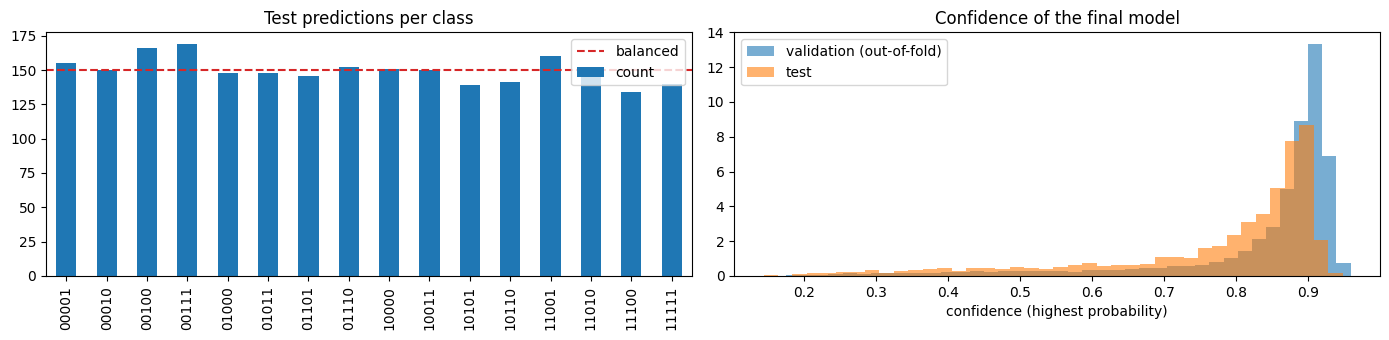

In [ ]:
pred_table = pd.crosstab(pd.Series(CODES, dtype=object)[TEST_PRED].values, int_test, margins=True, margins_name='total')
pred_table.index.name = 'predicted code'
display(pred_table.style.background_gradient(cmap='RdYlGn_r', subset=(pred_table.index[:-1], pred_table.columns[:-1])))
print(f'Expected if balanced: {len(X_test) / N_CLASSES:.0f} per class, '
      f'{len(X_test) / N_CLASSES / N_INTERVALS:.0f} per (class, interval)')

fold_votes = np.stack([FOLD_OUT[m][k]['test_proba'].argmax(axis=1) for m in FINAL_MEMBERS for k in range(N_FOLDS)])
unanimous = (fold_votes == fold_votes[0]).all(axis=0)
print(f'\nTest images on which all {len(fold_votes)} fold models agree: {unanimous.mean():.1%}')
for j, itv in enumerate(INTERVALS):
    print(f'    {itv}: {unanimous[int_test_idx == j].mean():.1%}')

val_conf, val_ok = OOF_PROBA[FINAL].max(axis=1), OOF_PRED[FINAL] == y_train
test_conf = TEST_PROBA.max(axis=1)
bins = np.quantile(val_conf, np.linspace(0, 1, 11))
bins[0], bins[-1] = 0, 1
val_bin = np.clip(np.digitize(val_conf, bins) - 1, 0, 9)
test_bin = np.clip(np.digitize(test_conf, bins) - 1, 0, 9)
acc_per_bin = np.array([val_ok[val_bin == b].mean() for b in range(10)])

rows = {'all': {'CV accuracy': val_ok.mean(), 'expected test accuracy': acc_per_bin[test_bin].mean()}}
for j, itv in enumerate(INTERVALS):
    rows[itv] = {'CV accuracy': val_ok[int_train_idx == j].mean(),
                 'expected test accuracy': acc_per_bin[test_bin[int_test_idx == j]].mean()}
display(pd.DataFrame(rows).T.style.format('{:.4f}'))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
pd.Series(TEST_PRED).value_counts().reindex(range(N_CLASSES), fill_value=0).set_axis(CODES).plot.bar(ax=axes[0])
axes[0].axhline(len(X_test) / N_CLASSES, color='tab:red', ls='--', label='balanced')
axes[0].set_title('Test predictions per class')
axes[0].legend()
axes[1].hist(val_conf, bins=40, density=True, alpha=0.6, label='validation (out-of-fold)')
axes[1].hist(test_conf, bins=40, density=True, alpha=0.6, label='test')
axes[1].set_xlabel('confidence (highest probability)')
axes[1].set_title('Confidence of the final model')
axes[1].legend()
plt.tight_layout()
plt.show()

## 11.4 Conclusions: final model and test prediction

| Model | Mean acc (5-fold) | 50-80 cm | 80-110 cm | 110-140 cm | Gain | Folds improved | Errors |
|---|---|---|---|---|---|---|---|
| CNN1D final (single model) | 96.6% +/- 0.3 | 99.0% | 97.6% | 93.4% | - | - | 161 |
| Ensemble (2): CNN1D + EfficientNet (ImageNet) | 97.0% +/- 0.5 | 99.0% | 98.0% | 94.1% | +0.37 | 4/5 | |
| Ensemble (3): + EfficientNet (random init.) | 97.3% +/- 0.3 | 99.1% | 98.3% | 94.4% | +0.63 | 4/5 | |
| **Ensemble (4): + CNN1D with transformer** | **97.4% +/- 0.3** | **99.3%** | **98.2%** | **94.6%** | **+0.71** | **5/5** | **127** |

1. **The ensemble is the largest improvement since section 6.** Averaging the four models raises the accuracy from 96.6% to 97.4% and improves all 5 folds. It is the only change of the notebook that is clearly larger than the run-to-run noise (0.3 points). The number of errors goes from 194 (CNN1D-A, section 6) and 161 (CNN1D final) to 127. The gain is largest in the far interval (93.4% to 94.6%).
2. **Weaker models make the ensemble better.** On their own, the random-initialised EfficientNet (96.2%) and the transformer (96.1%) are worse than the CNN1D, yet each one improves the ensemble. What matters is that the members fail on different samples. The CNN1D and the pre-trained EfficientNet are each right on about 70 samples that the other gets wrong, and only 89 are wrong for both. When the members disagree, the average of their probabilities usually picks the right class.
3. **Possible optimism.** The ensemble was chosen among three candidates on the same out-of-fold predictions, so its 97.4% is slightly optimistic. The three candidates were nested and fixed in advance, and the best one improves every fold, so the bias is small. Furthermore, the test prediction averages the 5 fold models of each member (20 models), which should be at least as good as the single fold models evaluated here.
4. **The test predictions are consistent.** Each interval has exactly 800 predictions, and each class between 134 and 169 (150 expected if the test set is balanced like the training set). The deviations sit where the cross-validation errors are. In the far interval, 11100 and 11111 are predicted less often than expected (39 and 38 of 50) and 00111 and 00100 more often (64 and 60), the same 1x1 confusions seen in the confusion matrix.
5. **The test set looks slightly harder than the validation folds.** All 20 models agree on 83% of the test images (91% / 87% / 72% per interval), and the confidence on the test set is somewhat lower than on validation. Applying the validation accuracy at each confidence level to the test confidences gives an expected test accuracy of about **95%** (96.8% / 96.1% / 92.3% per interval). This estimate is pessimistic: the test probabilities average 20 models while the validation probabilities average 4, and averaging more models lowers the highest probability even when they agree on the class. Our estimate of the test accuracy is therefore between 95% and 97%, with most errors in the far interval.

**Decision:** the final model is **Ensemble (4)**: CNN1D final, EfficientNetV2-B0 pre-trained on ImageNet, EfficientNetV2-B0 from random weights and CNN1D with transformer, each represented by its 5 fold models. Its predictions are saved in `test_predictions.txt`.

# 12. Analysis and interpretation of the final model

Accuracy alone does not say whether the model has learned the physics of the problem or a shortcut. This section looks at **which errors** the final model makes, **how reliable** its confidence is, **where** in the spectrum it looks, and **how** it organises the 16 tags internally.

## 12.1 Where the errors are: classes, tag size and distance

The confusion matrix and the most frequent confusions of the final model, and its accuracy per **tag size** (1x1 to 4x4, from the name of the tag) and distance interval. Section 6.7 found that most errors involve 1x1 tags; this table checks whether that is still true for the final model and how it depends on the distance.

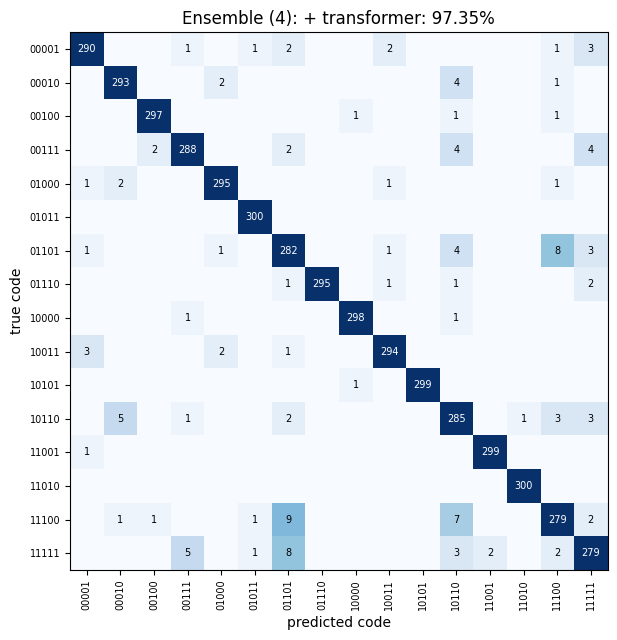

Most frequent confusions of Ensemble (4): + transformer:


,true,predicted,count,bits that differ
0,11100,01101,9,2
1,11111,01101,8,2
2,01101,11100,8,2
3,11100,10110,7,2
4,10110,00010,5,2
5,11111,00111,5,2
6,01101,10110,4,4
7,00111,10110,4,2


,errors,2 bits apart (%),4 bits apart (%)
CNN1D-A,194,84.0,16.0
CNN1D final (sec. 10),161,85.1,14.9
Ensemble (4): + transformer,127,84.3,15.7


Accuracy per tag size and distance interval:


col_0,050_080,080_110,110_140,all
tag size,,,,
1x1,0.9825,0.9450,0.8850,0.9375
2x2,0.9960,0.9880,0.9540,0.9793
3x3,0.9950,1.0000,0.9800,0.9917
4x4,0.9980,0.9980,0.9720,0.9893
all,0.9931,0.9819,0.9456,0.9735


Number of tags of each size: {np.str_('1x1'): np.int64(4), np.str_('2x2'): np.int64(5), np.str_('3x3'): np.int64(2), np.str_('4x4'): np.int64(5)}


In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
plot_confusion(FINAL, ax)
plt.tight_layout()
plt.show()

print(f'Most frequent confusions of {FINAL}:')
display(top_confusions(FINAL))
display(errors_by_distance(['CNN1D-A', REF, FINAL] if 'CNN1D-A' in OOF_PRED else [REF, FINAL])
        .style.format({'errors': '{:.0f}', '2 bits apart (%)': '{:.1f}', '4 bits apart (%)': '{:.1f}'}))

SIZES = np.array([c.split('_')[-1] for c in CLASS_NAMES])
ok = (OOF_PRED[FINAL] == y_train).astype(float)
size_table = pd.crosstab(SIZES[y_train], int_train, values=ok, aggfunc='mean', margins=True, margins_name='all')
size_table.index.name = 'tag size'
print('Accuracy per tag size and distance interval:')
display(size_table.style.format('{:.4f}').background_gradient(cmap='Greens', axis=None))
print('Number of tags of each size:', dict(zip(*np.unique(SIZES, return_counts=True))))

## 12.2 Calibration: can the confidence be trusted?

A model is **calibrated** if, among the predictions made with confidence 0.8, about 80% are correct. This matters in practice: a calibrated confidence can be used to flag the doubtful readings for a second measurement.

The **reliability diagram** groups the out-of-fold predictions by confidence and plots the real accuracy of each group against its mean confidence; a calibrated model lies on the diagonal. The **expected calibration error (ECE)** is the average gap, weighted by the number of samples of each group. The model without label smoothing of section 9 is shown for comparison: label smoothing caps the confidence at about 0.9, so it is expected to make the model **under-confident** (points above the diagonal), while a model trained with hard one-hot targets tends to be over-confident.

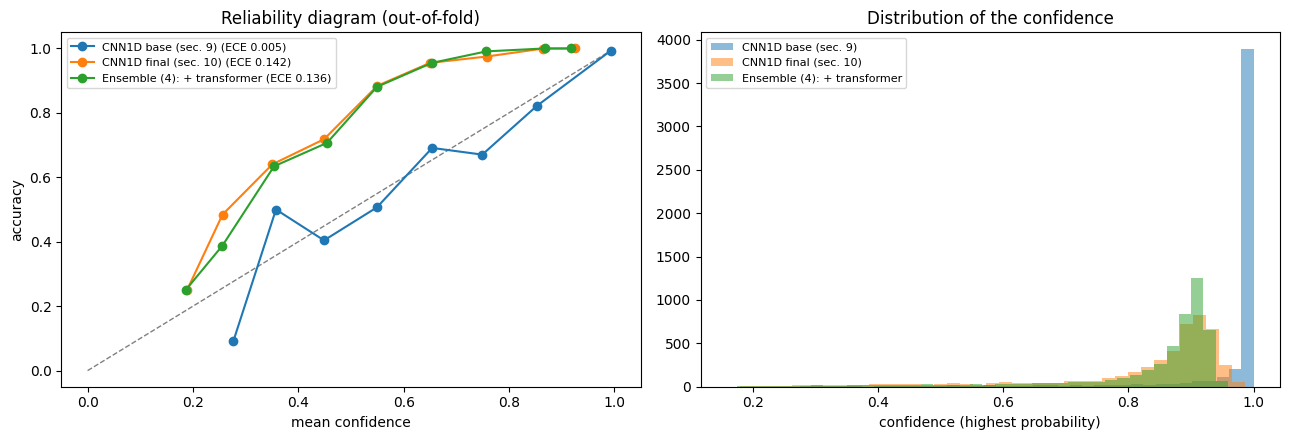

5% least confident predictions: accuracy 0.596 (rest: 0.993), they contain 76% of the errors
10% least confident predictions: accuracy 0.746 (rest: 0.999), they contain 96% of the errors


In [ ]:
def reliability(proba, n_bins=10):
    conf, ok = proba.max(axis=1), proba.argmax(axis=1) == y_train
    idx = np.clip((conf * n_bins).astype(int), 0, n_bins - 1)
    groups = [b for b in range(n_bins) if (idx == b).any()]
    c = np.array([conf[idx == b].mean() for b in groups])
    a = np.array([ok[idx == b].mean() for b in groups])
    w = np.array([(idx == b).mean() for b in groups])
    return c, a, w, np.sum(w * np.abs(a - c))


calib_models = [n for n in ['CNN1D base (sec. 9)', REF, FINAL] if n in OOF_PROBA]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot([0, 1], [0, 1], color='grey', ls='--', lw=1)
for n in calib_models:
    c, a, w, ece = reliability(OOF_PROBA[n])
    axes[0].plot(c, a, marker='o', label=f'{n} (ECE {ece:.3f})')
    axes[1].hist(OOF_PROBA[n].max(axis=1), bins=40, alpha=0.5, label=n)
axes[0].set_xlabel('mean confidence')
axes[0].set_ylabel('accuracy')
axes[0].set_title('Reliability diagram (out-of-fold)')
axes[0].legend(fontsize=8)
axes[1].set_xlabel('confidence (highest probability)')
axes[1].set_title('Distribution of the confidence')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

conf, ok = OOF_PROBA[FINAL].max(axis=1), OOF_PRED[FINAL] == y_train
for q in [0.05, 0.10]:
    t = np.quantile(conf, q)
    print(f'{q:.0%} least confident predictions: accuracy {ok[conf <= t].mean():.3f} '
          f'(rest: {ok[conf > t].mean():.3f}), they contain {(~ok & (conf <= t)).sum() / (~ok).sum():.0%} of the errors')

## 12.3 Where the network looks: Grad-CAM

**Grad-CAM** (gradient-weighted class activation mapping) shows which parts of the input a convolutional network uses for its decision. It takes the feature maps of the last convolutional layer (here 128 maps over 100 frequency positions), weights each map by how much the score of the predicted class changes when that map changes (the average gradient), and sums them. The result is a curve over frequency: high values mark the regions that pushed the network towards its prediction.

Grad-CAM needs a trained model, and the cross-validation only kept predictions, so one CNN1D with the final configuration is trained on the training part of fold 0 (about one minute) and explained on the validation samples of fold 0. For each class, the curves of its correctly classified samples are averaged and normalised. The red marks show the sub-bands where the code of the class has a notch (bit = 1). If the network has learned the physics, it should look at the sub-bands, and especially around the notch frequencies, rather than at unrelated regions. If the final model is an ensemble, this explains its CNN1D member; the EfficientNet would need a 2D version of the method.

Model for the analysis, fold 0 validation accuracy: 0.9552


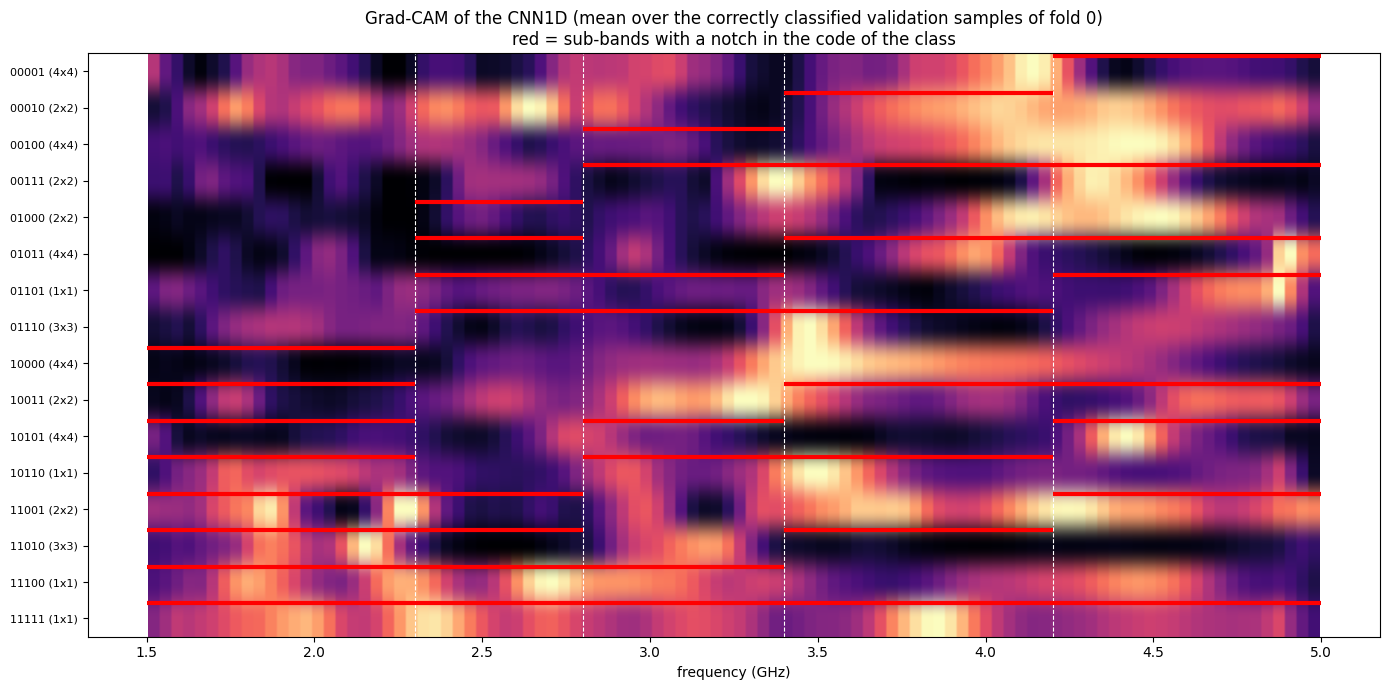

Share of the Grad-CAM weight inside the notch sub-bands: 50.0% (these sub-bands cover 50.0% of the spectrum on average)


In [ ]:
tr0, va0, X_tr0, X_va0 = get_fold(0)
mu0, sd0 = fit_feature_stats(X_train_ds[tr0])
fit0, es0 = train_test_split(np.arange(len(tr0)), test_size=0.1, stratify=y_train[tr0], random_state=SEED)
Y_tr0 = np.eye(N_CLASSES, dtype=np.float32)[y_train[tr0]]
cam_model, _ = fit_arch(build_cnn1d_cfg, FINAL_CFG, X_tr0[fit0], Y_tr0[fit0], X_tr0[es0], Y_tr0[es0], mu0, sd0)
X_va0 = X_va0.astype(np.float32)
y_va0 = y_train[va0]
p_va0 = cam_model.predict(X_va0, batch_size=256, verbose=0)
print(f'Model for the analysis, fold 0 validation accuracy: {(p_va0.argmax(axis=1) == y_va0).mean():.4f}')

last_conv = [l for l in cam_model.layers if isinstance(l, layers.Conv1D)][-1]
grad_model = keras.Model(cam_model.inputs, [last_conv.output, cam_model.output])


def grad_cam(X, cls):
    with tf.GradientTape() as tape:
        A, p = grad_model(tf.convert_to_tensor(X), training=False)
        score = tf.math.log(tf.gather(p, cls, axis=1, batch_dims=1) + 1e-8)
    g = tape.gradient(score, A)
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(g, axis=1, keepdims=True) * A, axis=-1)).numpy()
    return np.repeat(cam, INPUT_SHAPE[0] // cam.shape[1], axis=1)   # back to the 400 frequency bins


correct0 = p_va0.argmax(axis=1) == y_va0
cams = grad_cam(X_va0, y_va0.astype(np.int32))
heat = np.stack([cams[correct0 & (y_va0 == c)].mean(axis=0) for c in range(N_CLASSES)])
heat /= heat.max(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(14, 7))
f0, f1 = freqs_ds[0] / 1e9, freqs_ds[-1] / 1e9
ax.imshow(heat, aspect='auto', cmap='magma', extent=[f0, f1, N_CLASSES - 0.5, -0.5])
for edge in SUBBAND_EDGES_GHZ[1:-1]:
    ax.axvline(edge, color='white', lw=0.8, ls='--')
for r, code_r in enumerate(CODES):
    for i, bit in enumerate(code_r):
        if bit == '1':
            ax.hlines(r - 0.42, SUBBAND_EDGES_GHZ[i], SUBBAND_EDGES_GHZ[i + 1], color='red', lw=3)
ax.set_yticks(range(N_CLASSES))
ax.set_yticklabels([f'{c} ({s})' for c, s in zip(CODES, SIZES)], fontsize=8)
ax.set_xlabel('frequency (GHz)')
ax.set_title('Grad-CAM of the CNN1D (mean over the correctly classified validation samples of fold 0)\n'
             'red = sub-bands with a notch in the code of the class')
plt.tight_layout()
plt.show()

inside = np.zeros((N_CLASSES, INPUT_SHAPE[0]), dtype=bool)
f_ghz = freqs_ds / 1e9
for r, code_r in enumerate(CODES):
    for i, bit in enumerate(code_r):
        if bit == '1':
            inside[r] |= (f_ghz >= SUBBAND_EDGES_GHZ[i]) & (f_ghz < SUBBAND_EDGES_GHZ[i + 1])
share = (heat * inside).sum(axis=1) / heat.sum(axis=1)
width = inside.mean(axis=1)
print(f'Share of the Grad-CAM weight inside the notch sub-bands: {share.mean():.1%} '
      f'(these sub-bands cover {width.mean():.1%} of the spectrum on average)')

## 12.4 How the network organises the tags: t-SNE of the learned features

The last hidden layer of the CNN1D (128 values) is the representation from which the softmax decides the class. **t-SNE** projects these 128-dimensional vectors to 2 dimensions while trying to keep close points close, so it shows which samples the network considers similar. Well separated clusters mean an easy decision; the errors (black crosses) should appear where two clusters touch. The same projection is coloured by distance interval to see whether the distance is still visible in the features, or whether the network has learned to ignore it.

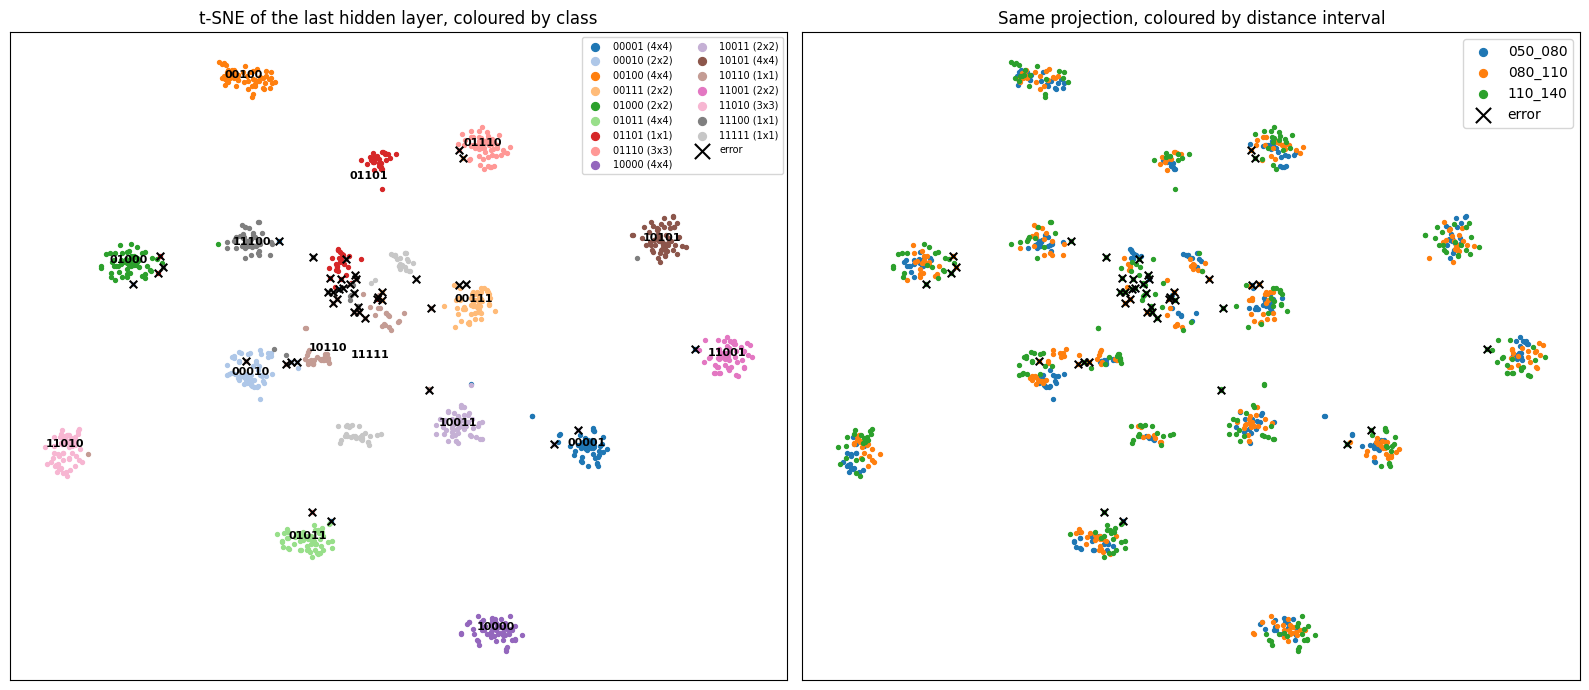

In [ ]:
from sklearn.manifold import TSNE

feature_model = keras.Model(cam_model.inputs, cam_model.layers[-2].output)
F0 = feature_model.predict(X_va0, batch_size=256, verbose=0)
E0 = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(F0)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
cmap = plt.get_cmap('tab20')
for c in range(N_CLASSES):
    m = y_va0 == c
    axes[0].scatter(E0[m, 0], E0[m, 1], s=8, color=cmap(c), label=f'{CODES[c]} ({SIZES[c]})')
    cx, cy = np.median(E0[m], axis=0)
    axes[0].text(cx, cy, CODES[c], fontsize=8, weight='bold', ha='center')
for j, itv in enumerate(INTERVALS):
    m = int_train_idx[va0] == j
    axes[1].scatter(E0[m, 0], E0[m, 1], s=8, label=itv)
for ax in axes:
    ax.scatter(E0[~correct0, 0], E0[~correct0, 1], marker='x', color='black', s=30, label='error')
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].set_title('t-SNE of the last hidden layer, coloured by class')
axes[1].set_title('Same projection, coloured by distance interval')
axes[0].legend(fontsize=7, ncol=2, markerscale=2)
axes[1].legend(markerscale=2)
plt.tight_layout()
plt.show()

## 12.5 A closer look at individual errors

The four errors made with the **highest confidence** by the final model (out-of-fold). For each one, the mean over the 57 scales of its CWT image (the frequency profile) is compared with the average profile of the true class and of the predicted class, measured in the same distance interval. The shaded sub-bands are the bits where the two codes differ: the model had to decide whether there is a notch there.

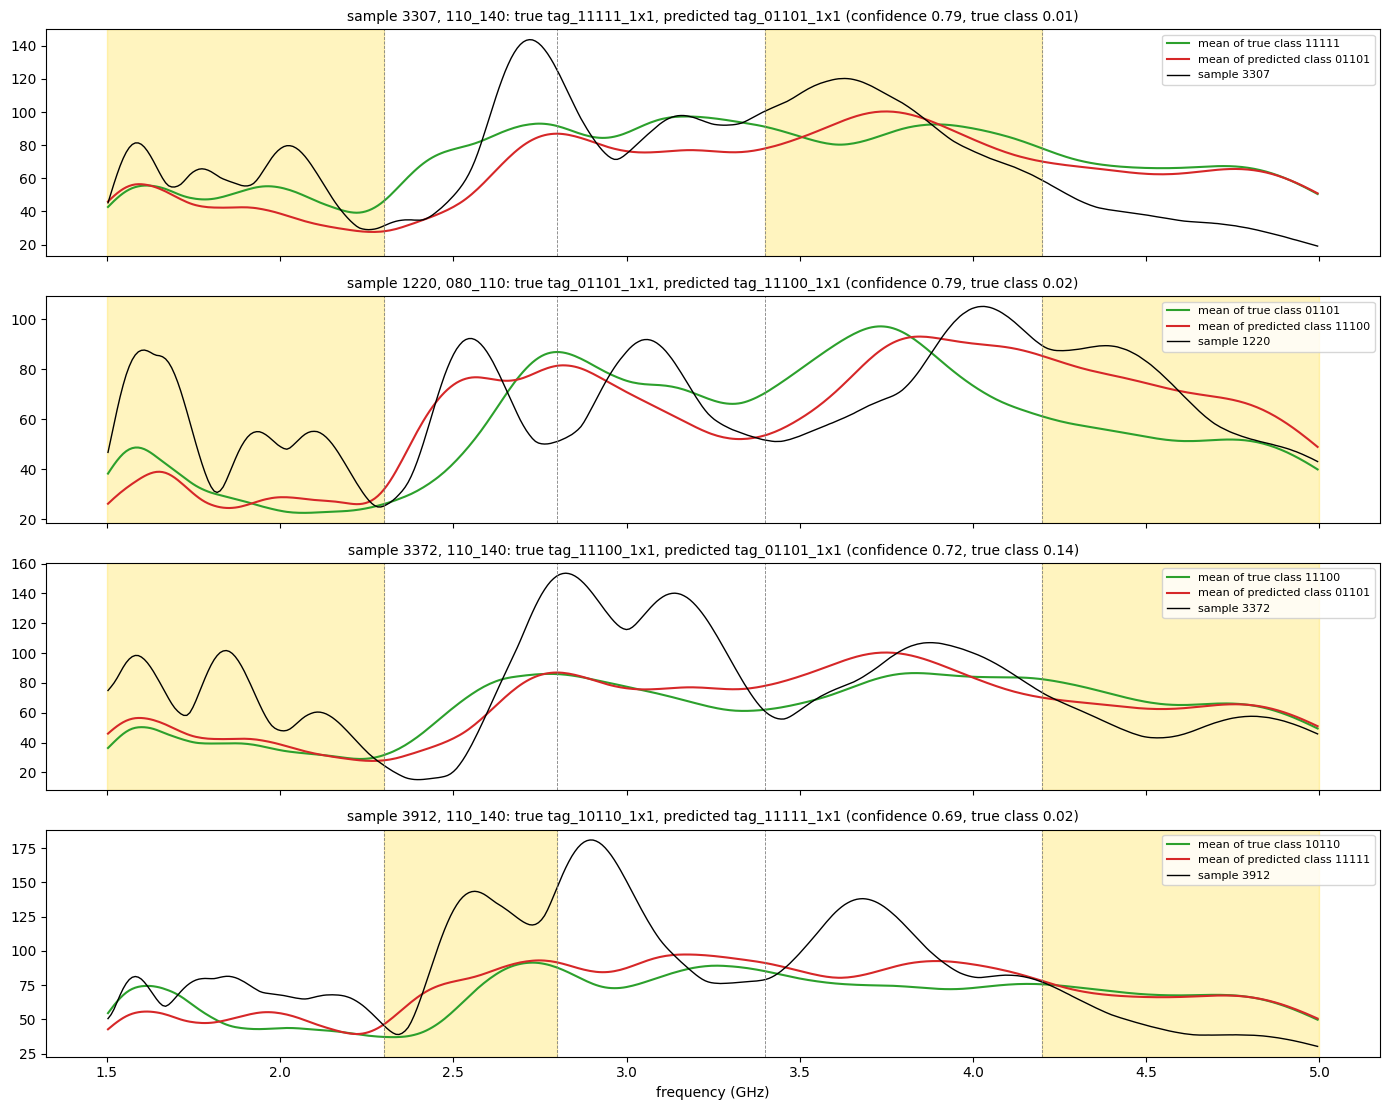

In [ ]:
profile = X_train_ds.mean(axis=2)                         # (n, 400): mean over the CWT scales
wrong = np.where(OOF_PRED[FINAL] != y_train)[0]
worst = wrong[np.argsort(-OOF_PROBA[FINAL][wrong].max(axis=1))][:4]

fig, axes = plt.subplots(len(worst), 1, figsize=(14, 2.8 * len(worst)), sharex=True)
for ax, i in zip(axes, worst):
    t, p, j = y_train[i], OOF_PRED[FINAL][i], int_train_idx[i]
    same_itv = int_train_idx == j
    ax.plot(f_ghz, profile[same_itv & (y_train == t)].mean(axis=0), color='tab:green', lw=1.5, label=f'mean of true class {CODES[t]}')
    ax.plot(f_ghz, profile[same_itv & (y_train == p)].mean(axis=0), color='tab:red', lw=1.5, label=f'mean of predicted class {CODES[p]}')
    ax.plot(f_ghz, profile[i], color='black', lw=1, label=f'sample {i}')
    for b in range(N_BITS):
        if CODES[t][b] != CODES[p][b]:
            ax.axvspan(SUBBAND_EDGES_GHZ[b], SUBBAND_EDGES_GHZ[b + 1], color='gold', alpha=0.25)
    for edge in SUBBAND_EDGES_GHZ[1:-1]:
        ax.axvline(edge, color='grey', lw=0.6, ls='--')
    ax.set_title(f'sample {i}, {INTERVALS[j]}: true {CLASS_NAMES[t]}, predicted {CLASS_NAMES[p]} '
                 f'(confidence {OOF_PROBA[FINAL][i, p]:.2f}, true class {OOF_PROBA[FINAL][i, t]:.2f})', fontsize=10)
    ax.legend(fontsize=8, loc='upper right')
axes[-1].set_xlabel('frequency (GHz)')
plt.tight_layout()
plt.show()

## 12.6 Conclusions of the analysis

1. **The errors are concentrated in the 1x1 tags at long distance.** Accuracy per tag size: 1x1 93.8%, 2x2 97.9%, 3x3 99.2%, 4x4 98.9%. In the far interval the 1x1 tags drop to 88.5%. The 4 tags of size 1x1 account for about 60% of all the errors, and the three most frequent confusions are between them (11100 <-> 01101, 11111 -> 01101). Our interpretation: a 1x1 tag has a single small resonator, which produces a weaker notch, and at long distance the noise is of the same size as the notch.
2. **Almost all errors are at the minimum distance allowed by the code.** 84% of the errors confuse codes that differ in 2 bits, the minimum Hamming distance of the 16 codes (odd parity), and 16% codes 4 bits apart. The model never confuses codes that differ in a single bit, because no two tags do. When it fails, it misreads two notches at once, typically one appearing and one disappearing.
3. **The confidence can be used to flag doubtful readings.** The model trained without label smoothing is over-confident: almost all of its predictions have confidence close to 1, including the wrong ones (ECE 0.065). With label smoothing the model becomes under-confident: at confidence 0.9 it is right almost 100% of the time (ECE 0.14). The calibration error is larger, but the ranking of the predictions is very good. The 10% least confident predictions contain 96% of the errors, and the remaining 90% are 99.9% correct. In practice a reader could ask for a second measurement in those 10% of cases. A temperature scaling of the probabilities would fix the calibration without changing any prediction.
4. **The network reads the whole spectrum, not only the notches.** Grad-CAM shows that each class has its own regions of high attention, but on average only 50% of the attention falls in the sub-bands where the class has a notch, the same share those sub-bands occupy in the spectrum. This does not mean the network ignores the physics: to decide that a bit is 0, it has to check that there is no notch in that sub-band, so the sub-bands without a notch are just as informative. Limitations: the map comes from a single CNN1D (fold 0) and has a resolution of 100 positions (35 MHz).
5. **The learned features do not depend on the distance.** In the t-SNE of the last hidden layer the 16 tags form separate clusters, except for a central region where the 1x1 tags (01101, 11100, 11111, 10110) overlap, which is where almost all the errors are. Coloured by interval, the three distances are mixed inside every cluster. The network maps a tag to the same place regardless of the distance, which explains why giving it the interval as an input did not help (section 9.3).
6. **The worst errors are measurements where the noise is larger than the difference between two tags.** The four errors made with the highest confidence are 1x1 tags, three of them in the far interval, predicted with moderate confidence (0.69-0.79). The average profiles of the true and the predicted class are almost on top of each other, while the misclassified samples show oscillations much larger than the class averages, especially in 1.5-2.3 GHz (bit 1). Those oscillations imitate or hide a notch. Some of these measurements are probably not recognisable from the signal alone.

**Overall.** The final model, the ensemble of four networks chosen in section 11.1 (CNN1D final, EfficientNetV2-B0 pre-trained on ImageNet, EfficientNetV2-B0 from random weights and CNN1D with transformer), reaches **97.4%** in cross-validation (estimated 95-97% on the test set), up from 91.2% for the best classical baseline and 96.0% for the first neural networks. The remaining errors are not random: they are concentrated in the smallest tags, the farthest measurements and the lowest sub-band, and they are flagged by a low confidence. Further improvements would most likely need better measurements (or several measurements per reading) for those cases rather than a different model.

# 13. Final conclusions

The table below summarises the path from the best classical baseline to the final model; every number is a 5-fold cross-validation accuracy computed on the same folds.

**What worked**
1. **Learned models instead of hand-made rules.** Comparing with the clean reference signatures, the classical signal-processing approach, only reaches 61%. A nearest-neighbour search on the training measurements reaches 91.2%, and the first neural networks 96.0%. The largest gain is at long distance (85.6% to 92%).
2. **A 1D CNN along the frequency axis.** It matches the MLP with 3 times fewer parameters and beats the 2D CNN by 1.5 points. The scale-shuffling ablation shows why: the information is *where along frequency* the response changes, and the 57 CWT scales behave as unordered channels.
3. **Predicting the class directly.** Predicting the 5 bits needs a maximum-likelihood decoder to be competitive (+2.6 points), and even then it stays below the direct 16-class output. Combining both outputs in a multi-task network does not help either.
4. **Label smoothing.** It is the only training change that helped clearly and consistently across two runs (+0.35 and +0.50 points): it stops the network from memorising the training set and becoming over-confident between very similar tags.
5. **An ensemble of different networks.** Averaging a 1D CNN, two EfficientNets and a CNN with transformer layers gives **97.4%**, improves all 5 folds and reduces the errors from 161 to 127. Members that are weaker on their own still help, because they fail on different measurements.

**What did not work, and why**
- Data augmentation, the distance interval as an input, weight decay and the Optuna search change the accuracy by less than the run-to-run noise (about 0.3 points). With 300 real measurements per tag the network is not short of data or variability, and it already infers the distance from the signal.
- Self-attention (transformer layers) and pseudo-labelling with the test set lowered the accuracy by about 0.5 points. ImageNet pre-training helps a large 2D network (+0.4 points over random weights) but only brings it level with the much smaller 1D CNN.

**Where the remaining errors are.** About 60% of the errors come from the four 1x1 tags, mostly in the 110-140 cm interval (88.5% accuracy for these tags at that distance) and in the lowest sub-band (1.5-2.3 GHz). These tags have a single small resonator and produce weak notches; in the worst cases the measurement noise is larger than the difference between two tags. The errors are flagged by a low confidence: the 10% least confident predictions contain 96% of the errors.

**Limitations**
- Training on the GPU is not exactly deterministic: two runs of the same model differ by up to about 0.3 points, so smaller differences between models are not meaningful. This is why every change also had to improve most of the folds.
- The final model was chosen among three ensembles using the same cross-validation results, so its 97.4% is slightly optimistic. From the confidence of the test predictions we estimate a test accuracy between 95% and 97%.
- The hyper-parameter search was limited to 30 minutes and two folds.

**Future work.** The remaining errors are a measurement problem more than a modelling one. Averaging several measurements per reading, re-measuring the readings with low confidence, or collecting more data of the small tags at long distance should help more than a larger network. Calibrating the probabilities (temperature scaling) would make the confidence directly usable as a reliability score.

**Deliverables.** `test_predictions.txt` (2,400 labels, one per line, in the order of the test file) contains the predictions of the final ensemble. `optuna_best_params_cnn1d.json` stores the result of the hyper-parameter search, and `test_proba_final.npy` the predicted probabilities.

,mean acc,std acc,050_080,080_110,110_140,errors
Best baseline: 1-NN (correlation),0.9117,0.0067,0.9675,0.9119,0.8556,424
First neural network: CNN1D-A,0.9596,0.0028,0.9881,0.9725,0.9181,194
Best training recipe (section 9),0.9660,0.0039,0.9919,0.9794,0.9269,163
Final recipe re-trained (section 10),0.9665,0.0034,0.9900,0.9756,0.9337,161
Transfer learning: EfficientNetV2-B0 (ImageNet),0.9660,0.0040,0.9875,0.9812,0.9294,163
Final model: ensemble of 4 networks,0.9735,0.0025,0.9931,0.9819,0.9456,127


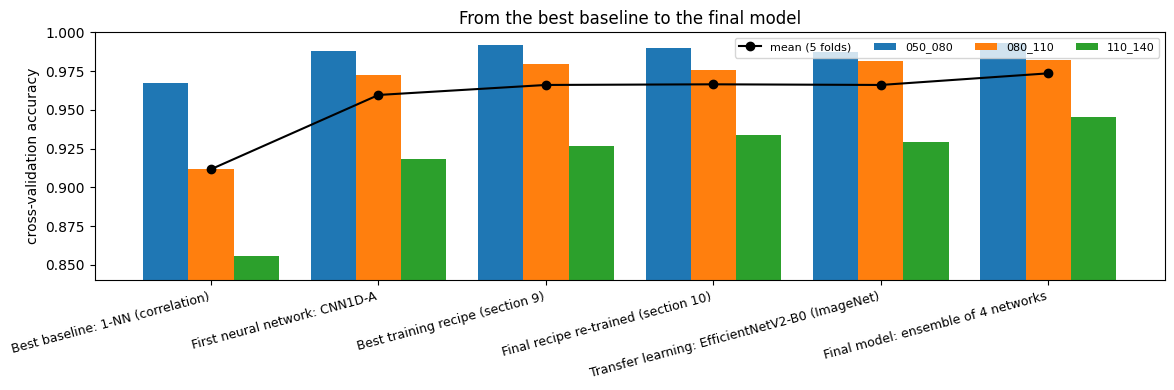

In [ ]:
JOURNEY = {
    'Best baseline: 1-NN (correlation)': '1-NN (correlation)',
    'First neural network: CNN1D-A': 'CNN1D-A',
    'Best training recipe (section 9)': MANUAL_BEST,
    'Final recipe re-trained (section 10)': REF,
    'Transfer learning: EfficientNetV2-B0 (ImageNet)': PRETRAINED,
    'Final model: ensemble of 4 networks': FINAL,
}
journey = pd.DataFrame({label: {'mean acc': RESULTS[n]['mean acc'], 'std acc': RESULTS[n]['std acc'],
                                **{itv: RESULTS[n][itv] for itv in INTERVALS},
                                'errors': int((OOF_PRED[n] != y_train).sum())}
                        for label, n in JOURNEY.items()}).T
display(journey.style.format({c: '{:.4f}' for c in ['mean acc', 'std acc'] + INTERVALS} | {'errors': '{:.0f}'}))

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(journey))
for j, itv in enumerate(INTERVALS):
    ax.bar(x + (j - 1) * 0.27, journey[itv], width=0.27, label=itv)
ax.plot(x, journey['mean acc'], color='black', marker='o', label='mean (5 folds)')
ax.set_xticks(x)
ax.set_xticklabels(journey.index, rotation=15, ha='right', fontsize=9)
ax.set_ylim(0.84, 1.0)
ax.set_ylabel('cross-validation accuracy')
ax.set_title('From the best baseline to the final model')
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()